# Acetaldehyde delay scans

FLASH2, beamtime 11024642. Adapted from `inspect_delay_scan.ipynb`: config 1 `time_resolved` aggregates (GMD × delay × TOF).

Select one photon energy and compatible scans below; run from the repository root or `analysis/notebooks`. Delay and TOF binning come from the aggregates. Change their config and regenerate the aggregates for different bin edges; section 4.2 compares coarser delay bins without rewriting data.

`MONITOR` controls the main electron spectra, maps and traces (sections 5, 7 and 8); `USE_READY` selects recorded or dead-time-corrected electron means. `NORMALISE` controls ion plots only. Acquisition statistics, the explicitly recorded GMD diagnostics, section 4.2 and covariance retain the original hits and moments. Section 4.1 compares both monitors with and without the correction, independent of the main selection, when matching ready files exist. No corrected second moments are available.

The AcH run-60612 VLS calibration is a relative reference from the latest undulator scan; recheck it after spectrometer movement. Delay sign, time zero and the inherited eTOF calibration need experimental confirmation. Electron windows are KE selections, not assignments of AcH orbitals; ion labels are candidate masses.

First moments are loaded together; second moments are read one GMD-delay cell at a time. No data files are modified.

## 1. Load data

In [485]:
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

repo = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'analysis/scripts/config.py').is_file())
scripts = str(repo / 'analysis/scripts')
if scripts not in sys.path:
    sys.path.insert(0, scripts)

from config import COMBINED_DIR
import calibration

# Keep scans at one photon energy together. Use 268*7eV for the 268.7 eV scans.
SCAN_PATTERN = '*AcH_long*delay_scan_*269.7eV*_aggregates_tr.h5'
FILES = sorted(COMBINED_DIR.glob(SCAN_PATTERN))
# FILES = [COMBINED_DIR / 'AcH_..._aggregates_tr.h5']
# FILES = FILES[-1:]

VLS_CAL_FILE = COMBINED_DIR / 'run60612_AcH_undulator_scan_part2_265-280eV_2809782740.h5'

GMD_BINS = None             # None: all; indices refer to each scan's own edges
FS_PER_STAGE_UNIT = 0.349 / 1000
Z_ZERO = 0                   # stage units
DELAY_SIGN = 1
NORMALISE = 'per_uJ'         # ions: 'per_uJ' or 'per_shot'
DELAY_BASELINE = None        # None: all delays; or (lo, hi) in fs

# Main electron spectra and traces (sections 5, 7 and 8).
MONITOR = 'vls'              # 'vls', 'gmd', 'shot'
USE_READY = True           # set True once every selected scan has a valid ready file
TAU_NS = 6                  # ns; check the plateau in section 4.1 before choosing
MONITOR_WINDOWS = [(10, 40), (210, 240), (240, 265)]
READY_WINDOWS = [(10, 40), (210, 285)]  # KE windows for the tau diagnostic
RUN_READY_DIAGNOSTICS = True

SCAN_MINUTES = {}
TRAIN_RATE = 10              # Hz
RUN_TIME_DIAGNOSTIC = False  # rereads combined files with the separate cuts stated below
RUN_FINE_IONS = False        # rereads combined files for a finer ion histogram

print(f'{len(FILES)} files selected:')
for path in FILES:
    print(path.name)

3 files selected:
AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5


In [486]:
# Plot windows and selection settings
# KE windows are inherited starting points; inspect the AcH spectra.

COUNT_ROI = (220, 263)

STABILITY_WINDOWS = [(0, 100), (110, 160),
                     (210, 220), (220, 230),
                     (230, 240), (242, 246),
                     (246, 250), (250, 263)]

RELATIVE = False

TIME_BIN_S = 30

CHUNK_TRAINS = 250

TIME_WINDOWS = [(0, 100), (210, 263)]

STAT_WINDOWS = [
    (220, 263),
    (220, 240),
    (242, 246),
    (250, 263)
]

STAT_SIGNAL_PERCENT = 1.0

STAT_TARGET_SNR = 3

DELAY_REBIN_FACTORS = [1, 2, 3, 4]

KE_LIM = (0, 290)

MQ_LIM = (0, 50)

MIN_REF_COUNTS = 100         # mask weak spectral bins in relative maps (reference interval)

REL_LIM = 0.10               # symmetric colour limits for relative maps

VMIN = 1e-5

VMAX = 5e-2

VLS_VMIN = None             # map colour limits for VLS units; None = automatic
VLS_VMAX = None

M_AR = 39.962

Q_MAX = 10

OTHER_IONS = {
    'H+': 1.008, 'H2+': 2.016, 'C+': 12.000,
    'CH3+': 15.023, 'O+': 15.995, 'H2O+': 18.011,
    'N2+ / CO+': 28.0, 'CHO+': 29.0, 'O2+': 31.990,
    'C2H3O+': 43.018, 'C2H4O+ / CO2+': 44.0
}

FIT_BIN = 1                 # ns; try 0.5 or 0.1 for finer binning

TOF_RANGE_I = (200, 3400)   # ns

MAX_ION_HITS = 30           # same burst-shot cut as the Argon notebook

ENERGY_WINDOWS = [
    (110, 160),
    (210, 220),
    (220, 230),
    (230, 240),
    (242, 246),
    (246, 250),
    (250, 263),
]

RELATIVE_TRACES = True

SHOW_ORIGIN = True

MIN_SHOTS = 100

ION_YIELD_WINDOWS = [(0.5, 1.5), (12, 16), (19, 21), (27, 32), (43, 45)]

GMD_ENERGY_WINDOWS = [(240, 242), (242, 246), (246, 249), (249, 253), (253, 259), (259, 265)]

GMD_RELATIVE = True

COV_FILES = FILES

COV_GMD_BINS = GMD_BINS

REBIN_E = 1

REBIN_I = 2

MIN_COV_SHOTS = 300

CLIP_PCT = 99.5

Z_MAX = 6

WINDOW_EST = 'partial on GMD'

DEAD_TIME_NS = 6.0           # pair exclusion, not a correction for lost pairs

DT_STEP = 0.1       # ns

DT_MAX = 10        # ns

DEAD_TIME_KE = (210, 265)

COV_DELAY_WINDOW = None

COV_KE_LIM = (200, 275)

COV_MQ_LIM = (0, 50)

COV_E_WINDOWS = [(242, 246), (246, 249), (249, 253), (253, 259)]

COV_ION_WINDOWS = [(0.5, 1.5), (13, 16), (27, 32), (43, 45)]

COV_DENSITY = True

E_GATE = (242, 246)         # inspect the AcH spectrum before assigning this region

I_GATE = (27, 32)

EE_ROIS = [
    ((242, 246), (180, 200)),
    ((242, 246), (200, 210)),
    ((246, 249), (180, 200)),
    ((246, 249), (200, 210)),
    ((250, 260), (180, 200))
]

EI_ROIS = [
    ((220, 240), (0.5, 1.5)),
    ((220, 240), (12, 16)),
    ((220, 240), (19, 21)),
    ((220, 240), (27, 32)),
    ((220, 240), (43, 45))
]

COV_NORMALISE_GMD = False

PHOTOELECTRON_ROI = (242, 246)

PAIR_SECOND_ROI = (180, 200)  # separated from the fast gate for a 6 ns cut

In [487]:
# Read only the first moments and bin edges. D, C and G are means per shot.
if not FILES:
    raise FileNotFoundError('No delay aggregates found in ' + str(COMBINED_DIR))

scans = {}
axes = {}
for path in FILES:
    path = Path(path)
    with h5py.File(path, 'r') as f:
        if f.attrs['config'] != 1 or f.attrs['mode'] != 'time_resolved':
            raise ValueError(f'{path.name}: expected config 1 time_resolved aggregates')
        edges = {key: f[key][:] for key in ('z_edges', 'tof_edges', 'ion_tof_edges')}
        if not axes:
            axes = edges
        elif any(not np.array_equal(edges[key], axes[key]) for key in axes):
            raise ValueError(f'{path.name}: different delay or TOF edges. Select compatible scans.')

        n = f['n_per_bin'][:]
        D, C, G = f['D'][:], f['C'][:], f['G'][:]
        gmd_edges = f['gmd_edges'][:]
        attrs = dict(f.attrs)

    # Empty cells contain NaNs. Ignore them, not NaNs in populated cells.
    if any(not np.isfinite(a[n > 0]).all() for a in (D, C, G)):
        raise ValueError(f'{path.name}: non-finite means in populated bins')
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, D, C, G = n[bins], D[bins], C[bins], G[bins]
    # Convert means to sums before collapsing the GMD dimension.
    e = np.where(n[..., None] > 0, D, 0) * n[..., None]
    i = np.where(n[..., None] > 0, C, 0) * n[..., None]
    g = np.where(n > 0, G, 0) * n

    # Acquisition duration: read just the two train-ID endpoints.
    minutes = SCAN_MINUTES.get(path.name, np.nan)
    source = Path(attrs.get('input_h5', ''))
    if not source.is_absolute():
        source = repo / source
    if not source.is_file():
        source = COMBINED_DIR / path.name.replace('_aggregates_tr.h5', '.h5')
    if not np.isfinite(minutes) and source.is_file():
        with h5py.File(source, 'r') as f:
            if 'tID' in f and len(f['tID']):
                minutes = (int(f['tID'][-1]) - int(f['tID'][0]) + 1) / TRAIN_RATE / 60

    scans[path.name] = dict(n=n.sum(axis=0), e=e.sum(axis=0),
                            i=i.sum(axis=0), g=g.sum(axis=0),
                            minutes=minutes, gmd_edges=gmd_edges, attrs=attrs)
    s = scans[path.name]
    print(f'\n{path.name}')
    print(f'  shots = {s["n"].sum():,}; e = {s["e"].sum():,.0f}; i = {s["i"].sum():,.0f}')
    print(f'  occupied delay bins = {np.count_nonzero(s["n"])} / {len(s["n"])}; time = {minutes:.1f} min')
    print('  GMD edges (uJ):', np.round(gmd_edges, 3))
    print('  skipped z outside / NaN:', attrs.get('n_skipped_z_oor', '?'), attrs.get('n_skipped_z_nan', '?'))
    print('  skipped max hits:', attrs.get('n_skipped_max_hits', '?'))

# GMD percentile edges can differ by file. Pool counts, not means.
combined = {key: np.sum([s[key] for s in scans.values()], axis=0)
            for key in ('n', 'e', 'i', 'g')}
combined['minutes'] = sum(s['minutes'] for s in scans.values())
scans_raw, combined_raw = scans, combined
if GMD_BINS is not None:
    print("Note: selected GMD indices refer to each scan's own edges.")


AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5
  shots = 2,459,088; e = 2,894,754; i = 1,299,142
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.109 0.207 0.346 0.583 4.446]
  skipped z outside / NaN: 0 0
  skipped max hits: 38

AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5
  shots = 2,457,818; e = 2,840,521; i = 1,287,355
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.106 0.201 0.335 0.563 4.439]
  skipped z outside / NaN: 0 0
  skipped max hits: 501

AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5
  shots = 2,453,743; e = 2,778,720; i = 1,242,309
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.102 0.195 0.325 0.546 4.597]
  skipped z outside / NaN: 0 0
  skipped max hits: 48


## 2. Calibrated axes

TOF is saved in 100 ps units; the calibration functions take ns. Transform bin edges (not just centres), reverse the electron spectrum, and divide by the actual widths for spectral density plots. Counts for statistics and integration are kept as counts/bin.

The delay conversion follows the supplied SDU configuration. Its sign and time zero still need experimental confirmation. The delay step is not the temporal resolution.

In [488]:
if DELAY_SIGN not in (-1, 1):
    raise ValueError('DELAY_SIGN must be +1 or -1')

z_edges = axes['z_edges']
delay_edges = DELAY_SIGN * (z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
ke_edges = calibration.ke_of_tof(axes['tof_edges'] / 10)[::-1]
mq_edges = calibration.mq_of_tof(axes['ion_tof_edges'] / 10)

# Keep all plotted axes increasing. Copy dictionaries so this cell can be rerun.
scans = {name: dict(s) for name, s in scans_raw.items()}
combined = dict(combined_raw)
for s in [*scans.values(), combined]:
    s['e'] = s['e'][:, ::-1]
    if DELAY_SIGN == -1:
        for key in ('n', 'e', 'i', 'g'):
            s[key] = s[key][::-1]
if DELAY_SIGN == -1:
    delay_edges = delay_edges[::-1]

delay = (delay_edges[:-1] + delay_edges[1:]) / 2
ke = (ke_edges[:-1] + ke_edges[1:]) / 2
mq = (mq_edges[:-1] + mq_edges[1:]) / 2
dke, dmq = np.diff(ke_edges), np.diff(mq_edges)

if any(np.any(~np.isfinite(edges)) or np.any(np.diff(edges) <= 0)
       for edges in (delay_edges, ke_edges, mq_edges)):
    raise ValueError('Calibrated edges must be finite and increasing')

# Safe division: empty exposure gives NaN, not zero signal.
def divide(a, b):
    a, b = np.broadcast_arrays(a, b)
    return np.divide(a, b, out=np.full(a.shape, np.nan, dtype=float), where=b > 0)

exposure_key = {'per_uJ': 'g', 'per_shot': 'n'}[NORMALISE]
unit = {'per_uJ': r'$\mu$J', 'per_shot': 'shot'}[NORMALISE]

print(f'Delay: {delay_edges[0]:.3f} to {delay_edges[-1]:.3f} fs, {len(delay)} bins')
print('Delay bin widths (fs):', np.unique(np.round(np.diff(delay_edges), 6)))
print(f'KE: {ke_edges[0]:.2f} to {ke_edges[-1]:.2f} eV')
print(f'm/q: {mq_edges[0]:.2f} to {mq_edges[-1]:.2f} u/e')

Delay: -4.889 to 59.333 fs, 32 bins
Delay bin widths (fs): [2.006968]
KE: 1.00 to 290.29 eV
m/q: 0.21 to 50.43 u/e


### Delay reference

Relative signals are measured against the exposure-weighted mean in the selected delay interval, not a pump-off spectrum.

In [489]:
if DELAY_BASELINE is None:
    ref_mask = np.ones(len(delay), dtype=bool)
else:
    lo, hi = DELAY_BASELINE
    ref_mask = (delay >= lo) & (delay < hi)

if not ref_mask.any():
    raise ValueError('No bins in the selected delay reference')

def delay_reference(counts, exposure):
    return divide(counts[ref_mask].sum(axis=0),
                  exposure[ref_mask].sum())

idx = np.flatnonzero(ref_mask)
print(f'Reference: {delay_edges[idx[0]]:.2f} to '
      f'{delay_edges[idx[-1]+1]:.2f} fs')

Reference: -4.89 to 59.33 fs


## 3. Acquisition statistics

Counts are reconstructed after the aggregation cuts, within the recorded TOF range. They are detected hits, not incident electrons or the number of coincidence events.

The high-energy electron ROI includes direct photoelectrons as well as possible Auger signal; it is not a pure Auger yield.

Shots            total    7,370,649 | min  228,596 | median  230,389 | max  231,369
Recorded electron counts total    8,513,995 | min  234,264 | median  263,981 | max  304,146
Recorded electron ROI counts total    2,422,127 | min   67,027 | median   75,734 | max   83,937
Ion counts       total    3,828,806 | min  105,445 | median  119,002 | max  134,424


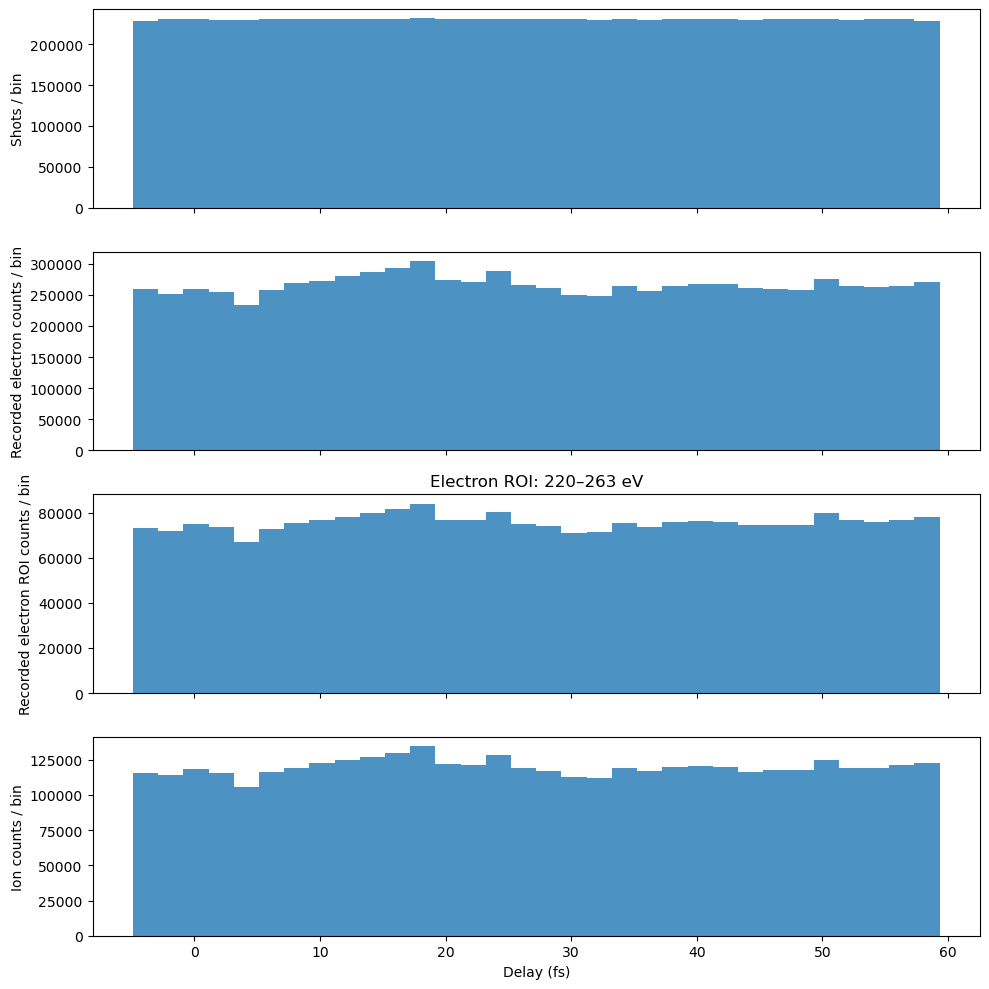

In [490]:
mask = (ke >= COUNT_ROI[0]) & (ke < COUNT_ROI[1])
if not mask.any():
    raise ValueError(f'No electron bins in {COUNT_ROI} eV')
roi_counts = combined['e'][:, mask].sum(axis=1)

fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True)

for a, y, label in zip(ax, [combined['n'], combined['e'].sum(axis=1), roi_counts,
                           combined['i'].sum(axis=1)],
                      ['Shots', 'Recorded electron counts', 'Recorded electron ROI counts', 'Ion counts']):
    a.bar(delay, y, width=np.diff(delay_edges), alpha=0.8)
    a.set_ylabel(label + ' / bin')
    print(f'{label:16s} total {y.sum():12,.0f} | min {y.min():8,.0f} | '
          f'median {np.median(y):8,.0f} | max {y.max():8,.0f}')

ax[2].set_title(f'Electron ROI: {COUNT_ROI[0]}–{COUNT_ROI[1]} eV')
ax[-1].set_xlabel('Delay (fs)')
fig.tight_layout()
plt.show()

## 4. FEL stability

Per-µJ normalisation is a useful diagnostic but does not correct nonlinear detector response or changing GMD distributions. Ion detection also depends on bunch position (see handover).

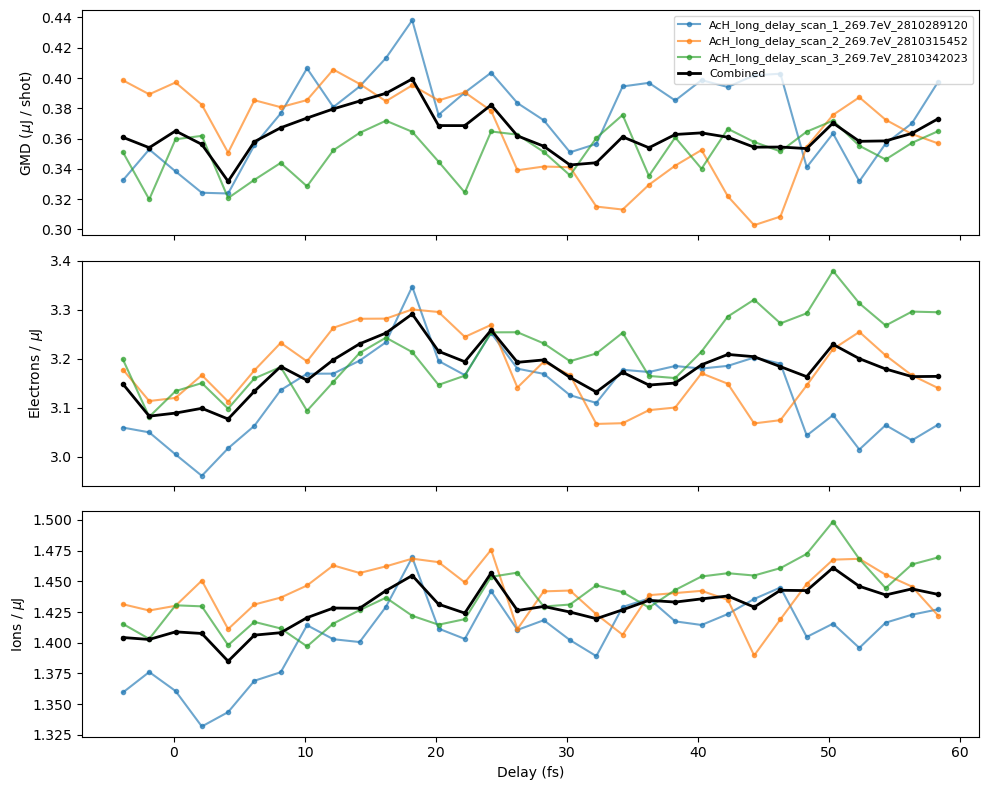

In [491]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for name, s in [*scans.items(), ('Combined', combined)]:
    label = 'Combined' if name == 'Combined' else name.replace('_aggregates_tr.h5', '')
    style = dict(color='k', linewidth=2) if name == 'Combined' else dict(alpha=0.65)
    ax[0].plot(delay, divide(s['g'], s['n']), '.-', label=label, **style)
    ax[1].plot(delay, divide(s['e'].sum(axis=1), s['g']), '.-', **style)
    ax[2].plot(delay, divide(s['i'].sum(axis=1), s['g']), '.-', **style)

ax[0].set_ylabel(r'GMD ($\mu$J / shot)')
ax[1].set_ylabel(r'Electrons / $\mu$J')
ax[2].set_ylabel(r'Ions / $\mu$J')
ax[0].legend(fontsize=8)
ax[-1].set_xlabel('Delay (fs)')
fig.tight_layout()
plt.show()

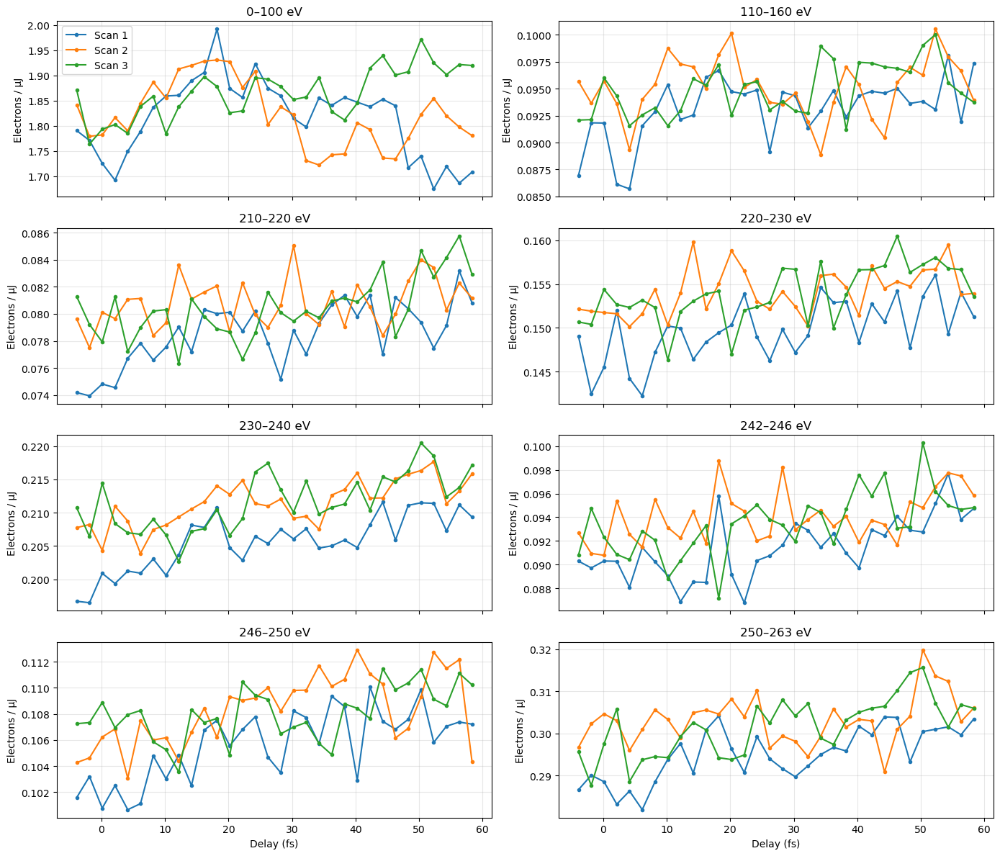

In [492]:
# Recorded electron yield stability in different KE regions



fig, ax = plt.subplots(4, 2, figsize=(14, 12),
                       sharex=True)

for a, (lo, hi) in zip(ax.flat, STABILITY_WINDOWS):

    mask = (ke >= lo) & (ke < hi)

    if not mask.any():
        a.set_title(f'{lo}–{hi} eV: no bins')
        continue

    for i, (name, s) in enumerate(scans.items()):

        counts = s['e'][:, mask].sum(axis=1)
        y = divide(counts, s['g'])

        if RELATIVE:
            ref = divide(counts.sum(), s['g'].sum())
            y = 100 * (divide(y, ref) - 1)

        a.plot(delay, y, 'o-', ms=3,
               label=f'Scan {i+1}')


    if RELATIVE:
        a.axhline(0, color='k', ls='--', alpha=0.5)

    a.set_title(f'{lo}–{hi} eV')
    a.set_ylabel('Relative yield (%)' if RELATIVE
                 else 'Electrons / µJ')
    a.grid(alpha=0.3)

for a in ax[-1]:
    a.set_xlabel('Delay (fs)')

ax[0, 0].legend()
fig.tight_layout()
plt.show()

In [493]:
# Separate selection: finite GMD/z, GMD >= 0.02, aggregate delay range.
# This acquisition-time diagnostic does not reproduce all aggregate cuts.
if RUN_TIME_DIAGNOSTIC:
    # Electron and ion yields versus acquisition time



    tof_edges = axes['tof_edges']
    ion_edges = axes['ion_tof_edges']

    # Use the same TOF bins as in the aggregate analysis.
    tof_windows = {}

    for lo, hi in TIME_WINDOWS:

        idx = np.flatnonzero(((ke >= lo) & (ke < hi))[::-1])

        tof_windows[(lo, hi)] = (
            tof_edges[idx[0]],
            tof_edges[idx[-1] + 1]
        )

    fig, ax = plt.subplots(5, 1, figsize=(12, 13),
                           sharex=True)

    for i, path in enumerate(FILES):

        source = COMBINED_DIR / path.name.replace(
            '_aggregates_tr.h5', '.h5')

        print(f'\n{source.name}')

        with h5py.File(source, 'r') as f:

            tid = f['tID'][:]
            time_s = (tid - tid[0]) / TRAIN_RATE

            time_edges = np.arange(
                0, time_s.max() + TIME_BIN_S, TIME_BIN_S)

            time = (time_edges[:-1] + time_edges[1:]) / 2
            nt = len(time)

            n_time = np.zeros(nt)
            g_time = np.zeros(nt)
            z_time = np.zeros(nt)
            ion_time = np.zeros(nt)

            e_time = {roi: np.zeros(nt) for roi in TIME_WINDOWS}

            for start in range(0, len(tid), CHUNK_TRAINS):

                sl = slice(start, start + CHUNK_TRAINS)

                g = f['gmd'][sl]
                z = f['z'][sl]
                e = f['tofs_e'][sl]
                ions = f['tofs_i'][sl]#

                valid = (np.isfinite(g) &
                         np.isfinite(z) &
                         (g >= 0.02) &
                         (z >= z_edges[0]) &
                         (z <= z_edges[-1]))

                ibin = np.searchsorted(
                    time_edges, time_s[sl], side='right') - 1

                ibin = np.clip(ibin, 0, nt - 1)

                np.add.at(n_time, ibin, valid.sum(axis=1))

                np.add.at(g_time, ibin,
                          np.where(valid, g, 0).sum(axis=1))

                np.add.at(z_time, ibin,
                          np.where(valid, z, 0).sum(axis=1))

                for roi, (lo, hi) in tof_windows.items():

                    counts = ((e > 0) &
                              (e >= lo) &
                              (e < hi)).sum(axis=-1)

                    counts = np.where(valid, counts, 0)

                    np.add.at(e_time[roi], ibin,
                              counts.sum(axis=1))

                counts_i = ((ions > 0) &
                            (ions >= ion_edges[0]) &
                            (ions <= ion_edges[-1])).sum(axis=-1)

                counts_i = np.where(valid, counts_i, 0)

                np.add.at(ion_time, ibin,
                          counts_i.sum(axis=1))

        # Mean delay in each acquisition-time bin
        mean_delay = DELAY_SIGN * (
            divide(z_time, n_time) - Z_ZERO
        ) * FS_PER_STAGE_UNIT

        ax[0].plot(time / 60, mean_delay, '.-',
                   label=f'Scan {i+1}')

        ax[1].plot(time / 60, divide(g_time, n_time), '.-')

        ax[2].plot(time / 60,
                   divide(e_time[(0, 100)], g_time), '.-')

        ax[3].plot(time / 60,
                   divide(e_time[(210, 263)], g_time), '.-')

        ax[4].plot(time / 60,
                   divide(ion_time, g_time), '.-')

        print(f'Acquisition time: {time_s.max()/60:.1f} min')
        print(f'Selected shots: {n_time.sum():,.0f}')
        print(f'Aggregate shots: {scans[path.name]["n"].sum():,.0f}')

    ax[0].set_ylabel('Mean delay (fs)')
    ax[1].set_ylabel('GMD (µJ / shot)')
    ax[2].set_ylabel('0–100 eV\nElectrons / µJ')
    ax[3].set_ylabel('210–263 eV\nElectrons / µJ')
    ax[4].set_ylabel('Ions / µJ')

    ax[-1].set_xlabel('Elapsed acquisition time (min)')

    ax[0].legend()

    for a in ax:
        a.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

### 4.1 FEL spectral stability and normalisation

The VLS spectra use the run-60612 calibration, rather than the old ethanol scan. The map remains ADU per µJ and the integrated spectrum ADU per shot. These are averaged spectra; their FWHM is not the single-shot bandwidth.

VLS exposure is the summed background-subtracted crop in units of 10⁴ ADU. The four-way comparison uses the same selected shots and shows both GMD and VLS normalisation, with and without correction. Each curve has its own exposure-weighted reference over `DELAY_BASELINE`.

`USE_READY=True` applies `D_live` at `TAU_NS` to the main electron spectra and traces. Matching ready files are loaded whenever present, even with `USE_READY=False`, for diagnostics. Generate them with `compute_ready_counts.py` on each time-resolved aggregate. If correction is requested, missing/mismatched files or non-finite corrected means in selected populated cells stop the analysis rather than silently mixing corrected and recorded data. Ions, raw GMD diagnostics and the original statistical/covariance moments remain recorded.

In [494]:
# ---- Load VLS aggregates --------------------------------------------------


vls_scans = {}
vls_pixels = None

for path in FILES:

    path = Path(path)

    with h5py.File(path, 'r') as f:

        if 'A' not in f:
            raise ValueError(f'{path.name}: no VLS aggregates stored')

        n = f['n_per_bin'][:]
        A = f['A'][:]
        pixels = f['vls_pixels'][:]

        if vls_pixels is None:
            vls_pixels = pixels
        else:
            np.testing.assert_array_equal(vls_pixels, pixels)

        np.testing.assert_array_equal(f['z_edges'][:], z_edges)

        if A.shape != (*n.shape, len(pixels)):
            raise ValueError(f'{path.name}: incompatible VLS shape')
        print(path.name, '| VLS shape:', A.shape)

    if not np.isfinite(A[n > 0]).all():
        raise ValueError(f'{path.name}: non-finite VLS means')

    # Same GMD selection as the electron and ion analysis.
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, A = n[bins], A[bins]

    # Convert means to sums before collapsing the GMD axis.
    a = np.where(n[..., None] > 0, A, 0) * n[..., None]

    a = a.sum(axis=0)
    n = n.sum(axis=0)

    if DELAY_SIGN == -1:
        a, n = a[::-1], n[::-1]

    np.testing.assert_array_equal(n, scans[path.name]['n'])

    vls_scans[path.name] = dict(
        a=a,
        n=n,
        g=scans[path.name]['g']
    )

# Pool sums across scans.
vls_combined = {
    key: np.sum([s[key] for s in vls_scans.values()], axis=0)
    for key in ('a', 'n', 'g')
}

# ---- Photon-energy calibration -------------------------------------------

with h5py.File(VLS_CAL_FILE, 'r') as f:
    cal_coef = f['photon_energy/cal_coef'][:]
    cal_px = f['photon_energy/cal_centres'][:]
    cal_E = f['photon_energy/cal_energies'][:]

vls_energy = np.polyval(cal_coef, vls_pixels)

print('Calibration coefficients:', cal_coef)
print('Calibration RMS (eV):',
      np.sqrt(np.mean((np.polyval(cal_coef, cal_px) - cal_E)**2)))

print(f'VLS energy range: {vls_energy.min():.2f}–'
      f'{vls_energy.max():.2f} eV')

# Mean VLS spectrum per shot and per delay bin.
vls_mean = divide(vls_combined['a'],
                  vls_combined['n'][:, None])

print('Combined VLS shape:', vls_mean.shape)

AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5 | VLS shape: (5, 32, 380)
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5 | VLS shape: (5, 32, 380)
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5 | VLS shape: (5, 32, 380)
Calibration coefficients: [-6.00691854e-02  2.99885384e+02]
Calibration RMS (eV): 0.05345740058424091
VLS energy range: 262.10–284.87 eV
Combined VLS shape: (32, 380)


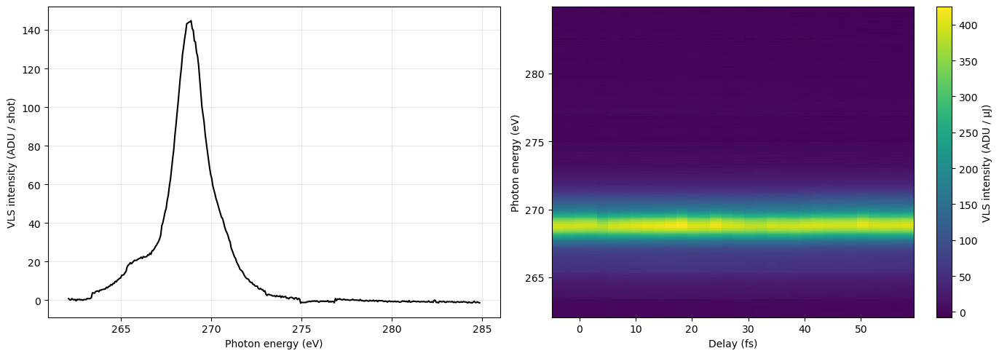

In [495]:
# ---- Average VLS spectrum and delay map -----------------------------------

from matplotlib.ticker import MultipleLocator

order = np.argsort(vls_energy)
E = vls_energy[order]

# Integrated spectrum per shot.
vls_ref = divide(vls_combined['a'].sum(axis=0),
                 vls_combined['n'].sum())

# VLS intensity per µJ.
vls_map = divide(vls_combined['a'],
                 vls_combined['g'][:, None])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(E, vls_ref[order], color='k')

ax[0].set_xlabel('Photon energy (eV)')
ax[0].set_ylabel('VLS intensity (ADU / shot)')
ax[0].xaxis.set_major_locator(MultipleLocator(5))
ax[0].grid(alpha=0.3)

im = ax[1].pcolormesh(
    delay, E, vls_map[:, order].T,
    shading='auto', cmap='viridis'
)

ax[1].set_xlabel('Delay (fs)')
ax[1].set_ylabel('Photon energy (eV)')
ax[1].yaxis.set_major_locator(MultipleLocator(5))
# ax[0].axvline(269.7)
# ax[1].axhline(269.7)

fig.colorbar(im, ax=ax[1], label='VLS intensity (ADU / µJ)')


fig.tight_layout()
plt.show()

Peak energy:        268.890 eV
FWHM:               2.003 eV
Relative bandwidth: 0.745 %


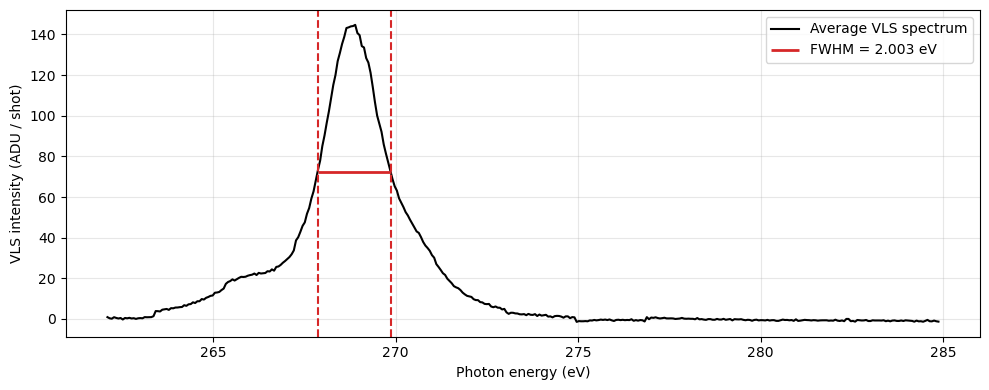

In [496]:
# ---- FWHM of the average VLS spectrum ------------------------------------

x = E
y = vls_ref[order]

peak = np.argmax(y)
half = 0.5 * y[peak]

# Find the crossings on either side of the peak.
left = np.flatnonzero(y[:peak] < half)
right = np.flatnonzero(y[peak+1:] < half)

if len(left) == 0 or len(right) == 0:
    raise ValueError('Half-maximum crossings not found')

l = left[-1]
r = peak + 1 + right[0]

# Interpolate the half-maximum crossings.
E_left = np.interp(half, y[l:l+2], x[l:l+2])
E_right = np.interp(half, y[r-1:r+1][::-1], x[r-1:r+1][::-1])

fwhm = E_right - E_left

print(f'Peak energy:        {x[peak]:.3f} eV')
print(f'FWHM:               {fwhm:.3f} eV')
print(f'Relative bandwidth: {100*fwhm/x[peak]:.3f} %')

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, y, color='k', label='Average VLS spectrum')

ax.axvline(E_left, color='C3', ls='--')
ax.axvline(E_right, color='C3', ls='--')

ax.hlines(half, E_left, E_right, color='C3',
          lw=2, label=f'FWHM = {fwhm:.3f} eV')

ax.set_xlabel('Photon energy (eV)')
ax.set_ylabel('VLS intensity (ADU / shot)')
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [497]:
# Load the ready files (if present) independently of USE_READY.
# Keep full GMD resolution for the correction diagnostics and section 7.3.
ready_scans = {}
electron_scans = {}
all_ready = True
bins = slice(None) if GMD_BINS is None else GMD_BINS

electron_exposure_key = {'vls': 'm', 'gmd': 'g', 'shot': 'n'}[MONITOR]
electron_unit = {'vls': '10⁴ ADU', 'gmd': r'$\mu$J', 'shot': 'shot'}[MONITOR]
electron_label = f'{"Corrected" if USE_READY else "Recorded"} | {MONITOR}'
if USE_READY:
    electron_label += f' | τ = {TAU_NS:g} ns'

for path in FILES:
    s = scans[path.name]
    with h5py.File(path, 'r') as f:
        n = f['n_per_bin'][:]
        D = f['D'][:]
        G = f['G'][:]
        M = f['A'][:].sum(axis=-1) / 1e4
        gmd_edges = f['gmd_edges'][:]

    # M is the mean VLS line sum per shot, not the GMD bin centre.
    m = vls_scans[path.name]['a'].sum(axis=1) / 1e4
    s_e = dict(n=s['n'], g=s['g'], m=m, e_recorded=s['e'],
               e_corrected=None, e=s['e'])
    if np.any((n > 0) & (M <= 0)):
        print(f'{path.name}: warning: non-positive VLS means in populated cells')
    if np.any((s['n'] > 0) & (~np.isfinite(m) | (m <= 0))):
        raise ValueError(f'{path.name}: non-positive/non-finite pooled VLS exposure; check VLS data')

    ready_path = path.with_name(path.stem + '_ready.h5')
    r = dict(n=n, D=D, G=G, M=M, gmd_edges=gmd_edges)
    ready_scans[path.name] = r
    if not ready_path.is_file():
        all_ready = False
        print(f'Missing: {ready_path.name}')
        electron_scans[path.name] = s_e
        continue

    with h5py.File(ready_path, 'r') as f:
        np.testing.assert_array_equal(f['n_per_bin'][:], n)
        np.testing.assert_array_equal(f['tof_edges'][:], axes['tof_edges'])
        np.testing.assert_allclose(f['D'][:], D, rtol=1e-10, atol=1e-12, equal_nan=True)
        taus = f['taus_ns'][:]
        D_live = f['D_live'][:]
        if D_live.shape != (len(taus), *D.shape):
            raise ValueError(f'{ready_path.name}: incompatible D_live shape')
        if not bool(f.attrs.get('check_n_equal', True)):
            raise ValueError(f'{ready_path.name}: failed shot-count check')
        if 'mu0' in f and 'p0_windows_ke' in f:
            r['mu0'] = f['mu0'][:]
            r['p0_windows_ke'] = f['p0_windows_ke'][:]
    r.update(taus=taus, D_live=D_live)
    tau_idx = np.flatnonzero(np.isclose(taus, TAU_NS))
    if len(tau_idx) != 1:
        all_ready = False
        print(f'{ready_path.name}: τ = {TAU_NS} ns unavailable; stored values: {taus}')
    else:
        Dm = D_live[tau_idx[0]]
        r['Dm'] = Dm
        if not np.isfinite(Dm[bins][n[bins] > 0]).all() or np.any(Dm[bins][n[bins] > 0] < 0):
            all_ready = False
            print(f'{ready_path.name}: invalid corrected means in selected populated cells')
        else:
            e = (np.where(n[bins][..., None] > 0, Dm[bins], 0)
                 * n[bins][..., None]).sum(axis=0)[:, ::-1]
            if DELAY_SIGN == -1:
                e = e[::-1]
            s_e['e_corrected'] = e
            if USE_READY:
                s_e['e'] = e
            print(f'{ready_path.name}: validated; τ = {TAU_NS:g} ns')
    electron_scans[path.name] = s_e

if USE_READY and not all_ready:
    raise ValueError('USE_READY=True requires valid corrected means for every selected scan. '
                     'Generate/check the ready files or set USE_READY=False.')

# Pool counts and exposure before division. Never average normalised curves.
electron_combined = {key: np.sum([s[key] for s in electron_scans.values()], axis=0)
                     for key in ('n', 'g', 'm', 'e_recorded', 'e')}
if all_ready:
    electron_combined['e_corrected'] = np.sum(
        [s['e_corrected'] for s in electron_scans.values()], axis=0)
else:
    electron_combined['e_corrected'] = None
print('Main electron analysis:', electron_label)


AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr_ready.h5: validated; τ = 6 ns
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr_ready.h5: validated; τ = 6 ns
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr_ready.h5: validated; τ = 6 ns
Main electron analysis: Corrected | vls | τ = 6 ns


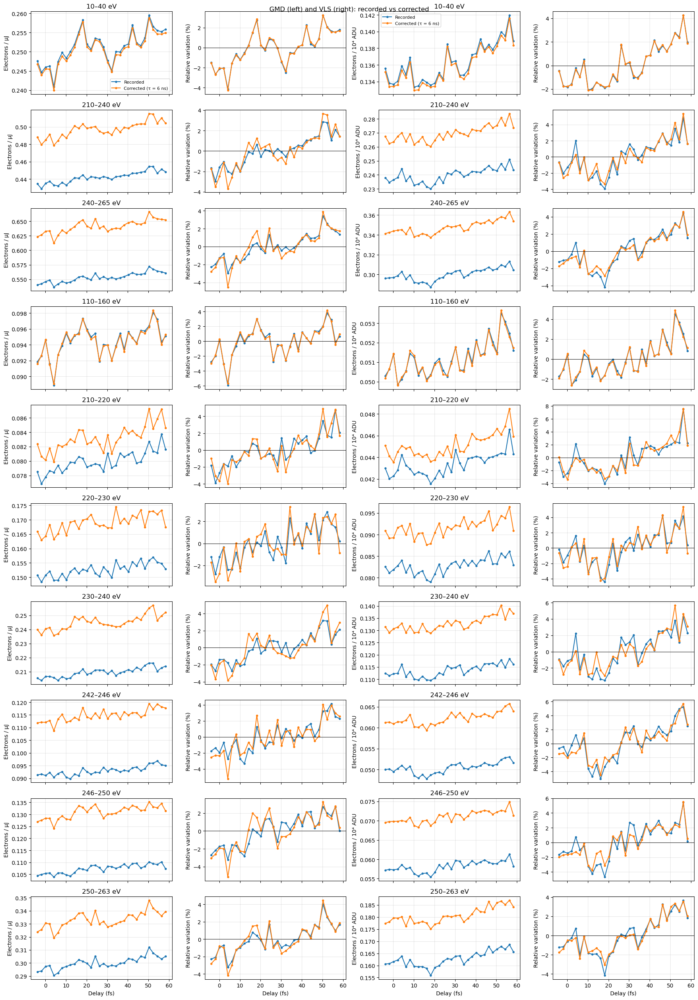

In [498]:
# Same selected shots: compare both monitors with and without correction.
# Include the narrower windows used in the main temporal traces.
comparison_windows = list(dict.fromkeys([*MONITOR_WINDOWS, *ENERGY_WINDOWS]))
curves = [('Recorded', electron_combined['e_recorded'])]
if all_ready:
    curves.append((f'Corrected (τ = {TAU_NS:g} ns)', electron_combined['e_corrected']))
else:
    print('Corrected pooled comparison unavailable: not every selected scan has a valid ready file.')

fig, ax = plt.subplots(len(comparison_windows), 4,
                       figsize=(18, 2.6 * len(comparison_windows)),
                       sharex=True, squeeze=False)
for row, (lo, hi) in enumerate(comparison_windows):
    mask = (ke >= lo) & (ke < hi)
    if not mask.any():
        raise ValueError(f'No electron bins in {lo}–{hi} eV')
    for col, (key, label) in enumerate([('g', 'µJ'), ('m', '10⁴ ADU')]):
        exposure = electron_combined[key]
        for name, e in curves:
            counts = e[:, mask].sum(axis=1)
            y = divide(counts, exposure)
            ref = delay_reference(counts, exposure)
            ax[row, 2*col].plot(delay, y, '.-', label=name)
            ax[row, 2*col+1].plot(delay, 100 * (divide(y, ref) - 1), '.-', label=name)
        ax[row, 2*col].set(title=f'{lo}–{hi} eV', ylabel=f'Electrons / {label}')
        ax[row, 2*col+1].set_ylabel('Relative variation (%)')
        ax[row, 2*col+1].axhline(0, color='k', lw=0.7)
        for a in ax[row, 2*col:2*col+2]:
            a.grid(alpha=0.3)
for a in ax[-1]:
    a.set_xlabel('Delay (fs)')
ax[0, 0].legend(fontsize=8)
ax[0, 2].legend(fontsize=8)
fig.suptitle('GMD (left) and VLS (right): recorded vs corrected')
fig.tight_layout()
plt.show()

#### Dead-time diagnostics

For each scan, check all available dead times and all GMD bins (independent of the main selection). The correction factor is corrected / recorded electron yield, calculated from sums weighted by shots, not the average of individual bin ratios. A factor of 1 means no correction. NaNs in populated cells propagate into the corresponding diagnostic rather than being silently replaced with zero. Empty cells contribute zero. Compare with the zero-hit estimate where the stored energy window matches; this is a check under Poisson assumptions, not an independent proof of the true yield (earlier hits outside the window can suppress its first hit).

The tau plot uses KE evaluated at the TOF-bin centre to match `compute_ready_counts.py`; the selected-tau maps and main traces retain the notebook’s KE-bin-centre convention.

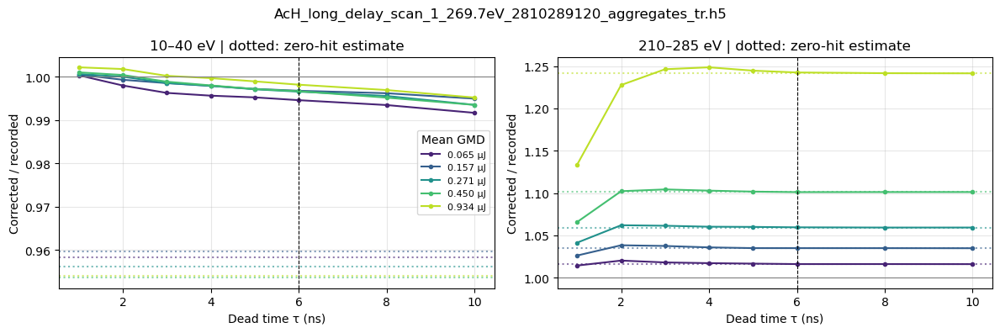

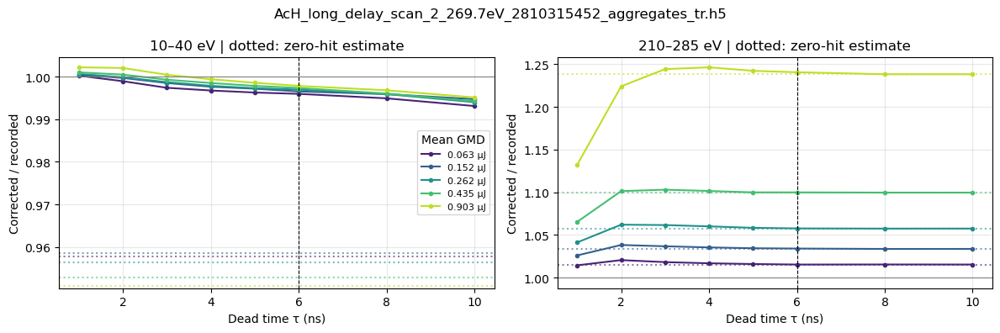

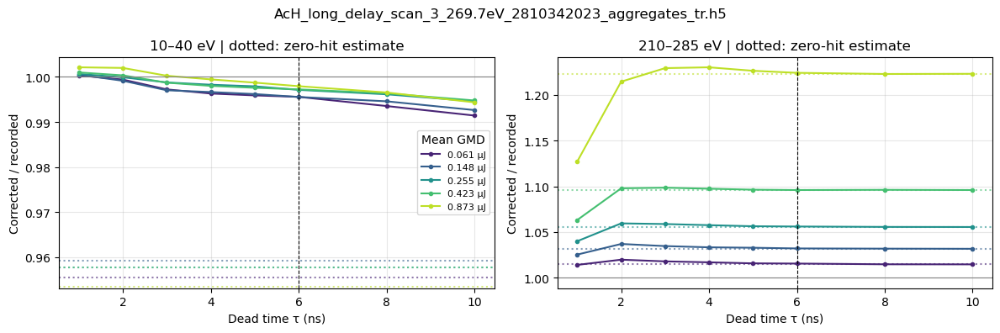

In [499]:
# Correction versus tau, for each scan and GMD bin.
if RUN_READY_DIAGNOSTICS:
    for name, r in ready_scans.items():
        if 'D_live' not in r:
            continue
        n = r['n']
        raw = np.where(n[..., None] > 0, r['D'], 0) * n[..., None]
        live = np.where(n[None, ..., None] > 0, r['D_live'], 0) * n[None, ..., None]
        mean_gmd = divide((np.where(n > 0, r['G'], 0) * n).sum(axis=1), n.sum(axis=1))
        colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(n)))
        fig, ax = plt.subplots(1, len(READY_WINDOWS), figsize=(6 * len(READY_WINDOWS), 4),
                               squeeze=False)
        # Match the convention of compute_ready_counts.py for its zero-hit windows.
        kc_tof = calibration.ke_of_tof((axes['tof_edges'][1:] + axes['tof_edges'][:-1]) / 20)
        for a, (lo, hi) in zip(ax[0], READY_WINDOWS):
            mask = (kc_tof >= lo) & (kc_tof < hi)  # original TOF order
            if not mask.any():
                continue
            raw_sum = raw[..., mask].sum(axis=(1, 2))
            live_sum = live[..., mask].sum(axis=(2, 3))
            ratio = divide(live_sum, raw_sum[None, :])
            # mu0 is compared only for an exactly matching stored window.
            p0_idx = []
            if 'mu0' in r:
                p0_idx = np.flatnonzero(np.all(np.isclose(r['p0_windows_ke'], (lo, hi)), axis=1))
            for j, color in enumerate(colors):
                a.plot(r['taus'], ratio[:, j], '.-', color=color,
                       label=f'{mean_gmd[j]:.3f} µJ')
                if len(p0_idx) == 1:
                    mu = r['mu0'][j, :, p0_idx[0]]
                    mu_sum = np.sum(np.where(n[j] > 0, mu, 0) * n[j])
                    a.axhline(divide(mu_sum, raw_sum[j]), color=color, ls=':', alpha=0.6)
            a.axvline(TAU_NS, color='k', ls='--', lw=0.8)
            a.axhline(1, color='grey', lw=0.8)
            a.set(xlabel='Dead time τ (ns)', ylabel='Corrected / recorded',
                  title=f'{lo}–{hi} eV' + (' | dotted: zero-hit estimate' if len(p0_idx) == 1 else ''))
            a.grid(alpha=0.3)
        ax[0, 0].legend(title='Mean GMD', fontsize=8)
        fig.suptitle(name)
        fig.tight_layout()
        plt.show()

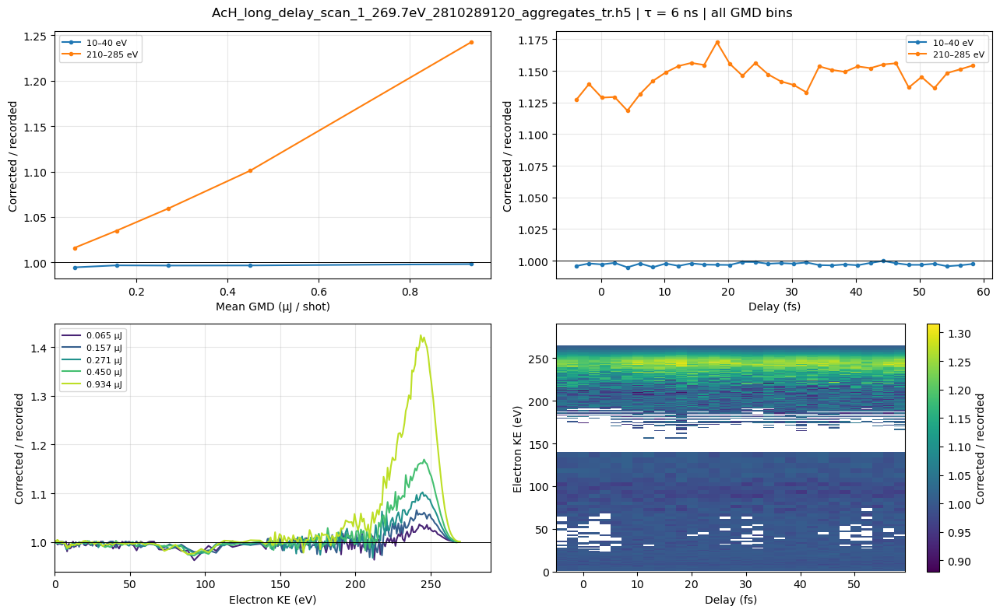

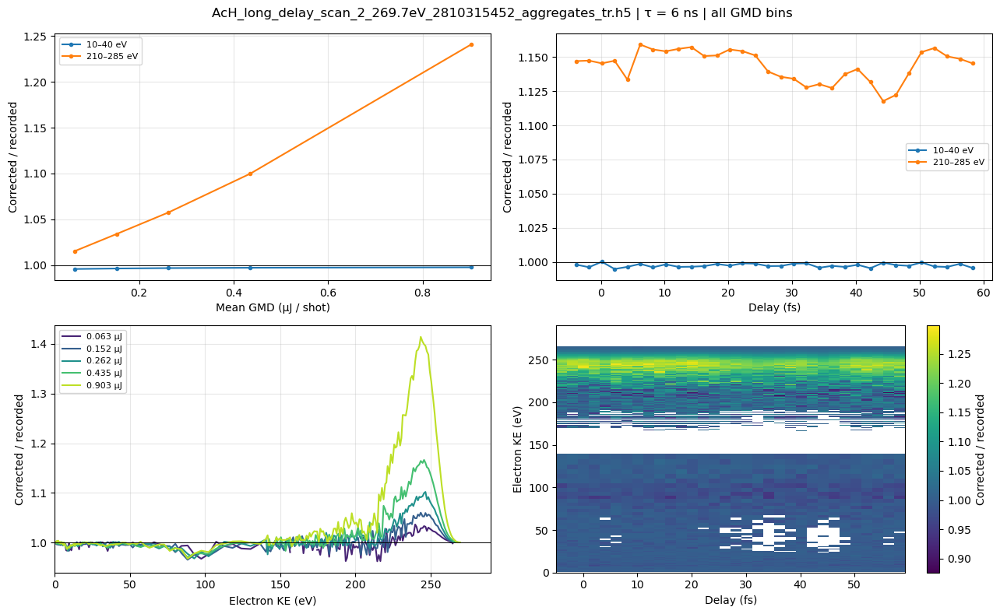

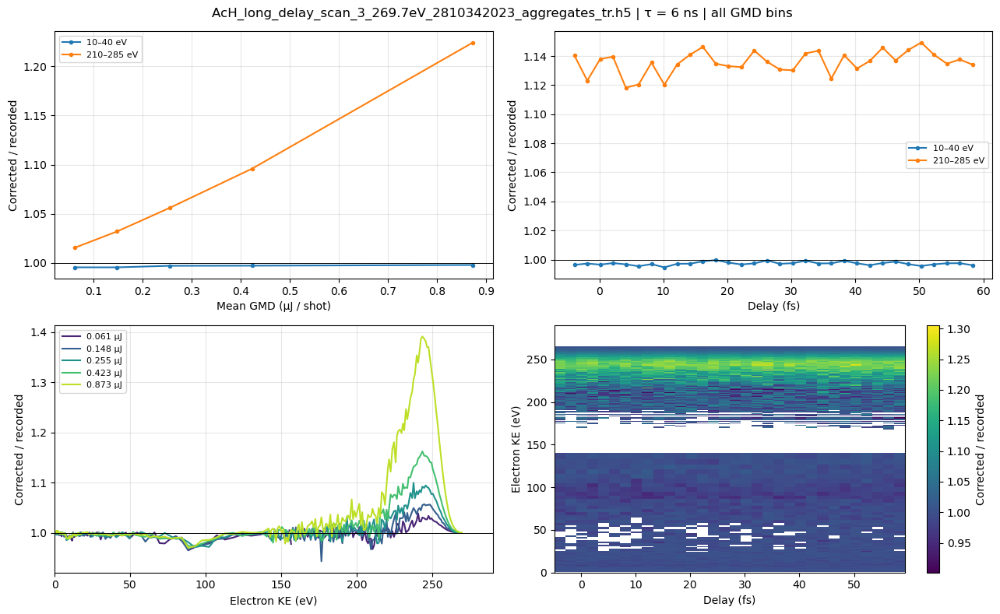

In [500]:
# Correction at the selected tau: versus GMD, delay and kinetic energy.
if RUN_READY_DIAGNOSTICS:
    for name, r in ready_scans.items():
        if 'Dm' not in r:
            continue
        n = r['n']
        raw = np.where(n[..., None] > 0, r['D'], 0) * n[..., None]
        live = np.where(n[..., None] > 0, r['Dm'], 0) * n[..., None]
        raw, live = raw[..., ::-1], live[..., ::-1]
        if DELAY_SIGN == -1:
            raw, live = raw[:, ::-1], live[:, ::-1]
        mean_gmd = divide((np.where(n > 0, r['G'], 0) * n).sum(axis=1), n.sum(axis=1))
        colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(n)))
        fig, ax = plt.subplots(2, 2, figsize=(13, 8))
        for lo, hi in READY_WINDOWS:
            mask = (ke >= lo) & (ke < hi)
            if not mask.any():
                continue
            raw_w = raw[..., mask].sum(axis=-1)
            live_w = live[..., mask].sum(axis=-1)
            ax[0, 0].plot(mean_gmd, divide(live_w.sum(axis=1), raw_w.sum(axis=1)),
                          '.-', label=f'{lo}–{hi} eV')
            ax[0, 1].plot(delay, divide(live_w.sum(axis=0), raw_w.sum(axis=0)),
                          '.-', label=f'{lo}–{hi} eV')
        for j, color in enumerate(colors):
            raw_e = raw[j].sum(axis=0)
            ratio_e = divide(live[j].sum(axis=0), raw_e)
            ratio_e[raw_e < MIN_REF_COUNTS] = np.nan
            ax[1, 0].plot(ke, ratio_e, color=color, label=f'{mean_gmd[j]:.3f} µJ')
        raw_map = raw.sum(axis=0)
        ratio_map = divide(live.sum(axis=0), raw_map)
        ratio_map[raw_map < MIN_REF_COUNTS] = np.nan
        im = ax[1, 1].pcolormesh(delay_edges, ke_edges, ratio_map.T,
                                  shading='flat', cmap='viridis')
        fig.colorbar(im, ax=ax[1, 1], label='Corrected / recorded')
        ax[0, 0].set(xlabel='Mean GMD (µJ / shot)', ylabel='Corrected / recorded')
        ax[0, 1].set(xlabel='Delay (fs)', ylabel='Corrected / recorded')
        ax[1, 0].set(xlabel='Electron KE (eV)', ylabel='Corrected / recorded', xlim=KE_LIM)
        ax[1, 1].set(xlabel='Delay (fs)', ylabel='Electron KE (eV)', ylim=KE_LIM)
        for a in (ax[0, 0], ax[0, 1], ax[1, 0]):
            a.axhline(1, color='k', lw=0.7)
            a.legend(fontsize=8)
            a.grid(alpha=0.3)
        fig.suptitle(f'{name} | τ = {TAU_NS:g} ns | all GMD bins')
        fig.tight_layout()
        plt.show()

### 4.2 Statistical quality and convergence

Estimate statistical uncertainties from the first and second moments
stored in the aggregates. **Recorded electrons / GMD only**, regardless of `USE_READY` and `MONITOR`. Investigate convergence, reproducibility,
noise scaling and sensitivity to delay binning.

In [501]:
# ---- Statistical moments -------------------------------------------------



stat_masks = np.array([
    (ke >= lo) & (ke < hi)
    for lo, hi in STAT_WINDOWS
])

for (lo, hi), mask in zip(STAT_WINDOWS, stat_masks):
    if not mask.any():
        raise ValueError(f'Empty energy window: {lo}–{hi} eV')

    idx = np.flatnonzero(mask)
    print(f'{lo}–{hi} eV: actual edges '
          f'{ke_edges[idx[0]]:.2f}–{ke_edges[idx[-1]+1]:.2f} eV')

# Masks in original TOF-bin order.
W = stat_masks[:, ::-1].astype(float)

stat_scans = {}

for path in FILES:

    path = Path(path)
    s = scans[path.name]

    result = dict(
        n=s['n'].copy(),
        g=s['g'].copy(),
        x=stat_masks.astype(float) @ s['e'].T,
        xx=np.zeros((len(STAT_WINDOWS), len(delay))),
        xg=np.zeros((len(STAT_WINDOWS), len(delay))),
        gg=np.zeros(len(delay))
    )

    with h5py.File(path, 'r') as f:

        np.testing.assert_array_equal(f['z_edges'][:], z_edges)
        np.testing.assert_array_equal(f['tof_edges'][:], axes['tof_edges'])

        n = f['n_per_bin'][:]

        bins = (range(n.shape[0]) if GMD_BINS is None
                else GMD_BINS)

        for j in bins:
            for k in range(len(delay)):

                N = n[j, k]

                if N == 0:
                    continue

                iz = k if DELAY_SIGN == 1 else len(delay) - 1 - k

                DD = f['DtD'][j, k]
                DG = f['DtG'][j, k]
                GG = f['GtG'][j, k]

                # Sum of squared electron yield within each window.
                result['xx'][:, iz] += N * np.einsum(
                    'wi,ij,wj->w', W, DD, W
                )

                # Electron yield × GMD.
                result['xg'][:, iz] += N * (W @ DG)

                # GMD squared.
                result['gg'][iz] += N * GG

    stat_scans[path.name] = result

    print(f'{path.name}: {result["n"].sum():,} shots')


def pool_statistics(group):

    return {
        key: np.sum([s[key] for s in group], axis=0)
        for key in ('n', 'g', 'x', 'xx', 'xg', 'gg')
    }


stat_combined = pool_statistics(list(stat_scans.values()))


def statistical_trace(s):

    # GMD-normalised electron yield.
    y = divide(s['x'], s['g'])

    # Sum of squared residuals: sum((X - y*G)**2).
    residual = (
        s['xx']
        - 2 * y * s['xg']
        + y**2 * s['gg']
    )

    # Allow only small negative values from numerical rounding.
    tol = 1e-10 * np.maximum(s['xx'] + y**2 * s['gg'], 1)

    if np.any(residual < -tol):
        raise ValueError('Inconsistent statistical moments')

    residual = np.maximum(residual, 0)

    # Standard error of the ratio of summed electron counts to summed GMD.
    correction = divide(s['n'], s['n'] - 1)

    se = divide(
        np.sqrt(residual * correction),
        s['g']
    )

    return y, se


# Common reference for comparing all scans.
stat_ref = divide(
    stat_combined['x'].sum(axis=1),
    stat_combined['g'].sum()
)

print('\nCombined shots:', f'{stat_combined["n"].sum():,}')

220–263 eV: actual edges 220.26–263.18 eV
220–240 eV: actual edges 220.26–240.29 eV
242–246 eV: actual edges 242.13–245.88 eV
250–263 eV: actual edges 249.72–263.18 eV


AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5: 2,459,088 shots
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5: 2,457,818 shots
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5: 2,453,743 shots

Combined shots: 7,370,649



220–263 eV
  Total electrons: 2,422,127
  Median electrons/bin: 75,734
  Minimum electrons/bin: 67,027
  Median Poisson error: 0.363%
  Median measured error: 0.322%
  Maximum measured error: 0.346%

220–240 eV
  Total electrons: 970,049
  Median electrons/bin: 30,273
  Minimum electrons/bin: 27,003
  Median Poisson error: 0.575%
  Median measured error: 0.533%
  Maximum measured error: 0.568%

242–246 eV
  Total electrons: 249,085
  Median electrons/bin: 7,784
  Minimum electrons/bin: 6,884
  Median Poisson error: 1.133%
  Median measured error: 1.106%
  Maximum measured error: 1.179%

250–263 eV
  Total electrons: 804,095
  Median electrons/bin: 25,104
  Minimum electrons/bin: 22,117
  Median Poisson error: 0.631%
  Median measured error: 0.576%
  Maximum measured error: 0.619%


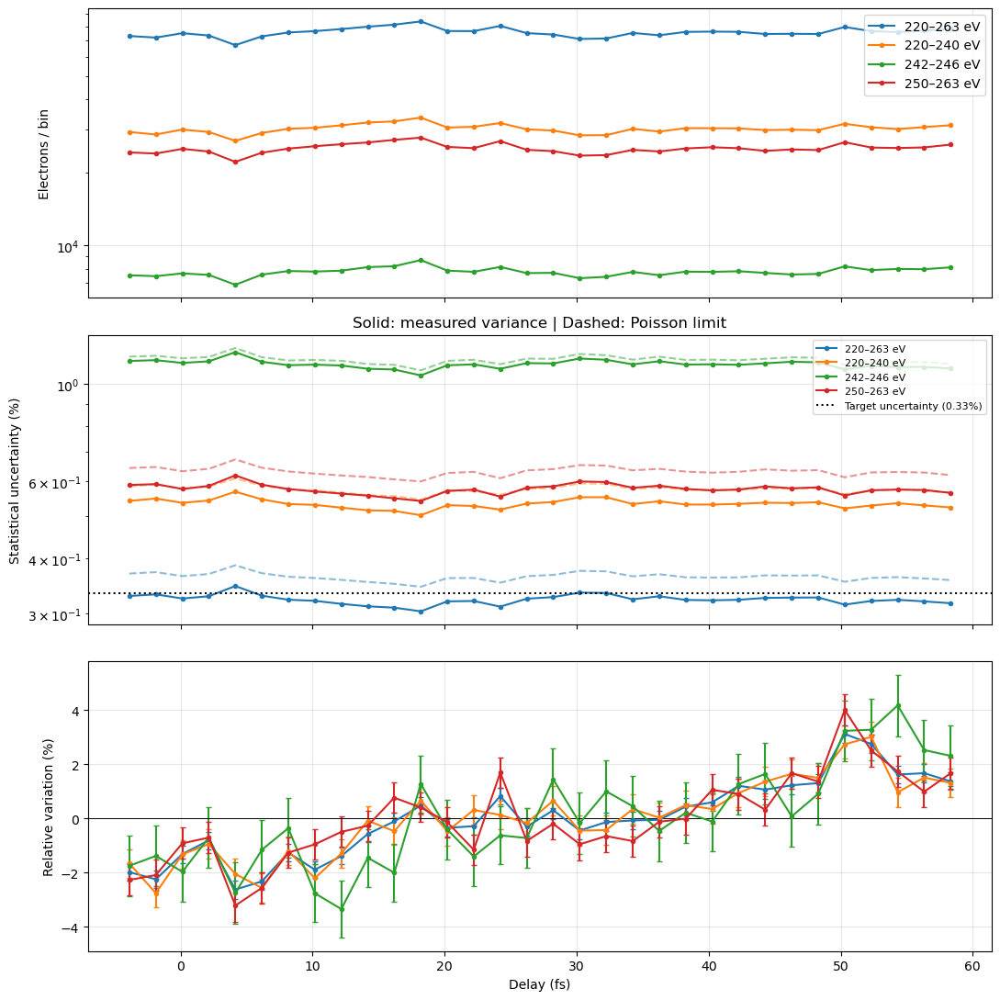

In [502]:
# ---- Electron statistics and uncertainties -------------------------------

y, se = statistical_trace(stat_combined)

counts = stat_combined['x']

# Relative uncertainty from Poisson statistics.
poisson_err = divide(100, np.sqrt(counts))

# Relative uncertainty from the measured second moments.
stat_err = 100 * divide(se, y)

fig, ax = plt.subplots(3, 1, figsize=(11, 11), sharex=True)

for j, (lo, hi) in enumerate(STAT_WINDOWS):

    label = f'{lo}–{hi} eV'

    ax[0].plot(delay, counts[j], '.-', label=label, color=f'C{j}')

    ax[1].plot(delay, stat_err[j], '.-', color=f'C{j}',
               label=label)

    ax[1].plot(delay, poisson_err[j], '--', color=f'C{j}',
               alpha=0.5)

    ax[2].errorbar(
        delay,
        100 * (divide(y[j], stat_ref[j]) - 1),
        yerr=100 * divide(se[j], stat_ref[j]),
        fmt='.-', capsize=2, color=f'C{j}', label=label
    )

    print(f'\n{label}')
    print(f'  Total electrons: {counts[j].sum():,.0f}')
    print(f'  Median electrons/bin: {np.median(counts[j]):,.0f}')
    print(f'  Minimum electrons/bin: {counts[j].min():,.0f}')
    print(f'  Median Poisson error: {np.nanmedian(poisson_err[j]):.3f}%')
    print(f'  Median measured error: {np.nanmedian(stat_err[j]):.3f}%')
    print(f'  Maximum measured error: {np.nanmax(stat_err[j]):.3f}%')


target_error = STAT_SIGNAL_PERCENT / STAT_TARGET_SNR

ax[1].axhline(
    target_error, color='k', ls=':',
    label=f'Target uncertainty ({target_error:.2f}%)'
)

ax[2].axhline(0, color='k', lw=0.7)

ax[0].set_ylabel('Electrons / bin')
ax[1].set_ylabel('Statistical uncertainty (%)')
ax[2].set_ylabel('Relative variation (%)')

ax[0].set_yscale('log')
ax[1].set_yscale('log')

ax[0].legend()
ax[1].legend(fontsize=8)
ax[1].set_title('Solid: measured variance | Dashed: Poisson limit')

for a in ax:
    a.grid(alpha=0.3)

ax[-1].set_xlabel('Delay (fs)')

fig.tight_layout()
plt.show()

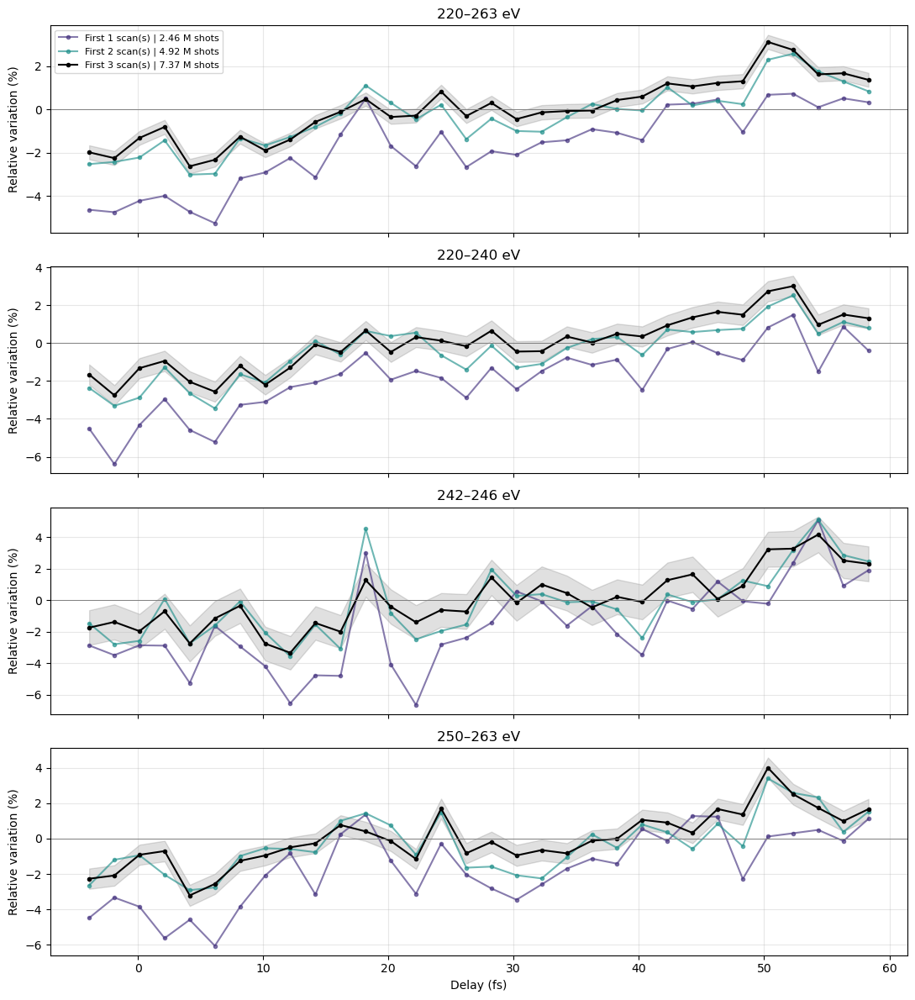

In [503]:
# ---- Cumulative convergence ---------------------------------------------

stat_names = list(stat_scans)
stat_groups = list(stat_scans.values())

fig, ax = plt.subplots(
    len(STAT_WINDOWS), 1,
    figsize=(11, 3 * len(STAT_WINDOWS)),
    sharex=True, squeeze=False
)

colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(stat_groups)))

for k in range(1, len(stat_groups) + 1):

    s = pool_statistics(stat_groups[:k])

    y, se = statistical_trace(s)

    label = f'First {k} scan(s) | {s["n"].sum()/1e6:.2f} M shots'

    color = 'k' if k == len(stat_groups) else colors[k-1]

    for j, (lo, hi) in enumerate(STAT_WINDOWS):

        rel = 100 * (divide(y[j], stat_ref[j]) - 1)
        err = 100 * divide(se[j], stat_ref[j])

        ax[j, 0].plot(
            delay, rel, '.-', color=color,
            alpha=1 if k == len(stat_groups) else 0.65,
            label=label
        )

        # Error band for the full dataset.
        if k == len(stat_groups):
            ax[j, 0].fill_between(
                delay, rel - err, rel + err,
                color='k', alpha=0.12
            )

for j, (lo, hi) in enumerate(STAT_WINDOWS):

    ax[j, 0].set_title(f'{lo}–{hi} eV')
    ax[j, 0].set_ylabel('Relative variation (%)')
    ax[j, 0].axhline(0, color='grey', lw=0.7)
    ax[j, 0].grid(alpha=0.3)

ax[0, 0].legend(fontsize=8)
ax[-1, 0].set_xlabel('Delay (fs)')

fig.tight_layout()
plt.show()

Group 1:
  AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5

Group 2:
  AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5
  AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5

220–263 eV
  RMS difference: 4.17 sigma
  Fraction outside ±2 sigma: 87.5%

220–240 eV
  RMS difference: 2.69 sigma
  Fraction outside ±2 sigma: 62.5%

242–246 eV
  RMS difference: 1.51 sigma
  Fraction outside ±2 sigma: 18.8%

250–263 eV
  RMS difference: 2.56 sigma
  Fraction outside ±2 sigma: 43.8%


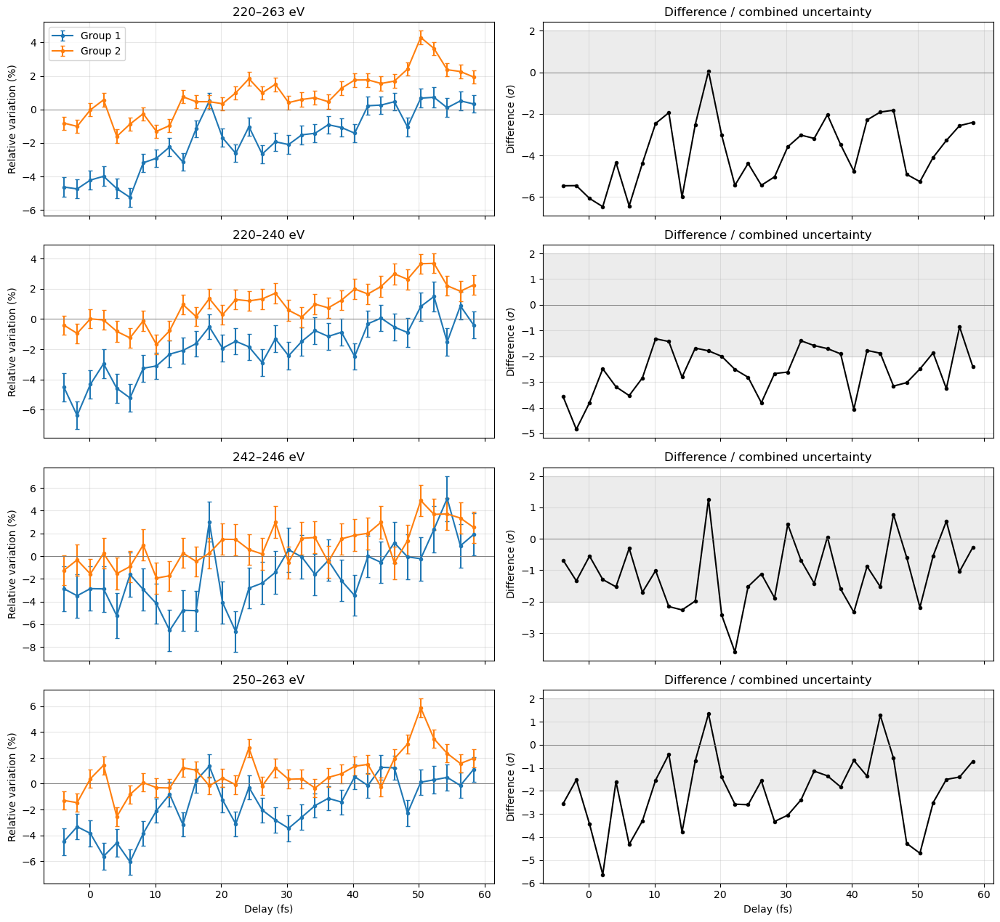

In [504]:
# Independent scan comparison needs at least two acquisitions.
if len(stat_groups) >= 2:
    split = len(stat_groups) // 2

    GROUP_1 = list(range(split))
    GROUP_2 = list(range(split, len(stat_groups)))

    # GROUP_1 = [0, 2]
    # GROUP_2 = [1, 3]

    if set(GROUP_1) & set(GROUP_2):
        raise ValueError('The two groups must not share scans')

    s1 = pool_statistics([stat_groups[j] for j in GROUP_1])
    s2 = pool_statistics([stat_groups[j] for j in GROUP_2])

    y1, se1 = statistical_trace(s1)
    y2, se2 = statistical_trace(s2)

    print('Group 1:')
    for j in GROUP_1:
        print(' ', stat_names[j])

    print('\nGroup 2:')
    for j in GROUP_2:
        print(' ', stat_names[j])

    fig, ax = plt.subplots(
        len(STAT_WINDOWS), 2,
        figsize=(14, 3.2 * len(STAT_WINDOWS)),
        sharex=True, squeeze=False
    )

    for j, (lo, hi) in enumerate(STAT_WINDOWS):

        rel1 = 100 * (divide(y1[j], stat_ref[j]) - 1)
        rel2 = 100 * (divide(y2[j], stat_ref[j]) - 1)

        err1 = 100 * divide(se1[j], stat_ref[j])
        err2 = 100 * divide(se2[j], stat_ref[j])

        ax[j, 0].errorbar(
            delay, rel1, yerr=err1,
            fmt='.-', capsize=2, label='Group 1'
        )

        ax[j, 0].errorbar(
            delay, rel2, yerr=err2,
            fmt='.-', capsize=2, label='Group 2'
        )

        # Difference in units of statistical uncertainty.
        diff = y1[j] - y2[j]
        diff_se = np.sqrt(se1[j]**2 + se2[j]**2)

        z_score = divide(diff, diff_se)

        ax[j, 1].plot(delay, z_score, 'k.-')
        ax[j, 1].axhspan(-2, 2, color='grey', alpha=0.15)

        ax[j, 0].set_title(f'{lo}–{hi} eV')
        ax[j, 1].set_title('Difference / combined uncertainty')

        ax[j, 0].set_ylabel('Relative variation (%)')
        ax[j, 1].set_ylabel(r'Difference ($\sigma$)')

        valid = np.isfinite(z_score)

        if valid.any():
            rms_z = np.sqrt(np.mean(z_score[valid]**2))

            print(f'\n{lo}–{hi} eV')
            print(f'  RMS difference: {rms_z:.2f} sigma')
            print(f'  Fraction outside ±2 sigma: '
                  f'{100 * np.mean(np.abs(z_score[valid]) > 2):.1f}%')

        for a in ax[j]:
            a.axhline(0, color='grey', lw=0.7)
            a.grid(alpha=0.3)

    ax[0, 0].legend()

    for a in ax[-1]:
        a.set_xlabel('Delay (fs)')

    fig.tight_layout()
    plt.show()

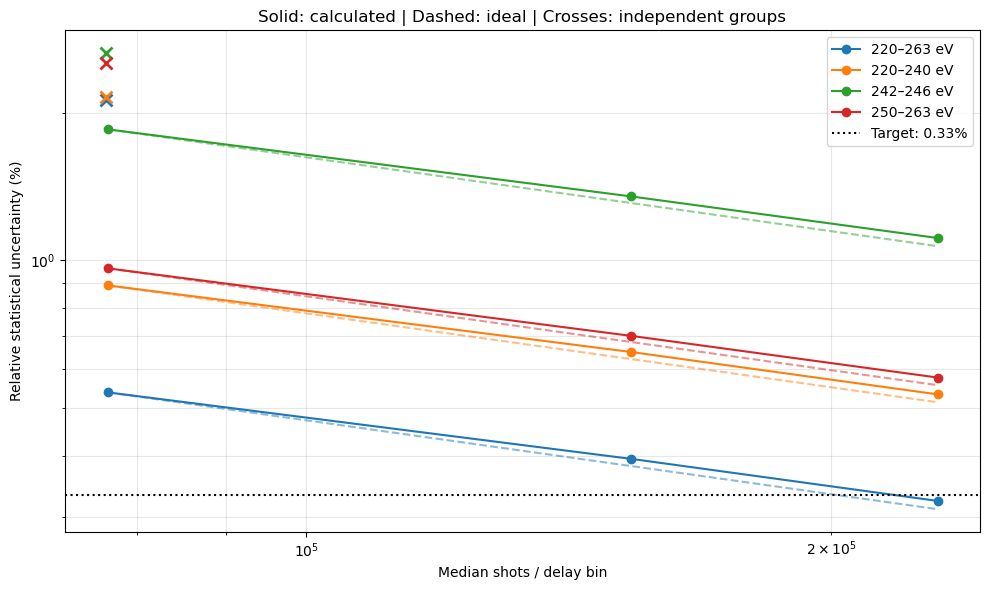


Current acquisition time: 2.09 h
Target signal: 1.0%
Target SNR: 3
Target uncertainty: 0.333%

220–263 eV
  Median uncertainty: 0.323%
  Worst measured uncertainty: 0.337%
  Delay bins meeting target: 30/32
  Additional time for typical bin: 0.00 h
  Additional time for worst measured bin: 0.05 h

220–240 eV
  Median uncertainty: 0.533%
  Worst measured uncertainty: 0.556%
  Delay bins meeting target: 0/32
  Additional time for typical bin: 3.26 h
  Additional time for worst measured bin: 3.73 h

242–246 eV
  Median uncertainty: 1.110%
  Worst measured uncertainty: 1.147%
  Delay bins meeting target: 0/32
  Additional time for typical bin: 21.09 h
  Additional time for worst measured bin: 22.66 h

250–263 eV
  Median uncertainty: 0.577%
  Worst measured uncertainty: 0.599%
  Delay bins meeting target: 0/32
  Additional time for typical bin: 4.17 h
  Additional time for worst measured bin: 4.65 h


In [505]:
# ---- Noise scaling with acquisition size --------------------------------

n_scans = len(stat_groups)

shots = []
noise = []

for k in range(1, n_scans + 1):

    s = pool_statistics(stat_groups[:k])
    y, se = statistical_trace(s)

    shots.append(np.median(s['n']))
    noise.append(np.nanmedian(
        100 * divide(se, stat_ref[:, None]), axis=1
    ))

shots = np.asarray(shots)
noise = np.asarray(noise)

fig, ax = plt.subplots(figsize=(10, 6))

for j, (lo, hi) in enumerate(STAT_WINDOWS):

    label = f'{lo}–{hi} eV'
    color = f'C{j}'

    ax.loglog(shots, noise[:, j], 'o-',
              color=color, label=label)

    # Ideal statistical scaling, anchored to the first scan.
    ideal = noise[0, j] * np.sqrt(shots[0] / shots)

    ax.loglog(shots, ideal, '--', color=color, alpha=0.5)


# Empirical noise from non-overlapping groups of equal scan count.
for k in range(1, n_scans // 2 + 1):

    for start in range(0, n_scans - 2*k + 1, 2*k):

        a = pool_statistics(stat_groups[start:start+k])
        b = pool_statistics(stat_groups[start+k:start+2*k])

        ya, _ = statistical_trace(a)
        yb, _ = statistical_trace(b)

        diff = 100 * divide(ya - yb, stat_ref[:, None])

        empirical = np.sqrt(
            np.nanmean(diff**2, axis=1) / 2
        )

        N = np.median((a['n'] + b['n']) / 2)

        for j in range(len(STAT_WINDOWS)):

            ax.loglog(
                N, empirical[j], 'x',
                color=f'C{j}', ms=9, mew=2
            )


target_error = STAT_SIGNAL_PERCENT / STAT_TARGET_SNR

ax.axhline(target_error, color='k', ls=':',
           label=f'Target: {target_error:.2f}%')

ax.set_xlabel('Median shots / delay bin')
ax.set_ylabel('Relative statistical uncertainty (%)')
ax.set_title('Solid: calculated | Dashed: ideal | Crosses: independent groups')

ax.legend()
ax.grid(alpha=0.3, which='both')

fig.tight_layout()
plt.show()


# ---- Estimated acquisition time -----------------------------------------

T_current = combined['minutes'] / 60

y, se = statistical_trace(stat_combined)
relative_se = 100 * divide(se, stat_ref[:, None])

print(f'\nCurrent acquisition time: {T_current:.2f} h')
print(f'Target signal: {STAT_SIGNAL_PERCENT}%')
print(f'Target SNR: {STAT_TARGET_SNR}')
print(f'Target uncertainty: {target_error:.3f}%')

for j, (lo, hi) in enumerate(STAT_WINDOWS):

    valid = np.isfinite(relative_se[j])
    err = relative_se[j, valid]

    print(f'\n{lo}–{hi} eV')

    if not len(err):
        print('  No valid statistical estimate')
        continue

    err_median = np.median(err)
    err_max = np.max(err)

    print(f'  Median uncertainty: {err_median:.3f}%')
    print(f'  Worst measured uncertainty: {err_max:.3f}%')
    print(f'  Delay bins meeting target: '
          f'{np.count_nonzero(err <= target_error)}/{len(delay)}')

    if np.isfinite(T_current) and T_current > 0:

        T_median = T_current * (err_median / target_error)**2
        T_max = T_current * (err_max / target_error)**2

        print(f'  Additional time for typical bin: '
              f'{max(0, T_median - T_current):.2f} h')

        print(f'  Additional time for worst measured bin: '
              f'{max(0, T_max - T_current):.2f} h')


Delay bin width: 2.01 fs
  220–263 eV: median uncertainty 0.323%
  220–240 eV: median uncertainty 0.533%
  242–246 eV: median uncertainty 1.110%
  250–263 eV: median uncertainty 0.577%

Delay bin width: 4.01 fs
  220–263 eV: median uncertainty 0.229%
  220–240 eV: median uncertainty 0.378%
  242–246 eV: median uncertainty 0.787%
  250–263 eV: median uncertainty 0.408%

Delay bin width: 6.02 fs
  220–263 eV: median uncertainty 0.189%
  220–240 eV: median uncertainty 0.311%
  242–246 eV: median uncertainty 0.649%
  250–263 eV: median uncertainty 0.337%

Delay bin width: 8.03 fs
  220–263 eV: median uncertainty 0.162%
  220–240 eV: median uncertainty 0.267%
  242–246 eV: median uncertainty 0.555%
  250–263 eV: median uncertainty 0.289%


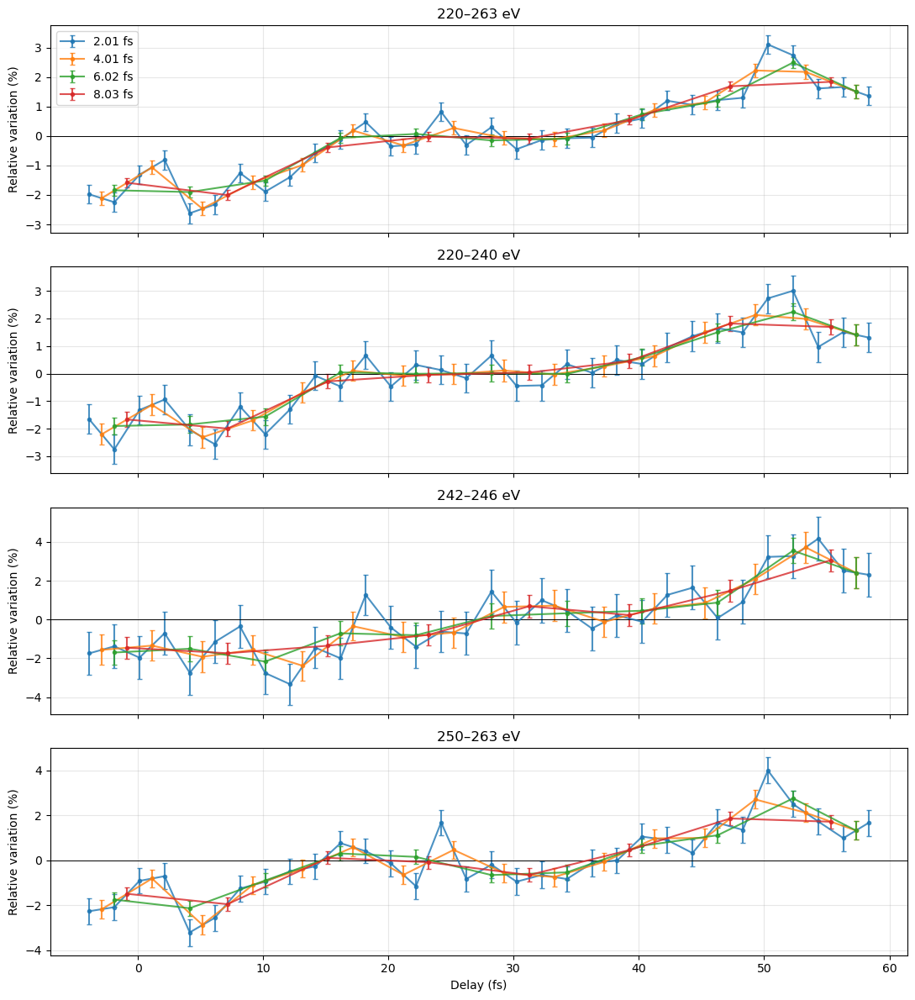

In [506]:
# ---- Sensitivity to delay binning ----------------------------------------


fig, ax = plt.subplots(
    len(STAT_WINDOWS), 1,
    figsize=(11, 3 * len(STAT_WINDOWS)),
    sharex=True, squeeze=False
)

for factor in DELAY_REBIN_FACTORS:

    idx = np.arange(0, len(delay), factor)

    edges = delay_edges[np.r_[idx, len(delay)]]
    centres = (edges[:-1] + edges[1:]) / 2

    # Rebin all accumulated statistical moments.
    s = {
        key: np.add.reduceat(value, idx, axis=-1)
        for key, value in stat_combined.items()
    }

    y, se = statistical_trace(s)

    bin_width = np.median(np.diff(edges))

    print(f'\nDelay bin width: {bin_width:.2f} fs')

    for j, (lo, hi) in enumerate(STAT_WINDOWS):

        rel = 100 * (divide(y[j], stat_ref[j]) - 1)
        err = 100 * divide(se[j], stat_ref[j])

        ax[j, 0].errorbar(
            centres, rel, yerr=err,
            fmt='.-', capsize=2, alpha=0.8,
            label=f'{bin_width:.2f} fs'
        )

        print(f'  {lo}–{hi} eV: '
              f'median uncertainty {np.nanmedian(err):.3f}%')

for j, (lo, hi) in enumerate(STAT_WINDOWS):

    ax[j, 0].set_title(f'{lo}–{hi} eV')
    ax[j, 0].set_ylabel('Relative variation (%)')
    ax[j, 0].axhline(0, color='k', lw=0.7)
    ax[j, 0].grid(alpha=0.3)

ax[0, 0].legend()
ax[-1, 0].set_xlabel('Delay (fs)')

fig.tight_layout()
plt.show()

## 5. Electron spectra

Integrated spectrum, absolute delay map and relative variation from the exposure-weighted delay average. Uses `MONITOR` and `USE_READY`. The minimum-count mask always uses recorded electrons. Use `pcolormesh` with calibrated edges; no interpolation or smoothing.

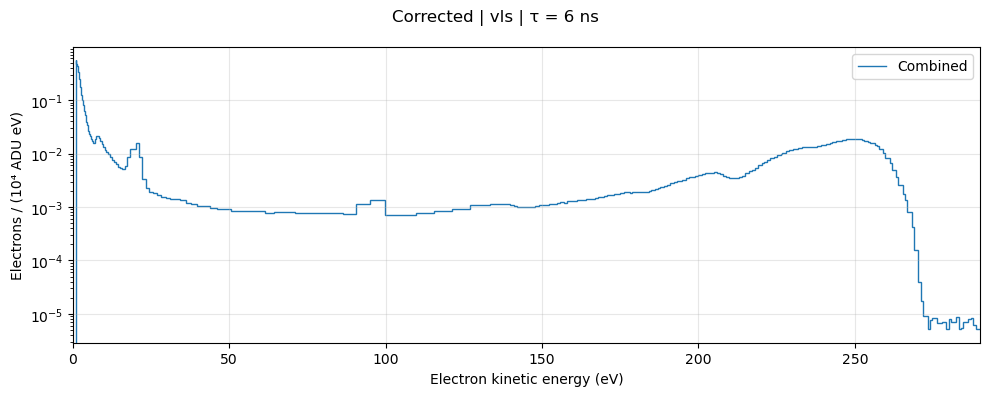

In [507]:
Y_e = divide(electron_combined['e'], electron_combined[electron_exposure_key][:, None]) / dke
Y_i = divide(combined['i'], combined[exposure_key][:, None]) / dmq
ref_e = divide(electron_combined['e'].sum(axis=0), electron_combined[electron_exposure_key].sum()) / dke
ref_i = divide(combined['i'].sum(axis=0), combined[exposure_key].sum()) / dmq

fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(ref_e, ke_edges, label='Combined')
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({electron_unit} eV)', xlim=KE_LIM, yscale='log')
ax.legend()
fig.suptitle(electron_label)
fig.tight_layout()
ax.grid(alpha=0.3)
plt.show()

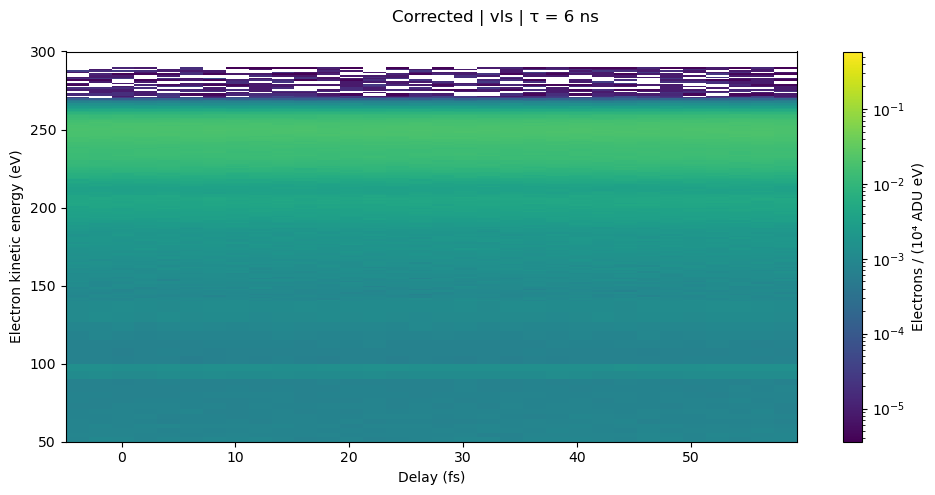

In [508]:
from matplotlib.colors import LogNorm


fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, ke_edges, Y_e.T,
                   shading='flat', cmap='viridis',
                   norm=LogNorm(vmin=VLS_VMIN if MONITOR == 'vls' else (VMIN if MONITOR == 'gmd' else None),
                                vmax=VLS_VMAX if MONITOR == 'vls' else (VMAX if MONITOR == 'gmd' else None)))

fig.colorbar(im, ax=ax, label=f'Electrons / ({electron_unit} eV)')
ax.set(xlabel='Delay (fs)',
       ylabel='Electron kinetic energy (eV)',
       ylim=(50, 300))

fig.suptitle(electron_label)
fig.tight_layout()

plt.show()

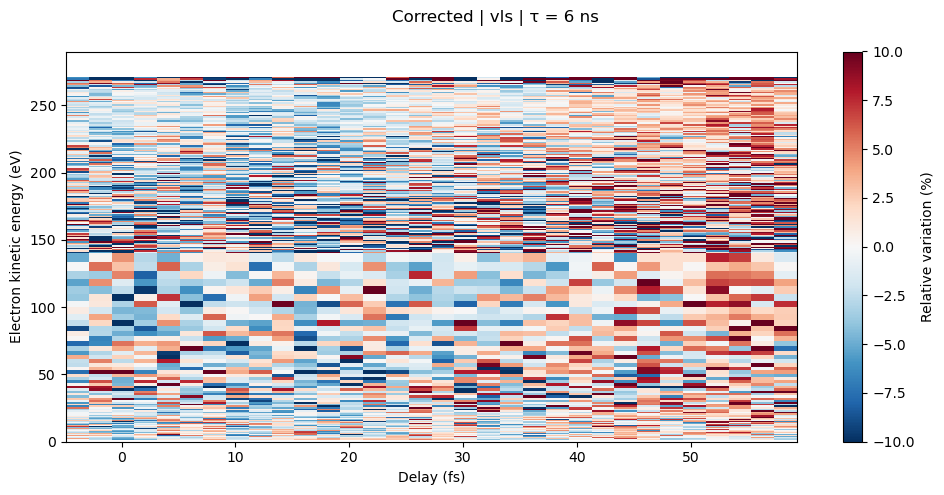

In [509]:
ref_e_delay = delay_reference(electron_combined['e'],
                              electron_combined[electron_exposure_key]) / dke

R_e = divide(Y_e - ref_e_delay, ref_e_delay)
R_e[:, electron_combined['e_recorded'][ref_mask].sum(axis=0) < MIN_REF_COUNTS] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, ke_edges, 100 * R_e.T, shading='flat', cmap='RdBu_r',
                   vmin=-100 * REL_LIM, vmax=100 * REL_LIM)
fig.colorbar(im, ax=ax, label='Relative variation (%)')
ax.set(xlabel='Delay (fs)', ylabel='Electron kinetic energy (eV)', ylim=KE_LIM)
fig.suptitle(electron_label)
fig.tight_layout()
plt.show()

### Spectral shape

Normalise by the total electron count per delay to check changes in spectral shape. This removes overall yield changes and can introduce correlations between energy regions. The shape reference uses all delays.

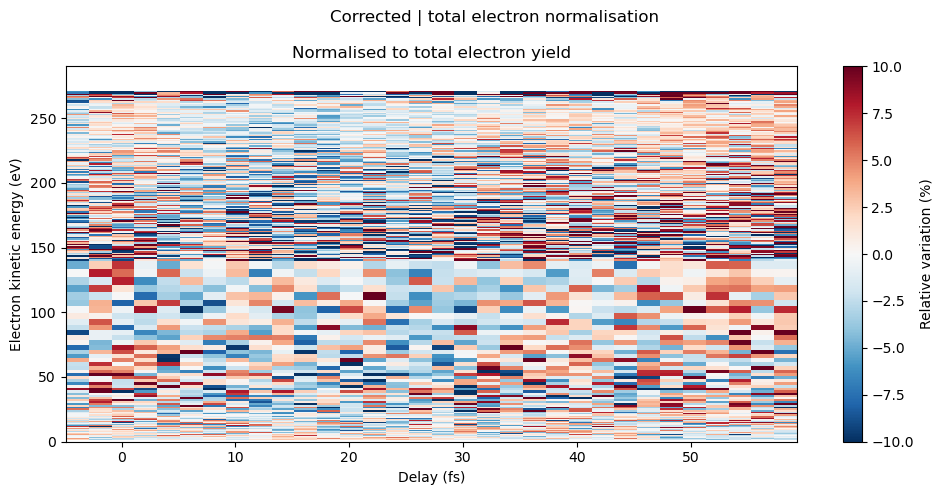

In [510]:
# Relative variation of the spectral shape
total_e = electron_combined['e'].sum(axis=1)

Y_e_shape = divide(electron_combined['e'], total_e[:, None]) / dke
ref_e_shape = divide(electron_combined['e'].sum(axis=0),
                     total_e.sum()) / dke

R_e_shape = divide(Y_e_shape - ref_e_shape, ref_e_shape)
R_e_shape[:, electron_combined['e_recorded'].sum(axis=0) < MIN_REF_COUNTS] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, ke_edges, 100 * R_e_shape.T,
                   shading='flat', cmap='RdBu_r',
                   vmin=-100 * REL_LIM, vmax=100 * REL_LIM)

fig.colorbar(im, ax=ax, label='Relative variation (%)')
ax.set_title('Normalised to total electron yield')
ax.set(xlabel='Delay (fs)',
       ylabel='Electron kinetic energy (eV)',
       ylim=KE_LIM)

fig.suptitle(electron_label.split(' | ')[0] + ' | total electron normalisation')
fig.tight_layout()
plt.show()

## 6. Ion spectra

Ion plots retain their own `NORMALISE` setting (per µJ or per shot) and use recorded ions. The relative maps show deviations from the mean, not pumped-minus-unpumped absorption.

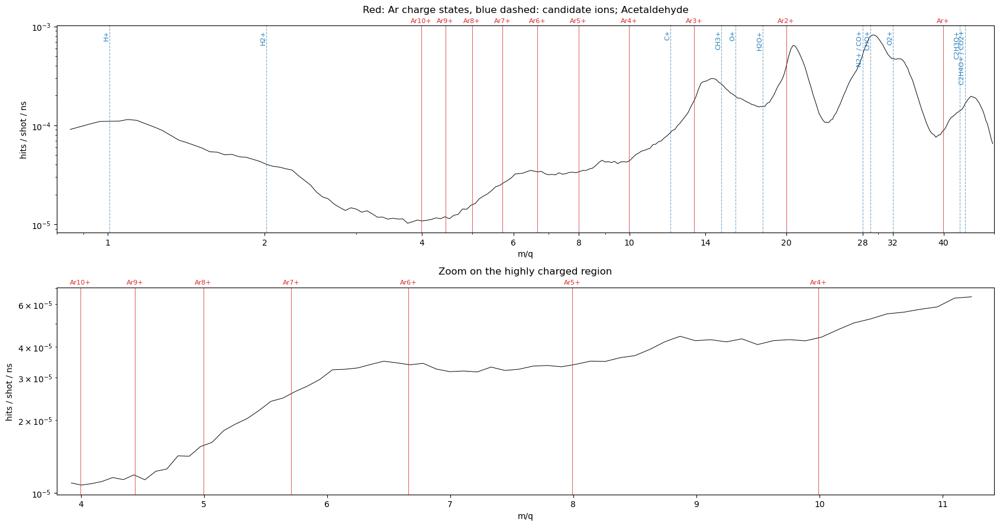

In [511]:
# The spectrum on the m/q axis (log): Ar^q+ positions and other ions marked



# Integrated ion spectrum, normalised per shot and per ns
itof_edges = axes['ion_tof_edges'] / 10
dtof_i = np.diff(itof_edges)

spec_mq = divide(combined['i'].sum(axis=0),
                 combined['n'].sum()) / dtof_i

ar_mq = {q: M_AR / q for q in range(1, Q_MAX + 1)}

fig, axs = plt.subplots(2, 1, figsize=(17, 9))

for ax, (lo, hi) in zip(axs, ((0.8, 50),
                             (M_AR / (Q_MAX + 0.5), M_AR / 3.5))):

    m = (mq_edges[:-1] >= lo) & (mq_edges[1:] <= hi)

    ax.plot(0.5 * (mq_edges[:-1] + mq_edges[1:])[m],
            spec_mq[m], lw=0.7, color="k")

    for q, mq_pos in ar_mq.items():
        if lo < mq_pos < hi:
            ax.axvline(mq_pos, color="C3", lw=0.8, alpha=0.7)
            ax.text(mq_pos, 1.01, f"Ar{q}+" if q > 1 else "Ar+",
                    color="C3", ha="center", va="bottom", fontsize=8,
                    transform=ax.get_xaxis_transform())

    for name, mq_pos in OTHER_IONS.items():
        if lo < mq_pos < hi:
            ax.axvline(mq_pos, color="C0", lw=0.8, ls="--", alpha=0.6)
            ax.text(mq_pos, 0.98, name, color="C0",
                    ha="right", va="top", fontsize=8, rotation=90,
                    transform=ax.get_xaxis_transform())

    ax.set(xlabel="m/q", ylabel="hits / shot / ns",
           yscale="log", xlim=(lo, hi))

axs[0].set_xscale("log")
axs[0].set_xticks([1, 2, 4, 6, 8, 10, 14, 20, 28, 32, 40])
axs[0].set_xticklabels(['1', '2', '4', '6', '8', '10', '14', '20', '28', '32', '40'])

axs[0].set_title("Red: Ar charge states, blue dashed: candidate ions; Acetaldehyde",
                 pad=16)
axs[1].set_title("Zoom on the highly charged region", pad=16)

fig.tight_layout()
plt.show()

In [512]:
# Separate selection: finite positive GMD and MAX_ION_HITS only.
# Fine ion bins are a resolution check, not the aggregate-selected yield.
if RUN_FINE_IONS:
    # ---- High-resolution ion spectrum from combined H5 ---------------------------




    # Find the corresponding combined files from write_h5.py
    RAW_FILES = [
        COMBINED_DIR / path.name.replace('_aggregates_tr.h5', '.h5')
        for path in FILES
    ]

    # Fine TOF histogram
    fit_edges = np.arange(TOF_RANGE_I[0],
                          TOF_RANGE_I[1] + FIT_BIN / 2,
                          FIT_BIN)

    fit_counts = np.zeros(len(fit_edges) - 1, dtype=np.int64)
    n_kept = 0

    for path in RAW_FILES:

        counts_run = np.zeros_like(fit_counts)
        n_run = 0

        with h5py.File(path, 'r') as f:

            tofs_i = f['tofs_i']
            gmd = f['gmd']

            assert tofs_i.shape[:2] == gmd.shape

            for start in range(0, len(gmd), CHUNK_TRAINS):

                sl = slice(start, start + CHUNK_TRAINS)

                G = gmd[sl]
                H = tofs_i[sl]

                # Select shots with a valid FEL pulse.
                keep = np.isfinite(G) & (G > 0)

                # Remove burst shots, as in the Argon notebook.
                if MAX_ION_HITS is not None:
                    keep &= ((H > 0).sum(axis=-1) <= MAX_ION_HITS)

                n_run += keep.sum()

                # Remove padding and convert TDC units to ns.
                hits = H[keep]
                hits = hits[hits > 0] / 10

                counts_run += np.histogram(hits, bins=fit_edges)[0]

        fit_counts += counts_run
        n_kept += n_run

        print(f'{path.name}')
        print(f'  Shots:    {n_run:,}')
        print(f'  Ion hits: {counts_run.sum():,}')

    if n_kept == 0:
        raise ValueError('No valid shots selected')

    # Normalise per shot and per ns, as in the Argon notebook.
    spec_raw = fit_counts / n_kept / np.diff(fit_edges)

    # Use the existing ion calibration.
    mq_edges_raw = calibration.mq_of_tof(fit_edges)
    mq_raw = (mq_edges_raw[:-1] + mq_edges_raw[1:]) / 2

    assert np.all(np.diff(mq_edges_raw) > 0)

    ar_mq = {q: M_AR / q for q in range(1, Q_MAX + 1)}

    print(f'\nTotal shots: {n_kept:,}')
    print(f'Total ion hits: {fit_counts.sum():,}')
    print(f'TOF bin width: {FIT_BIN} ns')


    # ---- Annotated mass spectrum ------------------------------------------------

    fig, axs = plt.subplots(2, 1, figsize=(17, 9))

    for ax, (lo, hi) in zip(
            axs, ((0.8, 50),
                  (M_AR / (Q_MAX + 0.5), M_AR / 3.5))):

        m = ((mq_edges_raw[:-1] >= lo) &
             (mq_edges_raw[1:] <= hi))

        ax.plot(mq_raw[m], spec_raw[m], lw=0.7, color="k")

        for q, mq_pos in ar_mq.items():

            if lo < mq_pos < hi:

                ax.axvline(mq_pos, color="C3", lw=0.8, alpha=0.7)

                ax.text(mq_pos, 1.01,
                        f"Ar{q}+" if q > 1 else "Ar+",
                        color="C3", ha="center", va="bottom",
                        fontsize=8,
                        transform=ax.get_xaxis_transform())

        for name, mq_pos in OTHER_IONS.items():

            if lo < mq_pos < hi:

                ax.axvline(mq_pos, color="C0", lw=0.8,
                           ls="--", alpha=0.6)

                ax.text(mq_pos, 0.98, name,
                        color="C0", ha="right", va="top",
                        fontsize=8, rotation=90,
                        transform=ax.get_xaxis_transform())

        ax.set(xlabel="m/q",
               ylabel="hits / shot / ns",
               yscale="log",
               xlim=(lo, hi))

    axs[0].set_xscale("log")

    axs[0].set_xticks([1, 2, 4, 6, 8, 10, 14, 20, 28, 32, 40])
    axs[0].set_xticklabels(['1', '2', '4', '6', '8', '10', '14', '20', '28', '32', '40'])

    axs[0].set_title(
        f"Red: Ar charge states, blue dashed: other ions; "
        f"{len(RAW_FILES)} scans, {FIT_BIN} ns bins",
        pad=16
    )

    axs[1].set_title("Zoom on the highly charged region", pad=16)

    fig.tight_layout()
    plt.show()

In [513]:
print('Aggregate ion TOF bin widths (ns):',
      np.unique(np.round(np.diff(axes['ion_tof_edges'] / 10), 6)))

Aggregate ion TOF bin widths (ns): [10.]


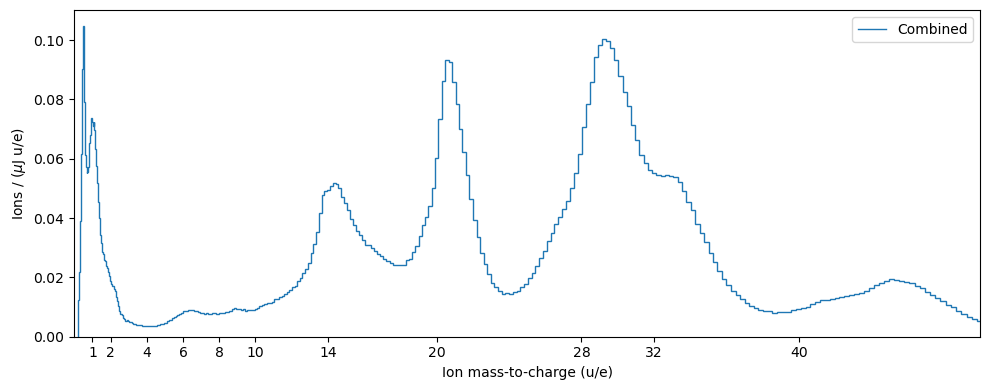

In [514]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(ref_i, mq_edges, label='Combined')
ax.set(xlabel='Ion mass-to-charge (u/e)', ylabel=f'Ions / ({unit} u/e)', xlim=MQ_LIM)
ax.legend()
# ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 6, 8, 10, 14, 20, 28, 32, 40])
ax.set_xticklabels(['1', '2', '4', '6', '8', '10', '14', '20', '28', '32', '40'])
fig.tight_layout()
plt.show()

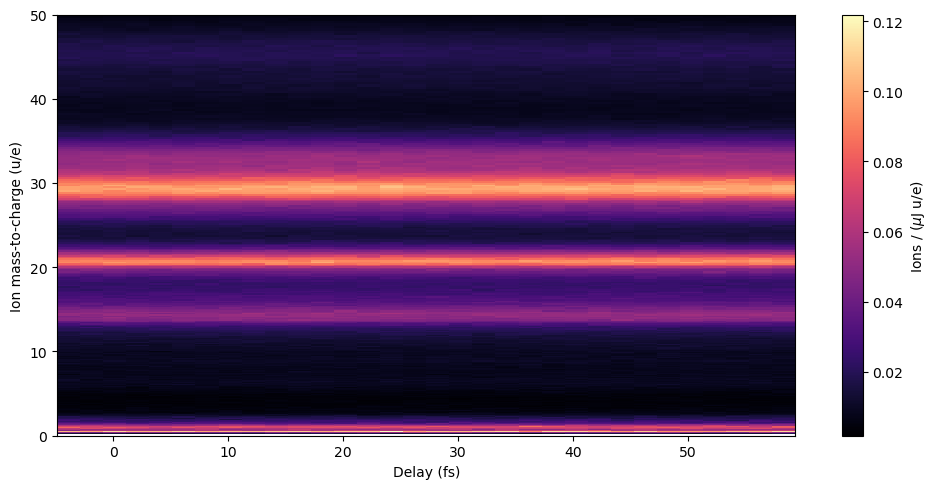

In [515]:
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, mq_edges, Y_i.T, shading='flat', cmap='magma')
fig.colorbar(im, ax=ax, label=f'Ions / ({unit} u/e)')
ax.set(xlabel='Delay (fs)', ylabel='Ion mass-to-charge (u/e)', ylim=MQ_LIM)
fig.tight_layout()
plt.show()

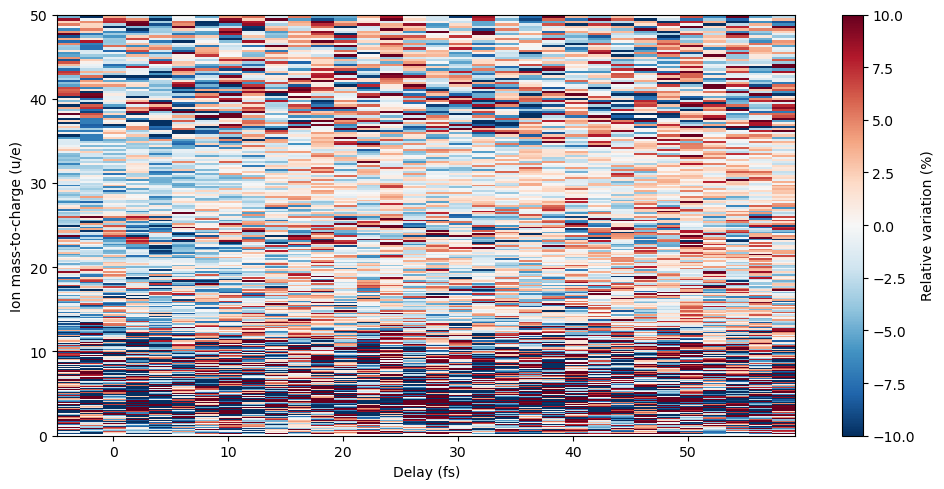

In [516]:
ref_i_delay = delay_reference(combined['i'],
                              combined[exposure_key]) / dmq

R_i = divide(Y_i - ref_i_delay, ref_i_delay)
R_i[:, combined['i'][ref_mask].sum(axis=0) < MIN_REF_COUNTS] = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(delay_edges, mq_edges, 100 * R_i.T, shading='flat', cmap='RdBu_r',
                   vmin=-100 * REL_LIM, vmax=100 * REL_LIM)
fig.colorbar(im, ax=ax, label='Relative variation (%)')
ax.set(xlabel='Delay (fs)', ylabel='Ion mass-to-charge (u/e)', ylim=MQ_LIM)
fig.tight_layout()
plt.show()

### TOF spectra

Inspect the uncorrected spectra in the detector coordinates as a calibration and background check.

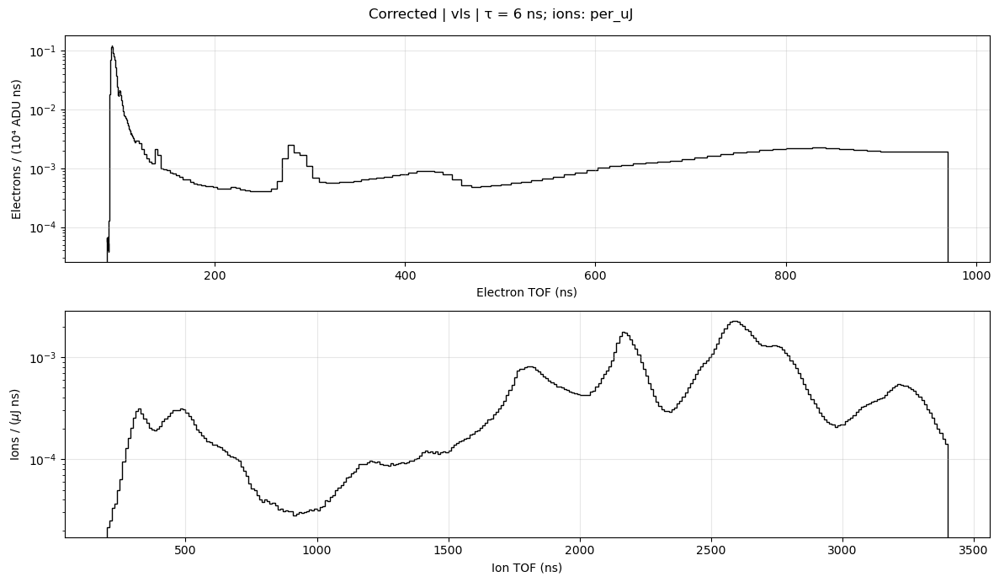

In [517]:
# Inspect the spectra in the original TOF coordinates.

etof_edges = axes['tof_edges'] / 10
itof_edges = axes['ion_tof_edges'] / 10

dtof_e = np.abs(np.diff(etof_edges))
dtof_i = np.diff(itof_edges)

fig, ax = plt.subplots(2, 1, figsize=(12, 7))

ax[0].stairs((ref_e * dke)[::-1] / dtof_e,
             etof_edges, color='k')

ax[1].stairs(ref_i * dmq / dtof_i,
             itof_edges, color='k')

ax[0].set(ylabel=f'Electrons / ({electron_unit} ns)',
          xlabel='Electron TOF (ns)', yscale='log')

ax[1].set(ylabel=f'Ions / ({unit} ns)',
          xlabel='Ion TOF (ns)', yscale='log')

for a in ax:
    a.grid(alpha=0.3)

fig.suptitle(electron_label + "; ions: " + NORMALISE)
fig.tight_layout()
plt.show()

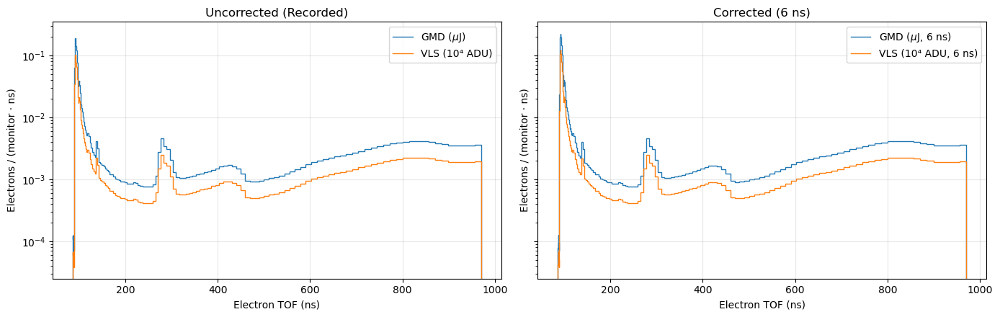

In [518]:
# ---- Uncorrected (GMD & VLS) vs. Corrected (GMD & VLS) on 1x2 --------

if not all_ready:
    raise ValueError('Valid ready files are required for all selected scans')

etof_edges = axes['tof_edges'] / 10
dtof_e = np.abs(np.diff(etof_edges))

fig, axes_row = plt.subplots(
    1, 2, figsize=(14, 4.5), sharex=True, sharey='row'
)
ax_uncorr, ax_corr = axes_row

monitors = [
    ('g', r'$\mu$J', 'GMD', 'C0'),
    ('m', '10⁴ ADU', 'VLS', 'C1'),
]

for key, label, monitor_name, color in monitors:
    exposure = electron_combined[key].sum()

    recorded = divide(
        electron_combined['e_recorded'].sum(axis=0),
        exposure
    )[::-1] / dtof_e

    corrected = divide(
        electron_combined['e_corrected'].sum(axis=0),
        exposure
    )[::-1] / dtof_e

    ax_uncorr.stairs(
        recorded, etof_edges,
        color=color, label=f'{monitor_name} ({label})'
    )
    ax_corr.stairs(
        corrected, etof_edges,
        color=color, label=f'{monitor_name} ({label}, {TAU_NS:g} ns)'
    )

ax_uncorr.set_title('Uncorrected (Recorded)')
ax_corr.set_title(f'Corrected ({TAU_NS:g} ns)')

for ax in axes_row:
    ax.set(
        xlabel='Electron TOF (ns)',
        ylabel='Electrons / (monitor · ns)',
        yscale='log'
    )
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

## 7. Temporal traces

Select the energy and mass windows after inspecting the spectra. Whole bins are selected by their centres; the actual edges are printed. The high-energy windows include direct photoelectrons; the hole assignments are tentative.

Recorded-electron error bars are approximate Poisson errors with fixed exposure (not including reference uncertainty, FEL fluctuations or detector systematics). Corrected-electron curves are plotted without error bars: the ready files do not contain corrected second moments. Section 4.2 remains the recorded/GMD statistical control.

### 7.1 Electron yields

Aggregates: AcH_short_delay_scan_268.7eV_2809924372_aggregates_tr.h5
Ready file: AcH_short_delay_scan_268.7eV_2809924372_aggregates_tr_ready.h5


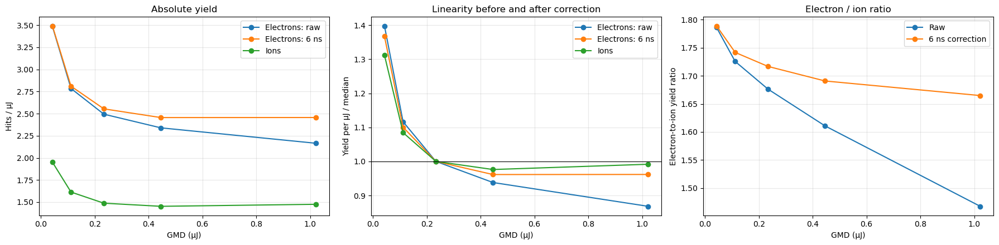

In [519]:
# Electron and ion linearity before and after dead-time correction
# Electron and ion linearity before and after dead-time correction

import h5py
from pathlib import Path

agg_path = COMBINED_DIR / "AcH_short_delay_scan_268.7eV_2809924372_aggregates_tr.h5"

ready_path = agg_path.with_name(agg_path.stem + "_ready.h5")

assert agg_path.exists(), f"Missing aggregates file: {agg_path}"
assert ready_path.exists(), f"Missing ready file: {ready_path}"

print("Aggregates:", agg_path.name)
print("Ready file:", ready_path.name)

with h5py.File(agg_path, "r") as f:
    n_shots = f["n_per_bin"][...]
    g_mean = f["G"][...]
    e_raw = f["D"][...].sum(axis=-1)
    i_raw = f["C"][...].sum(axis=-1)
    mode = f.attrs["mode"]

with h5py.File(ready_path, "r") as f:
    taus = f["taus_ns"][...]
    tau_idx = np.flatnonzero(np.isclose(taus, 6.0))

    assert len(tau_idx) == 1, "6 ns correction not found"
    assert np.array_equal(f["n_per_bin"][...], n_shots)

    assert np.allclose(
        f["D"][...].sum(axis=-1), e_raw, equal_nan=True
    ), "Ready file does not match aggregates"

    e_corr = f["D_live"][tau_idx[0]].sum(axis=-1)

# Keep the same cells for all three curves
valid = (
    (n_shots > 0)
    & np.isfinite(g_mean)
    & np.isfinite(e_raw)
    & np.isfinite(e_corr)
    & np.isfinite(i_raw)
)

weights = np.where(valid, n_shots, 0)

# Energy mode: (energy, GMD)
# Time-resolved mode: (GMD, delay)
if mode == "energy":
    sum_axis = 0
elif mode == "time_resolved":
    sum_axis = 1
elif mode == "spectral":
    sum_axis = ()
else:
    raise ValueError(f"Unknown aggregates mode: {mode}")

# Sum over energy or delay, weighted by shot numbers
g_sum = (np.where(valid, g_mean, 0) * weights).sum(axis=sum_axis)
e_sum = (np.where(valid, e_raw, 0) * weights).sum(axis=sum_axis)
ec_sum = (np.where(valid, e_corr, 0) * weights).sum(axis=sum_axis)
i_sum = (np.where(valid, i_raw, 0) * weights).sum(axis=sum_axis)

n_sum = weights.sum(axis=sum_axis)

m = (n_sum > 0) & (g_sum > 0) & (i_sum > 0)

g_plot = g_sum[m] / n_sum[m]

e_per_uj = e_sum[m] / g_sum[m]
ec_per_uj = ec_sum[m] / g_sum[m]
i_per_uj = i_sum[m] / g_sum[m]

ratio_raw = e_sum[m] / i_sum[m]
ratio_corr = ec_sum[m] / i_sum[m]

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))

# Absolute yield per µJ
axs[0].plot(g_plot, e_per_uj, "o-", label="Electrons: raw")
axs[0].plot(g_plot, ec_per_uj, "o-", label="Electrons: 6 ns")
axs[0].plot(g_plot, i_per_uj, "o-", label="Ions")
axs[0].set_ylabel("Hits / µJ")
axs[0].set_title("Absolute yield")

# Relative yield per µJ
for y, label in [
    (e_per_uj, "Electrons: raw"),
    (ec_per_uj, "Electrons: 6 ns"),
    (i_per_uj, "Ions"),
]:
    axs[1].plot(g_plot, y / np.median(y), "o-", label=label)

axs[1].axhline(1, color="k", lw=0.8)
axs[1].set_ylabel("Yield per µJ / median")
axs[1].set_title("Linearity before and after correction")

# Electron-to-ion ratio
axs[2].plot(g_plot, ratio_raw, "o-", label="Raw")
axs[2].plot(g_plot, ratio_corr, "o-", label="6 ns correction")
axs[2].set_ylabel("Electron-to-ion yield ratio")
axs[2].set_title("Electron / ion ratio")

for ax in axs:
    ax.set_xlabel("GMD (µJ)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

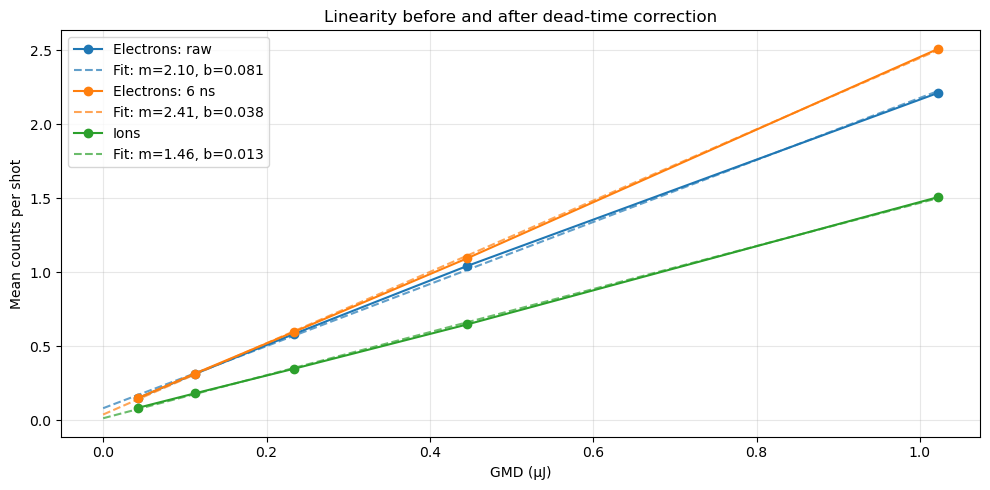

In [520]:
# Standard linearity plot before and after dead-time correction

fig, ax = plt.subplots(figsize=(10, 5))

for y, label, color in [
    (e_sum[m] / n_sum[m], "Electrons: raw", "C0"),
    (ec_sum[m] / n_sum[m], "Electrons: 6 ns", "C1"),
    (i_sum[m] / n_sum[m], "Ions", "C2"),
]:
    ax.plot(g_plot, y, "o-", color=color, label=label)

    # Linear fit with free intercept
    slope, intercept = np.polyfit(g_plot, y, 1)

    x_fit = np.linspace(0, g_plot.max(), 200)

    ax.plot(
        x_fit, slope * x_fit + intercept,
        "--", color=color, alpha=0.7,
        label=f"Fit: m={slope:.2f}, b={intercept:.3f}"
    )

ax.set_xlabel("GMD (µJ)")
ax.set_ylabel("Mean counts per shot")
ax.set_title("Linearity before and after dead-time correction")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Shots included: 1,129,259
Shots excluded relative to previous plot: 0


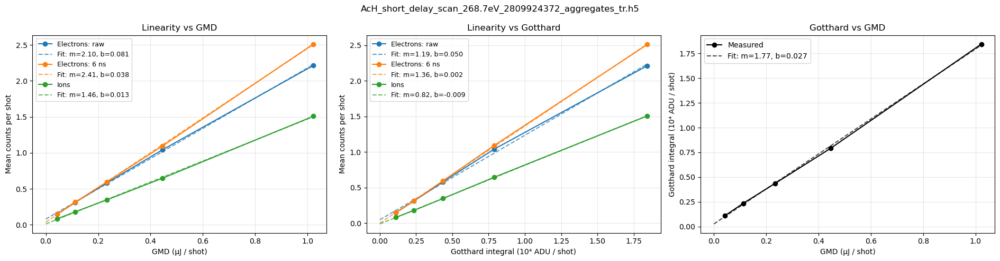

In [521]:
# Linearity using GMD and Gotthard as independent intensity monitors

with h5py.File(agg_path, "r") as f:
    # Same VLS integral convention as section 4.1
    vls_cell = f["A"][...].sum(axis=-1) / 1e4

assert vls_cell.shape == n_shots.shape

# Use identical populated cells for both monitors
lin_valid = (
    valid
    & np.isfinite(vls_cell)
    & (vls_cell > 0)
    & (g_mean > 0)
)

lin_weights = np.where(lin_valid, n_shots, 0)
lin_n = lin_weights.sum(axis=1)

lin_g = (np.where(lin_valid, g_mean, 0) * lin_weights).sum(axis=1)
lin_v = (np.where(lin_valid, vls_cell, 0) * lin_weights).sum(axis=1)

lin_e = (np.where(lin_valid, e_raw, 0) * lin_weights).sum(axis=1)
lin_ec = (np.where(lin_valid, e_corr, 0) * lin_weights).sum(axis=1)
lin_i = (np.where(lin_valid, i_raw, 0) * lin_weights).sum(axis=1)

lin_keep = (lin_n > 0) & (lin_g > 0) & (lin_v > 0)

lin_gmd = lin_g[lin_keep] / lin_n[lin_keep]
lin_vls = lin_v[lin_keep] / lin_n[lin_keep]

print(f"Shots included: {lin_n.sum():,}")
print(f"Shots excluded relative to previous plot: "
      f"{n_shots[valid].sum() - lin_n.sum():,}")

fig, axs = plt.subplots(1, 3, figsize=(19, 5))

for ax, x, xlabel in [
    (axs[0], lin_gmd, "GMD (µJ / shot)"),
    (axs[1], lin_vls, "Gotthard integral (10⁴ ADU / shot)")
]:

    for counts, label, color in [
        (lin_e, "Electrons: raw", "C0"),
        (lin_ec, "Electrons: 6 ns", "C1"),
        (lin_i, "Ions", "C2")
    ]:

        y = counts[lin_keep] / lin_n[lin_keep]

        ax.plot(x, y, "o-", color=color, label=label)

        if len(x) >= 2 and np.ptp(x) > 0:
            slope, intercept = np.polyfit(x, y, 1)
            x_fit = np.linspace(0, x.max(), 200)

            ax.plot(
                x_fit, slope*x_fit + intercept,
                "--", color=color, alpha=0.7,
                label=f"Fit: m={slope:.2f}, b={intercept:.3f}"
            )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Mean counts per shot")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

axs[0].set_title("Linearity vs GMD")
axs[1].set_title("Linearity vs Gotthard")

# Direct comparison between intensity monitors
axs[2].plot(lin_gmd, lin_vls, "ko-", label="Measured")

if len(lin_gmd) >= 2 and np.ptp(lin_gmd) > 0:
    slope, intercept = np.polyfit(lin_gmd, lin_vls, 1)
    x_fit = np.linspace(0, lin_gmd.max(), 200)

    axs[2].plot(
        x_fit, slope*x_fit + intercept,
        "k--", alpha=0.7,
        label=f"Fit: m={slope:.2f}, b={intercept:.3f}"
    )

axs[2].set_xlabel("GMD (µJ / shot)")
axs[2].set_ylabel("Gotthard integral (10⁴ ADU / shot)")
axs[2].set_title("Gotthard vs GMD")
axs[2].grid(alpha=0.3)
axs[2].legend()

fig.suptitle(agg_path.name)
plt.tight_layout()
plt.show()


10–40 eV | 155 GMD-delay cells
GMD (µJ / shot) | Raw: r=0.9975, slope=0.2310, intercept=+0.0056
GMD (µJ / shot) | 6 ns correction: r=0.9974, slope=0.2307, intercept=+0.0055
Gotthard integral (10⁴ ADU / shot) | Raw: r=0.9986, slope=0.1312, intercept=+0.0020
Gotthard integral (10⁴ ADU / shot) | 6 ns correction: r=0.9986, slope=0.1311, intercept=+0.0019

210–285 eV | 155 GMD-delay cells
GMD (µJ / shot) | Raw: r=0.9965, slope=0.8851, intercept=+0.0559
GMD (µJ / shot) | 6 ns correction: r=0.9984, slope=1.1913, intercept=+0.0150
Gotthard integral (10⁴ ADU / shot) | Raw: r=0.9951, slope=0.5015, intercept=+0.0431
Gotthard integral (10⁴ ADU / shot) | 6 ns correction: r=0.9992, slope=0.6765, intercept=-0.0033


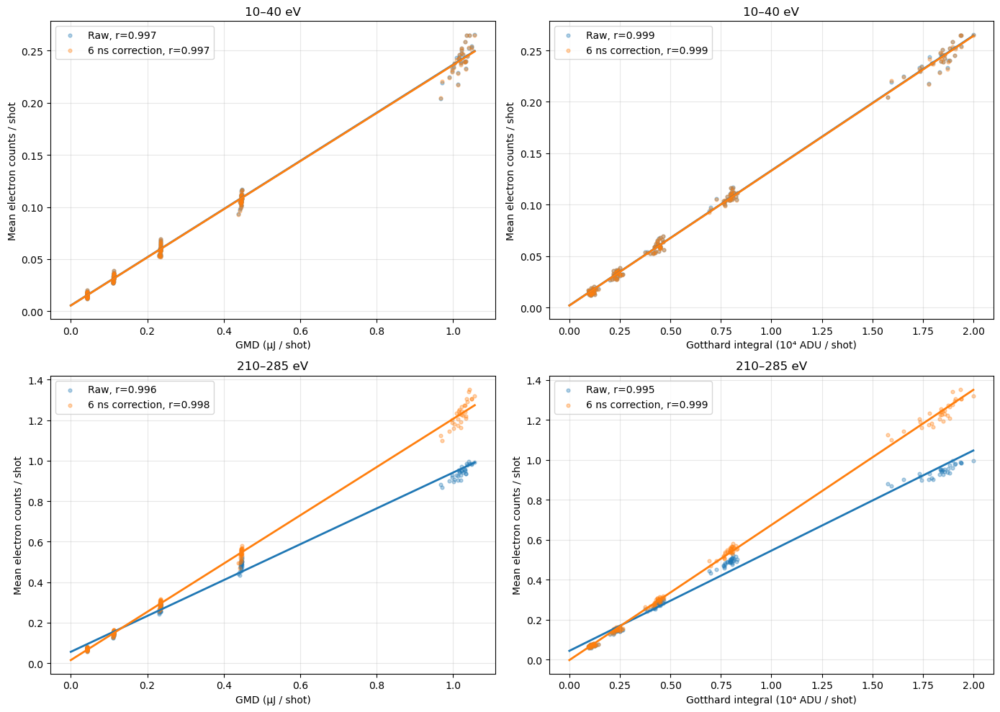

In [522]:
# GMD and VLS correlations before and after correction
# Retain individual GMD-delay cells

LINEARITY_WINDOWS = [
    (10, 40),
    (210, 285)
]

with h5py.File(agg_path, "r") as f:
    D_lin = f["D"][...]
    tof_edges_lin = f["tof_edges"][...]

with h5py.File(ready_path, "r") as f:
    Dm_lin = f["D_live"][tau_idx[0]]

assert D_lin.shape == Dm_lin.shape
assert D_lin.shape[:-1] == n_shots.shape

# KE bin centres in original TOF order
ke_edges_lin = calibration.ke_of_tof(tof_edges_lin / 10)
ke_lin = 0.5 * (ke_edges_lin[:-1] + ke_edges_lin[1:])

fig, axs = plt.subplots(
    len(LINEARITY_WINDOWS), 2,
    figsize=(14, 5*len(LINEARITY_WINDOWS)),
    squeeze=False
)

for j, (lo, hi) in enumerate(LINEARITY_WINDOWS):

    mask_lin = (ke_lin >= lo) & (ke_lin < hi)

    assert mask_lin.any(), f"No electron bins in {lo}–{hi} eV"

    y_raw = D_lin[..., mask_lin].sum(axis=-1)
    y_corr = Dm_lin[..., mask_lin].sum(axis=-1)

    sel_lin = (
        lin_valid
        & (n_shots >= MIN_SHOTS)
        & np.isfinite(y_raw)
        & np.isfinite(y_corr)
    )

    print(f"\n{lo}–{hi} eV | {sel_lin.sum()} GMD-delay cells")

    for k, (monitor, xlabel) in enumerate([
        (g_mean, "GMD (µJ / shot)"),
        (vls_cell, "Gotthard integral (10⁴ ADU / shot)")
    ]):

        ax = axs[j, k]

        for y, label, color in [
            (y_raw, "Raw", "C0"),
            (y_corr, "6 ns correction", "C1")
        ]:

            x = monitor[sel_lin]
            yy = y[sel_lin]

            if len(x) < 2 or np.ptp(x) == 0:
                continue

            slope, intercept = np.polyfit(x, yy, 1)

            r_lin = (
                np.corrcoef(x, yy)[0, 1]
                if np.ptp(yy) > 0 else np.nan
            )

            x_fit = np.linspace(0, x.max(), 200)

            ax.scatter(
                x, yy, s=12, alpha=0.35, color=color,
                label=f"{label}, r={r_lin:.3f}"
            )

            ax.plot(
                x_fit, slope*x_fit + intercept,
                color=color, lw=2
            )

            print(
                f"{xlabel} | {label}: "
                f"r={r_lin:.4f}, "
                f"slope={slope:.4f}, "
                f"intercept={intercept:+.4f}"
            )

        ax.set_xlabel(xlabel)
        ax.set_ylabel("Mean electron counts / shot")
        ax.set_title(f"{lo}–{hi} eV")
        ax.grid(alpha=0.3)
        ax.legend()

plt.tight_layout()
plt.show()

110–160 eV: actual edges 109.87–160.09 eV
210–220 eV: actual edges 209.91–220.26 eV
220–230 eV: actual edges 220.26–230.23 eV
230–240 eV: actual edges 230.23–240.29 eV
242–246 eV: actual edges 242.13–245.88 eV
246–250 eV: actual edges 245.88–249.72 eV
250–263 eV: actual edges 249.72–263.18 eV


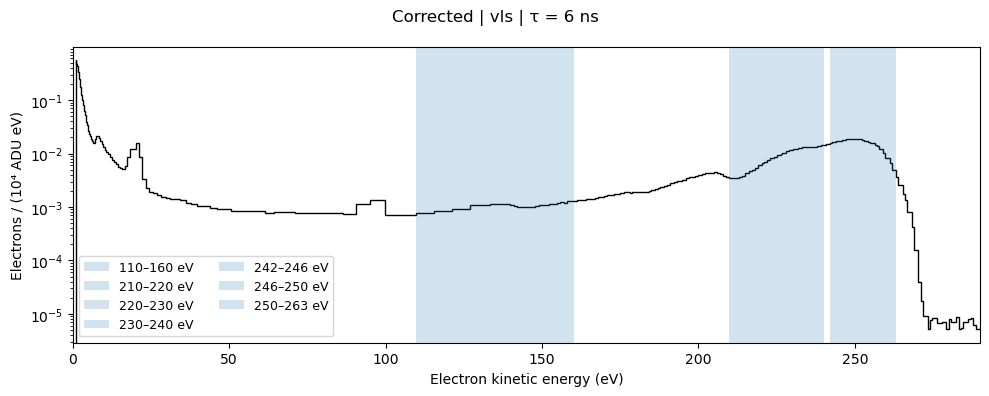

In [523]:
windows = {}
for lo, hi in ENERGY_WINDOWS:
    mask = (ke >= lo) & (ke < hi)
    if not mask.any():
        raise ValueError(f'No electron bins in {lo}–{hi} eV')
    idx = np.flatnonzero(mask)
    windows[(lo, hi)] = mask
    print(f'{lo}–{hi} eV: actual edges {ke_edges[idx[0]]:.2f}–{ke_edges[idx[-1]+1]:.2f} eV')

# Check the energy windows against the integrated spectrum.
fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(ref_e, ke_edges, color='k')
for (lo, hi), mask in windows.items():
    idx = np.flatnonzero(mask)
    ax.axvspan(ke_edges[idx[0]], ke_edges[idx[-1]+1], alpha=0.2, label=f'{lo}–{hi} eV')
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({electron_unit} eV)', xlim=KE_LIM, yscale='log')
ax.legend(ncol=2, fontsize=9)
fig.suptitle(electron_label)
fig.tight_layout()
plt.show()

### Correlation (recorded electrons, GMD diagnostics)


110–160 eV
Scan 1: r(GMD, e/shot) = +0.974, r(GMD, e/uJ) = +0.654
  Free fit: slope = 0.11729, intercept = -0.00901
  Zero intercept: slope = 0.09341
  Intercept / mean yield = -25.8%
Scan 2: r(GMD, e/shot) = +0.975, r(GMD, e/uJ) = +0.613
  Free fit: slope = 0.11430, intercept = -0.00691
  Zero intercept: slope = 0.09539
  Intercept / mean yield = -20.0%
Scan 3: r(GMD, e/shot) = +0.922, r(GMD, e/uJ) = +0.448
  Free fit: slope = 0.11947, intercept = -0.00863
  Zero intercept: slope = 0.09501
  Intercept / mean yield = -25.8%

210–220 eV
Scan 1: r(GMD, e/shot) = +0.966, r(GMD, e/uJ) = +0.534
  Free fit: slope = 0.09422, intercept = -0.00586
  Zero intercept: slope = 0.07867
  Intercept / mean yield = -19.9%
Scan 2: r(GMD, e/shot) = +0.969, r(GMD, e/uJ) = +0.164
  Free fit: slope = 0.08385, intercept = -0.00110
  Zero intercept: slope = 0.08083
  Intercept / mean yield = -3.8%
Scan 3: r(GMD, e/shot) = +0.900, r(GMD, e/uJ) = +0.374
  Free fit: slope = 0.09873, intercept = -0.00641
  Zero 

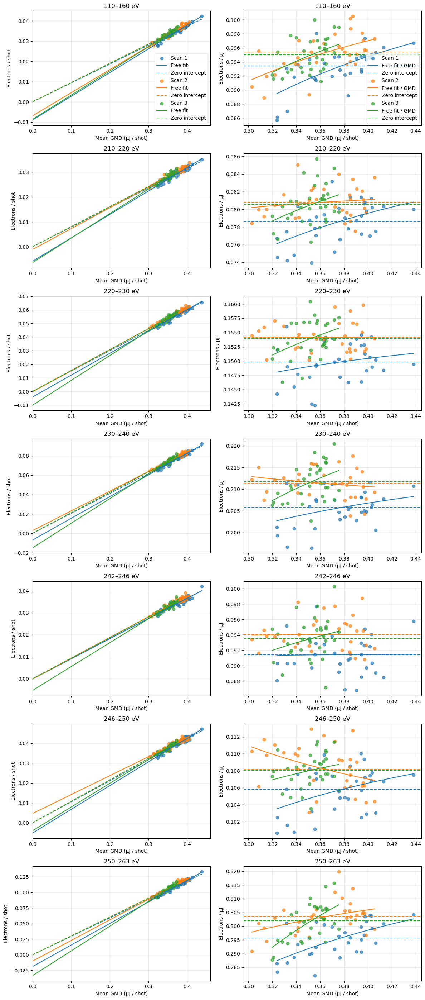

In [524]:
# Correlation between GMD and electron yields across delay bins


fig, ax = plt.subplots(len(windows), 2,
                       figsize=(12, 4 * len(windows)),
                       squeeze=False)

for j, ((lo, hi), mask) in enumerate(windows.items()):

    print(f'\n{lo}–{hi} eV')

    for i, (name, s) in enumerate(scans.items()):

        gmd = divide(s['g'], s['n'])
        counts = s['e'][:, mask].sum(axis=1)

        y_shot = divide(counts, s['n'])
        y_gmd = divide(counts, s['g'])

        valid = (np.isfinite(gmd) &
                 np.isfinite(y_shot) &
                 np.isfinite(y_gmd) &
                 (gmd > 0))

        x = gmd[valid]
        y = y_shot[valid]
        z = y_gmd[valid]

        if len(x) < 2 or np.ptp(x) == 0:
            continue

        r_shot = np.corrcoef(x, y)[0, 1]
        r_gmd = np.corrcoef(x, z)[0, 1]

        color = f'C{i}'

        # Electron yield per shot
        ax[j, 0].scatter(x, y, alpha=0.7,
                         color=color, label=f'Scan {i+1}')

        # Electron yield per µJ
        ax[j, 1].scatter(x, z, alpha=0.7,
                         color=color, label=f'Scan {i+1}')

        # Linear fit with free intercept
        a, b = np.polyfit(x, y, 1)

        # Linear fit forced through zero
        a0 = np.sum(x * y) / np.sum(x**2)

        x_fit = np.linspace(0 if SHOW_ORIGIN else x.min(),
                            x.max(), 200)

        ax[j, 0].plot(x_fit, a * x_fit + b,
                      color=color, label='Free fit')

        ax[j, 0].plot(x_fit, a0 * x_fit,
                      '--', color=color, label='Zero intercept')

        # Expected normalised yield from the free fit:
        # y / GMD = a + b / GMD
        x_fit_norm = np.linspace(x.min(), x.max(), 200)

        ax[j, 1].plot(x_fit_norm, a + b / x_fit_norm,
                      color=color, label='Free fit / GMD')

        ax[j, 1].axhline(a0, linestyle='--',
                        color=color, label='Zero intercept')

        print(f'Scan {i+1}: '
              f'r(GMD, e/shot) = {r_shot:+.3f}, '
              f'r(GMD, e/uJ) = {r_gmd:+.3f}')

        print(f'  Free fit: slope = {a:.5f}, intercept = {b:+.5f}')
        print(f'  Zero intercept: slope = {a0:.5f}')
        print(f'  Intercept / mean yield = {100 * b / y.mean():+.1f}%')

    ax[j, 0].set(ylabel='Electrons / shot',
                 title=f'{lo}–{hi} eV')

    ax[j, 1].set(ylabel='Electrons / µJ',
                 title=f'{lo}–{hi} eV')

    if SHOW_ORIGIN:
        ax[j, 0].set_xlim(left=0)
        ax[j, 0].set_ylim(bottom=min(0, ax[j, 0].get_ylim()[0]))

for a in ax.flat:
    a.set_xlabel('Mean GMD (µJ / shot)')
    a.grid(alpha=0.3)

ax[0, 0].legend()
ax[0, 1].legend()

fig.tight_layout()
plt.show()


Scan 1
GMD edges (µJ): [0.02000043 0.10877529 0.20679712 0.3461515  0.58338189 4.44622564]
Aggregate shape: (5, 32)
110–160 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.00216
210–220 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.00286
220–230 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.00757
230–240 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.01373
242–246 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.00705
246–250 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.00773
250–263 eV: 160 points | GMD = 0.063–0.973 µJ | Intercept = +0.01373

Scan 2
GMD edges (µJ): [0.02000012 0.10562693 0.20081677 0.3349231  0.56334727 4.43928814]
Aggregate shape: (5, 32)
110–160 eV: 160 points | GMD = 0.062–0.927 µJ | Intercept = +0.00203
210–220 eV: 160 points | GMD = 0.062–0.927 µJ | Intercept = +0.00310
220–230 eV: 160 points | GMD = 0.062–0.927 µJ | Intercept = +0.00781
230–240 eV: 160 points | GMD = 0.062–0.927 µJ | Intercept = +0.01393
242–246

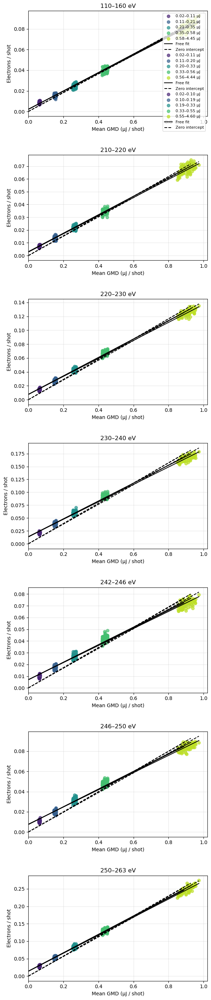

In [525]:
# Correlation between GMD and electron yields,
# retaining both GMD and delay bins


fig, ax = plt.subplots(len(windows), 1,
                       figsize=(6, 4 * len(windows)),
                       squeeze=False)
ax = ax[:, 0]

for i, path in enumerate(FILES):

    with h5py.File(path, 'r') as f:
        n_gmd = f['n_per_bin'][:]
        D_gmd = f['D'][:][..., ::-1]
        G_gmd = f['G'][:]
        gmd_edges = f['gmd_edges'][:]

    print(f'\nScan {i+1}')
    print('GMD edges (µJ):', gmd_edges)
    print('Aggregate shape:', n_gmd.shape)

    colors = plt.cm.viridis(
        np.linspace(0.1, 0.9, len(gmd_edges)-1))

    for j, ((lo, hi), mask) in enumerate(windows.items()):

        # D and G are already means per shot.
        y_shot = D_gmd[..., mask].sum(axis=-1)

        valid = ((n_gmd >= MIN_SHOTS) &
                 np.isfinite(G_gmd) &
                 np.isfinite(y_shot) &
                 (G_gmd > 0))

        # Plot each GMD bin separately.
        for k, color in enumerate(colors):

            sel = valid[k]

            label = (f'{gmd_edges[k]:.2f}–'
                     f'{gmd_edges[k+1]:.2f} µJ')

            ax[j].scatter(G_gmd[k, sel], y_shot[k, sel],
                          color=color, alpha=0.7,
                          label=label)

        # Fit all populated GMD-delay bins.
        x = G_gmd[valid]
        y = y_shot[valid]

        if len(x) < 2 or np.ptp(x) == 0:
            continue

        a, b = np.polyfit(x, y, 1)
        a0 = np.sum(x * y) / np.sum(x**2)

        x_fit = np.linspace(0 if SHOW_ORIGIN else x.min(),
                            x.max(), 200)

        ax[j].plot(x_fit, a * x_fit + b,
                   'k-', label='Free fit')

        ax[j].plot(x_fit, a0 * x_fit,
                   'k--', label='Zero intercept')

        print(f'{lo}–{hi} eV: {len(x)} points | '
              f'GMD = {x.min():.3f}–{x.max():.3f} µJ | '
              f'Intercept = {b:+.5f}')

for j, (lo, hi) in enumerate(windows):

    ax[j].set(title=f'{lo}–{hi} eV',
              ylabel='Electrons / shot')

    if SHOW_ORIGIN:
        ax[j].set_xlim(left=0)
        ax[j].set_ylim(
            bottom=min(0, ax[j].get_ylim()[0]))

for a in ax:
    a.set_xlabel('Mean GMD (µJ / shot)')
    a.grid(alpha=0.3)

ax[0].legend(fontsize=8)

fig.tight_layout()
plt.show()

110–160 eV: 253,146 recorded electrons; 252,971 in selected spectrum
210–220 eV: 214,196 recorded electrons; 222,908 in selected spectrum
220–230 eV: 408,791 recorded electrons; 452,531 in selected spectrum
230–240 eV: 561,258 recorded electrons; 656,524 in selected spectrum
242–246 eV: 249,085 recorded electrons; 307,544 in selected spectrum
246–250 eV: 287,440 recorded electrons; 350,847 in selected spectrum
250–263 eV: 804,095 recorded electrons; 892,661 in selected spectrum


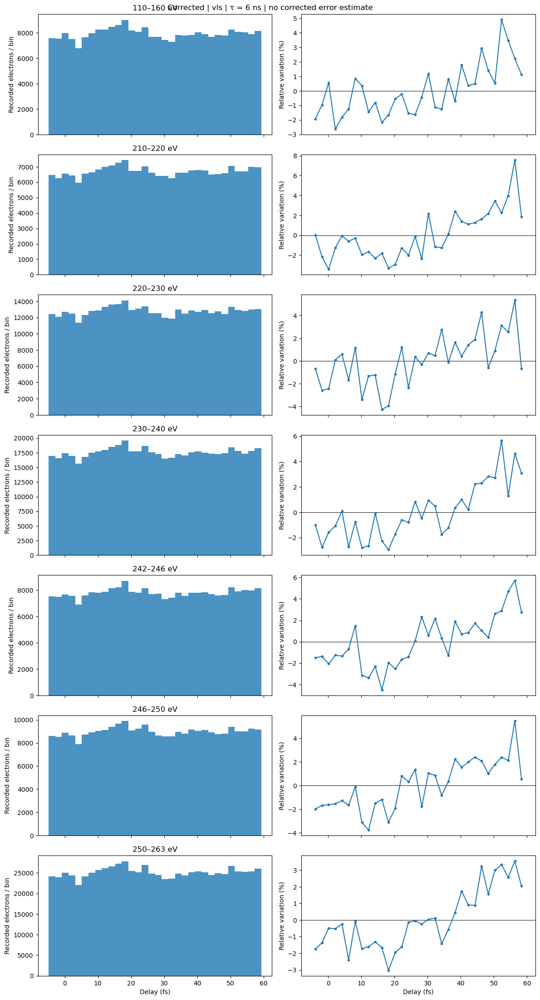

In [526]:
# Integrate counts (not counts/eV) in the selected windows.
def electron_trace(s, mask, relative=False):
    counts = s['e'][:, mask].sum(axis=1)
    exposure = s[electron_exposure_key]
    y = divide(counts, exposure)
    # Corrected counts are not independent Poisson observations.
    err = None if USE_READY else divide(np.sqrt(counts), exposure)
    if err is not None:
        err[counts == 0] = np.nan
    if relative:
        ref = delay_reference(counts, exposure)
        y = 100 * (divide(y, ref) - 1)
        if err is not None:
            err = 100 * divide(err, ref)
    return counts, y, err

fig, ax = plt.subplots(len(windows), 2, figsize=(12, 3.2 * len(windows)),
                       sharex=True, squeeze=False)
for row, ((lo, hi), mask) in enumerate(windows.items()):
    counts, y, err = electron_trace(electron_combined, mask, RELATIVE_TRACES)
    raw_counts = electron_combined['e_recorded'][:, mask].sum(axis=1)
    ax[row, 0].bar(delay, raw_counts, width=np.diff(delay_edges), alpha=0.8)
    ax[row, 1].errorbar(delay, y, yerr=err, fmt='.-', capsize=2)
    if RELATIVE_TRACES:
        ax[row, 1].axhline(0, color='k', linewidth=0.7)
    ax[row, 0].set(ylabel='Recorded electrons / bin', title=f'{lo}–{hi} eV')
    ax[row, 1].set_ylabel('Relative variation (%)' if RELATIVE_TRACES else f'Electrons / {electron_unit}')
    print(f'{lo}–{hi} eV: {raw_counts.sum():,.0f} recorded electrons; '
          f'{counts.sum():,.0f} in selected spectrum')
for a in ax[-1]:
    a.set_xlabel('Delay (fs)')
fig.suptitle(electron_label + (' | no corrected error estimate' if USE_READY else ' | Poisson errors'))
fig.tight_layout()
plt.show()

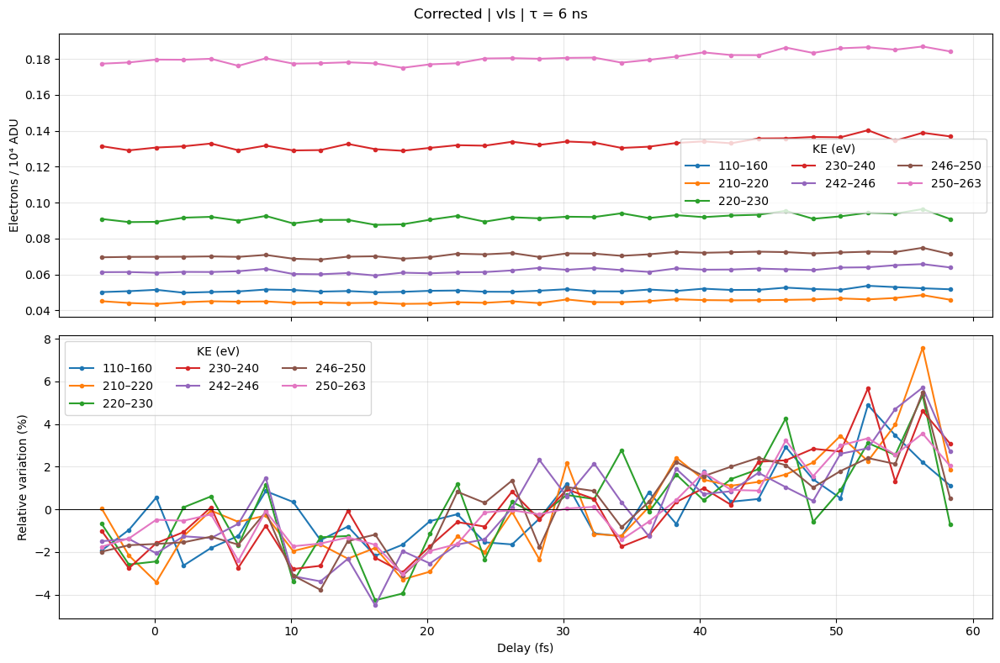

In [527]:
# Absolute and relative exposure-normalised electron yields.

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for (lo, hi), mask in windows.items():

    counts = electron_combined['e'][:, mask].sum(axis=1)
    exposure = electron_combined[electron_exposure_key]

    y = divide(counts, exposure)
    ref = delay_reference(counts, exposure)

    relative = 100 * (divide(y, ref) - 1)

    ax[0].plot(delay, y, '.-', label=f'{lo}–{hi}')
    ax[1].plot(delay, relative, '.-', label=f'{lo}–{hi}')

ax[0].set_ylabel(f'Electrons / {electron_unit}')
ax[1].set_ylabel('Relative variation (%)')
ax[1].set_xlabel('Delay (fs)')
ax[1].axhline(0, color='k', linewidth=0.7)

for a in ax:
    a.legend(ncol=3, title='KE (eV)')
    a.grid(alpha=0.3)

fig.suptitle(electron_label)
fig.tight_layout()
plt.show()

### 7.2 Ion yields

0.5–1.5 u/e: actual edges 0.49–1.49
12–16 u/e: actual edges 12.01–16.05
19–21 u/e: actual edges 19.00–21.05
27–32 u/e: actual edges 26.94–31.89
43–45 u/e: actual edges 43.05–44.98


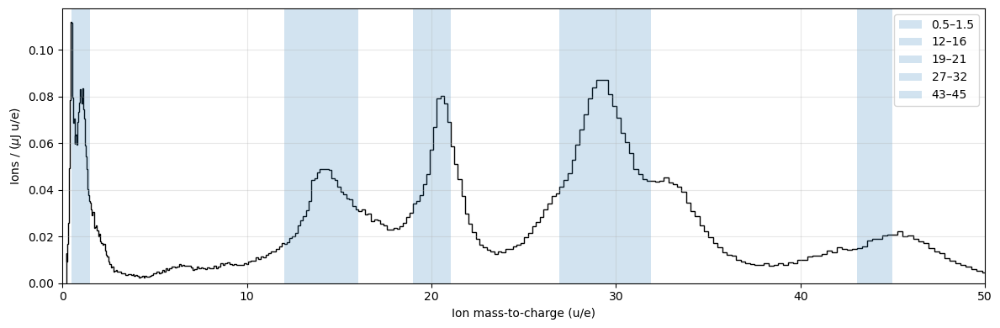

In [213]:
ion_windows = {}

fig, ax = plt.subplots(figsize=(12, 4))
ax.stairs(ref_i, mq_edges, color='k')

for lo, hi in ION_YIELD_WINDOWS:

    mask = (mq >= lo) & (mq < hi)

    if not mask.any():
        raise ValueError(f'No ion bins in {lo}–{hi} u/e')

    ion_windows[(lo, hi)] = mask
    idx = np.flatnonzero(mask)

    print(f'{lo}–{hi} u/e: actual edges '
          f'{mq_edges[idx[0]]:.2f}–{mq_edges[idx[-1]+1]:.2f}')

    ax.axvspan(mq_edges[idx[0]], mq_edges[idx[-1]+1],
               alpha=0.2, label=f'{lo}–{hi}')

ax.set(xlabel='Ion mass-to-charge (u/e)',
       ylabel=f'Ions / ({unit} u/e)',
       xlim=MQ_LIM)

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

0.5–1.5 u/e: 81,782 ions; median 2,587 / bin
12–16 u/e: 177,587 ions; median 5,690 / bin
19–21 u/e: 146,664 ions; median 4,718 / bin
27–32 u/e: 397,863 ions; median 12,724 / bin
43–45 u/e: 43,124 ions; median 1,394 / bin


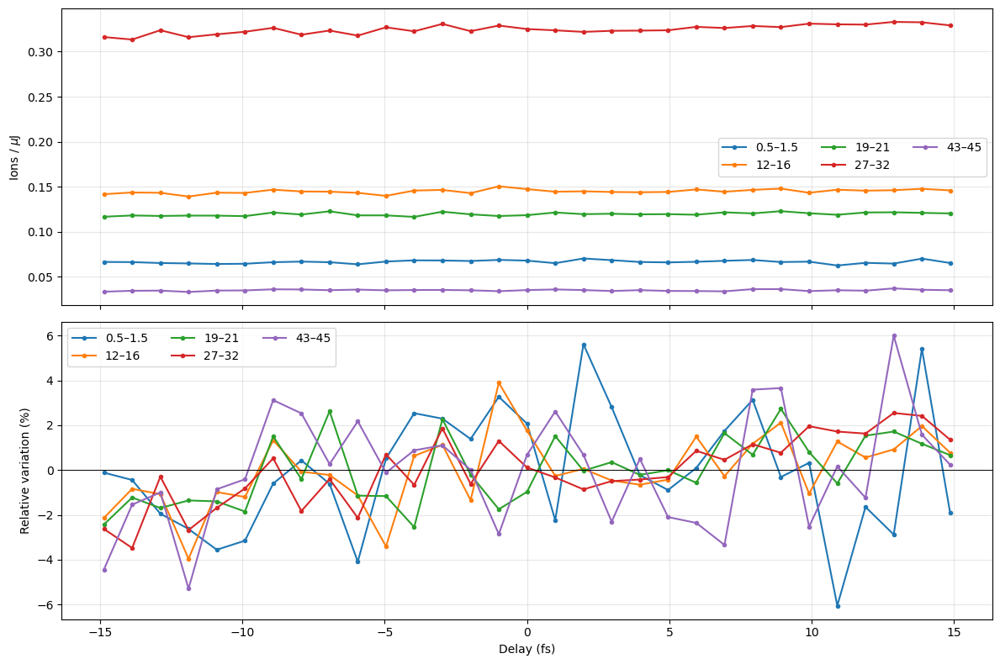

In [256]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for (lo, hi), mask in ion_windows.items():

    counts = combined['i'][:, mask].sum(axis=1)
    exposure = combined[exposure_key]

    y = divide(counts, exposure)
    ref = delay_reference(counts, exposure)

    relative = 100 * (divide(y, ref) - 1)

    ax[0].plot(delay, y, '.-', label=f'{lo}–{hi}')
    ax[1].plot(delay, relative, '.-', label=f'{lo}–{hi}')

    print(f'{lo}–{hi} u/e: {counts.sum():,.0f} ions; '
          f'median {np.median(counts):,.0f} / bin')

ax[0].set_ylabel(f'Ions / {unit}')
ax[1].set_ylabel('Relative variation (%)')
ax[1].set_xlabel('Delay (fs)')
ax[1].axhline(0, color='k', linewidth=0.7)

for a in ax:
    a.legend(ncol=3)
    a.grid(alpha=0.3)

fig.tight_layout()
plt.show()

### 7.3 GMD-bin comparison

Check the electron traces in different pulse-energy bins for one selected scan. This diagnostic deliberately uses all GMD bins in that file, independent of `GMD_BINS`, and follows `MONITOR` and `USE_READY`. The GMD labels still identify the original intensity bins.

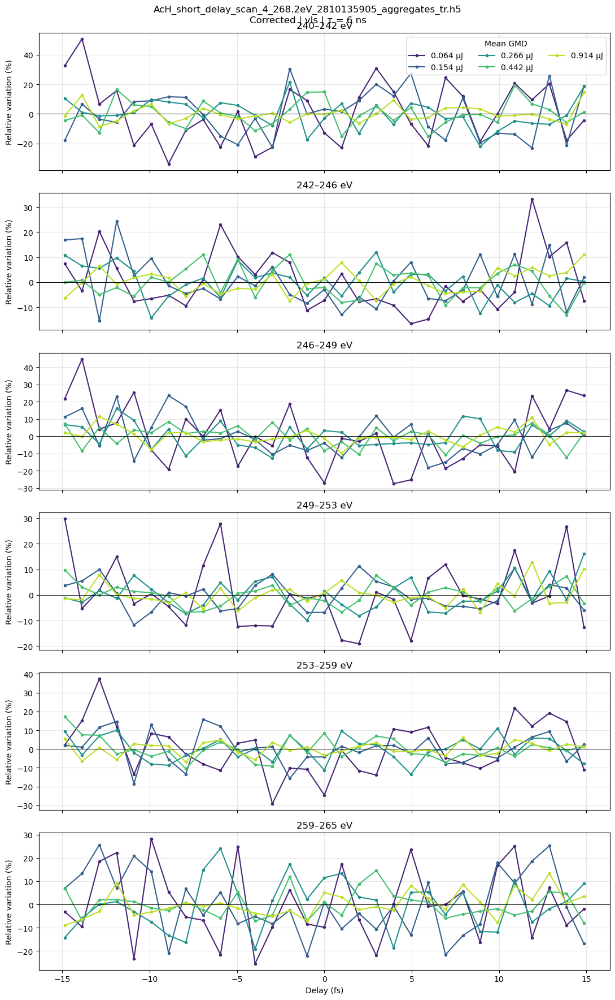

In [257]:
GMD_FILE = FILES[-1]




r = ready_scans[GMD_FILE.name]
n_gmd = r['n']
D_gmd = r['Dm'] if USE_READY else r['D']
G_gmd = r['G']
M_gmd = r['M']
gmd_edges = r['gmd_edges']
# This plot uses all bins, including any not selected for the main analysis.
if USE_READY and not np.isfinite(D_gmd[n_gmd > 0]).all():
    print('Warning: invalid corrected cells in unselected GMD bins; shown as gaps.')

# Convert means to counts and total pulse energy.
e_gmd = np.where(n_gmd[..., None] > 0, D_gmd, 0) * n_gmd[..., None]
g_gmd = np.where(n_gmd > 0, G_gmd, 0) * n_gmd
m_gmd = np.where(n_gmd > 0, M_gmd, 0) * n_gmd

# Reverse electron TOF to increasing kinetic energy.
e_gmd = e_gmd[..., ::-1]

if DELAY_SIGN == -1:
    e_gmd = e_gmd[:, ::-1]
    g_gmd = g_gmd[:, ::-1]
    m_gmd = m_gmd[:, ::-1]
    n_gmd = n_gmd[:, ::-1]

exposure_gmd = {'vls': m_gmd, 'gmd': g_gmd, 'shot': n_gmd}[MONITOR]

colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(gmd_edges)-1))

fig, ax = plt.subplots(len(GMD_ENERGY_WINDOWS), 1,
                       figsize=(11, 3 * len(GMD_ENERGY_WINDOWS)),
                       sharex=True, squeeze=False)

for a, (lo, hi) in zip(ax[:, 0], GMD_ENERGY_WINDOWS):

    mask = (ke >= lo) & (ke < hi)

    if not mask.any():
        raise ValueError(f'No electron bins in {lo}–{hi} eV')

    for j, color in enumerate(colors):

        counts = e_gmd[j][:, mask].sum(axis=1)
        y = divide(counts, exposure_gmd[j])

        mean_gmd = divide(g_gmd[j].sum(), n_gmd[j].sum())

        if GMD_RELATIVE:
            valid_ref = ref_mask & np.isfinite(counts) & (exposure_gmd[j] > 0)
            ref = divide(counts[valid_ref].sum(), exposure_gmd[j, valid_ref].sum())
            y = 100 * (divide(y, ref) - 1)

        a.plot(delay, y, '.-', color=color,
               label=f'{mean_gmd:.3f} µJ')

    a.set_title(f'{lo}–{hi} eV')
    a.set_ylabel('Relative variation (%)' if GMD_RELATIVE
                 else f'Electrons / {electron_unit}')

    if GMD_RELATIVE:
        a.axhline(0, color='k', linewidth=0.7)

    a.grid(alpha=0.3)

ax[0, 0].legend(ncol=3, title='Mean GMD')
ax[-1, 0].set_xlabel('Delay (fs)')

fig.suptitle(Path(GMD_FILE).name + '\n' + electron_label)
fig.tight_layout()
plt.show()

## 8. Comparison between scans

Compare absolute, exposure-normalised traces rather than centring each individual scan independently; otherwise run-to-run offsets could disappear. The pooled trace is weighted by exposure. Uses the selected electron correction and monitor; corrected curves have no statistical error bars.

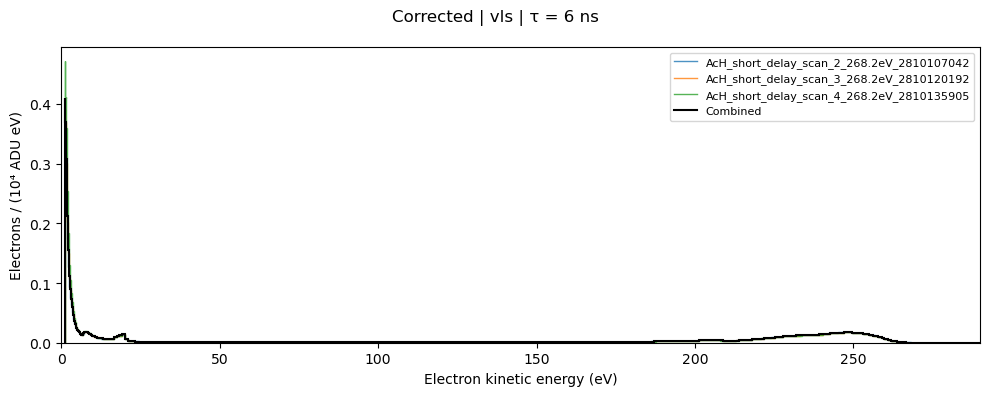

In [258]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, s in electron_scans.items():
    spectrum = divide(s['e'].sum(axis=0), s[electron_exposure_key].sum()) / dke
    ax.stairs(spectrum, ke_edges, label=name.replace('_aggregates_tr.h5', ''), alpha=0.8)
ax.stairs(ref_e, ke_edges, color='k', linewidth=1.5, label='Combined')
ax.set(xlabel='Electron kinetic energy (eV)', ylabel=f'Electrons / ({electron_unit} eV)', xlim=KE_LIM)
ax.legend(fontsize=8)
fig.suptitle(electron_label)
fig.tight_layout()
plt.show()

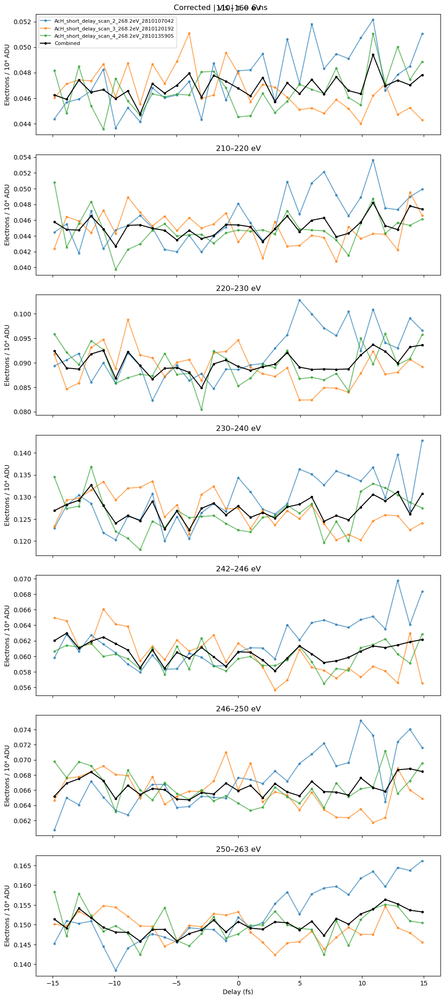

In [259]:
fig, ax = plt.subplots(len(windows), 1, figsize=(10, 3.2 * len(windows)),
                       sharex=True, squeeze=False)
for a, ((lo, hi), mask) in zip(ax[:, 0], windows.items()):
    for name, s in electron_scans.items():
        _, y, err = electron_trace(s, mask)
        a.errorbar(delay, y, yerr=err, fmt='.-', alpha=0.65,
                   label=name.replace('_aggregates_tr.h5', ''))
    _, y, err = electron_trace(electron_combined, mask)
    a.errorbar(delay, y, yerr=err, fmt='k.-', linewidth=1.5, label='Combined')
    a.set(title=f'{lo}–{hi} eV', ylabel=f'Electrons / {electron_unit}')
ax[0, 0].legend(fontsize=8)
ax[-1, 0].set_xlabel('Delay (fs)')
fig.suptitle(electron_label)
fig.tight_layout()
plt.show()

## 9. Covariance

Compare total covariance, covariance calculated within GMD bins, and partial covariance with the linear GMD contribution removed. Moments are pooled with shot weights at each delay, using only GMD-delay cells meeting the minimum shot count and positive finite GMD variance. These are covariance observables, not true coincidences.

The electron–electron maps and gates exclude pairs near the TOF diagonal. The dead-time cut is a detector diagnostic, not a correction for missing pairs. No temporal smoothing or fit is applied. The approximate standard-error maps are diagnostic scales, not significance tests.

### 9.1 Calculate time-resolved covariance

In [260]:
# ---- Time-resolved covariance -----------------------------------------------

# COV_FILES = FILES[-1:]       # Latest scan only







# Merge neighbouring bins, retaining the final group.
def rebin_edges(edges, factor):
    return np.r_[edges[:-1:factor], edges[-1]]


cov_ke_edges = rebin_edges(ke_edges, REBIN_E)
cov_mq_edges = rebin_edges(mq_edges, REBIN_I)

cov_ke = (cov_ke_edges[1:] + cov_ke_edges[:-1]) / 2
cov_mq = (cov_mq_edges[1:] + cov_mq_edges[:-1]) / 2

cov_dke = np.diff(cov_ke_edges)
cov_dmq = np.diff(cov_mq_edges)

ne, ni, nz = len(cov_ke), len(cov_mq), len(delay)

idx_e = np.arange(0, len(ke_edges)-1, REBIN_E)
idx_i = np.arange(0, len(mq_edges)-1, REBIN_I)


def rebin_vector(x, idx):
    return np.add.reduceat(x, idx)


def rebin_matrix(x, idx1, idx2):
    x = np.add.reduceat(x, idx1, axis=0)
    return np.add.reduceat(x, idx2, axis=1)


# Covariance estimates: delay is the first axis.
print(f'Matrix storage estimate: {3 * nz * (ne*ne + ni*ni + ne*ni) * 8 / 1e6:.1f} MB')
EST = {
    name: {
        'DD': np.zeros((nz, ne, ne)),
        'CC': np.zeros((nz, ni, ni)),
        'DC': np.zeros((nz, ne, ni))
    }
    for name in ['total', 'within GMD bins', 'partial on GMD']
}

n_cov = np.zeros(nz)
g_cov = np.zeros(nz)

D_sum = np.zeros((nz, ne))
C_sum = np.zeros((nz, ni))


for path in COV_FILES:

    with h5py.File(path, 'r') as f:

        if any(not np.array_equal(f[key][:], axes[key])
               for key in axes):
            raise ValueError(f'{Path(path).name}: incompatible bin edges')

        n = f['n_per_bin'][:]

        bins = (range(n.shape[0]) if COV_GMD_BINS is None
                else COV_GMD_BINS)

        n_used = 0

        for j in bins:
            for k in range(nz):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                G = f['G'][j, k]
                GG = f['GtG'][j, k]
                vG = GG - G**2

                if not np.isfinite(vG) or vG <= 0:
                    continue

                # Index on the calibrated, increasing delay axis.
                iz = k if DELAY_SIGN == 1 else nz - 1 - k

                # First moments, in increasing KE and m/q.
                D = rebin_vector(f['D'][j, k][::-1], idx_e)
                C = rebin_vector(f['C'][j, k], idx_i)

                # Second moments.
                DD = rebin_matrix(f['DtD'][j, k][::-1, ::-1],
                                  idx_e, idx_e)
                CC = rebin_matrix(f['CtC'][j, k],
                                  idx_i, idx_i)
                DC = rebin_matrix(f['DtC'][j, k][::-1, :],
                                  idx_e, idx_i)

                DG = rebin_vector(f['DtG'][j, k][::-1], idx_e)
                CG = rebin_vector(f['CtG'][j, k], idx_i)

                # Covariance within each GMD-delay cell.
                cDD = DD - np.outer(D, D)
                cCC = CC - np.outer(C, C)
                cDC = DC - np.outer(D, C)

                cDG = DG - D * G
                cCG = CG - C * G

                # Partial covariance on GMD.
                pDD = cDD - np.outer(cDG, cDG) / vG
                pCC = cCC - np.outer(cCG, cCG) / vG
                pDC = cDC - np.outer(cDG, cCG) / vG

                # Accumulate moments and covariance weighted by shots.
                D_sum[iz] += N * D
                C_sum[iz] += N * C

                for key, M in zip(['DD', 'CC', 'DC'], [DD, CC, DC]):
                    EST['total'][key][iz] += N * M

                for key, M in zip(['DD', 'CC', 'DC'], [cDD, cCC, cDC]):
                    EST['within GMD bins'][key][iz] += N * M

                for key, M in zip(['DD', 'CC', 'DC'], [pDD, pCC, pDC]):
                    EST['partial on GMD'][key][iz] += N * M

                n_cov[iz] += N
                g_cov[iz] += N * G
                n_used += N

    print(f'{Path(path).name}: {n_used:,.0f} shots used')


# Convert accumulated sums back to means.
mD_cov = divide(D_sum, n_cov[:, None])
mC_cov = divide(C_sum, n_cov[:, None])
mean_G_cov = divide(g_cov, n_cov)

for name, E in EST.items():
    for key in ['DD', 'CC', 'DC']:
        np.divide(E[key], n_cov[:, None, None],
                  out=E[key],
                  where=n_cov[:, None, None] > 0)

        E[key][n_cov == 0] = np.nan


# Total covariance: subtract products of the pooled first moments.
for k in range(nz):
    EST['total']['DD'][k] -= np.outer(mD_cov[k], mD_cov[k])
    EST['total']['CC'][k] -= np.outer(mC_cov[k], mC_cov[k])
    EST['total']['DC'][k] -= np.outer(mD_cov[k], mC_cov[k])


# Mask electron pairs by the separation of their TOF bin centres.

cov_tof = calibration.tof_of_ke(cov_ke)

delta_tof = np.abs(cov_tof[:, None] - cov_tof[None, :])

band = delta_tof <= DEAD_TIME_NS

print(f'\nTotal shots used: {n_cov.sum():,.0f}')
print(f'Electron bins: {ne}; ion bins: {ni}; delay bins: {nz}')
print(f'Median shots per delay: {np.median(n_cov):,.0f}')

print(f'Matrix storage: '
      f'{sum(M.nbytes for E in EST.values() for M in E.values()) / 1e6:.1f} MB')

Matrix storage estimate: 96.3 MB


AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5: 1,169,112 shots used
AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5: 1,171,918 shots used
AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5: 1,173,952 shots used

Total shots used: 3,514,982
Electron bins: 252; ion bins: 160; delay bins: 31
Median shots per delay: 113,381
Matrix storage: 96.3 MB


### 9.2 Electron pair detection

Observed pair moments relative to the independent-electron expectation within each GMD-delay cell. Used to inspect the dead-time region.

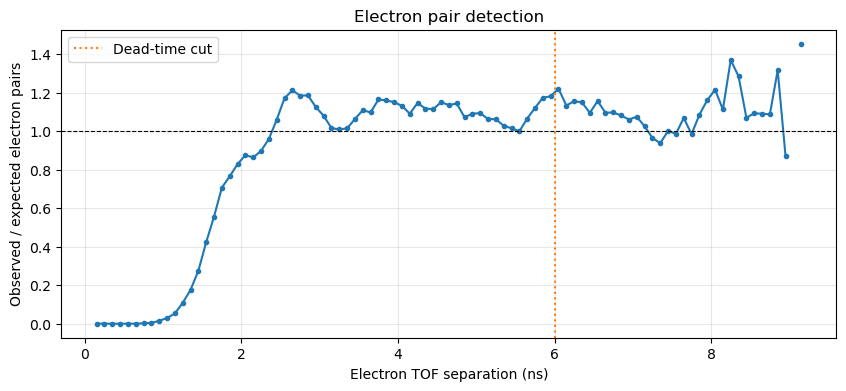

In [261]:
# ---- Electron pair detection vs TOF separation -----------------------------


dt_edges = np.arange(0, DT_MAX + DT_STEP, DT_STEP)
dt = (dt_edges[:-1] + dt_edges[1:]) / 2

observed = np.zeros(len(dt))
expected = np.zeros(len(dt))

tof = calibration.tof_of_ke(cov_ke)

delta_tof = np.abs(tof[:, None] - tof[None, :])

gate = ((cov_ke >= DEAD_TIME_KE[0]) &
        (cov_ke < DEAD_TIME_KE[1]))

# Use each electron pair once and exclude the diagonal.
pair_mask = (gate[:, None] & gate[None, :] &
             np.triu(np.ones((ne, ne), dtype=bool), k=1))

for path in COV_FILES:

    with h5py.File(path, 'r') as f:

        n = f['n_per_bin'][:]

        bins = (range(n.shape[0]) if COV_GMD_BINS is None
                else COV_GMD_BINS)

        for j in bins:
            for k in range(n.shape[1]):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                D = rebin_vector(f['D'][j, k][::-1], idx_e)

                DD = rebin_matrix(
                    f['DtD'][j, k][::-1, ::-1], idx_e, idx_e)

                independent = np.outer(D, D)

                observed += np.histogram(
                    delta_tof[pair_mask],
                    bins=dt_edges,
                    weights=N * DD[pair_mask])[0]

                expected += np.histogram(
                    delta_tof[pair_mask],
                    bins=dt_edges,
                    weights=N * independent[pair_mask])[0]

ratio = divide(observed, expected)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(dt, ratio, '.-')
ax.axvline(DEAD_TIME_NS, color='C1', ls=':', label='Dead-time cut')
ax.legend()
ax.axhline(1, color='k', ls='--', lw=0.8)

ax.set(xlabel='Electron TOF separation (ns)',
       ylabel='Observed / expected electron pairs',
       title='Electron pair detection')

ax.grid(alpha=0.3)

plt.show()

### 9.3 Delay-integrated electron–electron covariance

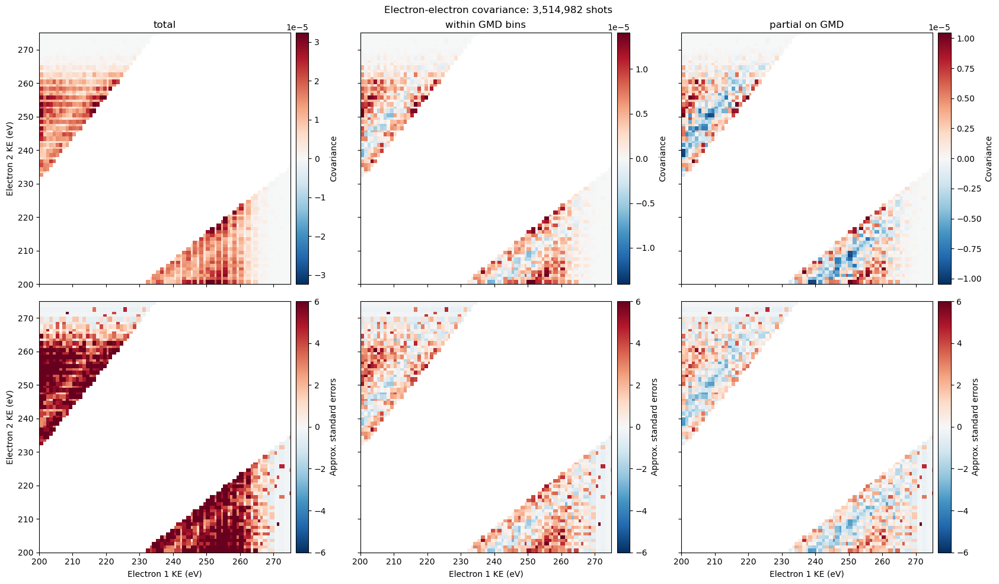

In [262]:
# ---- Delay-integrated electron-electron covariance ---------------------------




if COV_DELAY_WINDOW is None:
    cov_delay_mask = n_cov > 0
else:
    lo, hi = COV_DELAY_WINDOW
    cov_delay_mask = (delay >= lo) & (delay < hi) & (n_cov > 0)

N = n_cov[cov_delay_mask].sum()

if N == 0:
    raise ValueError('No shots in the selected delay window')

w = n_cov[cov_delay_mask] / N

# Shot-weighted covariance over the selected delays.
EST_AV = {
    name: {
        key: np.tensordot(w, M[cov_delay_mask], axes=1)
        for key, M in E.items()
    }
    for name, E in EST.items()
}


# Same approximate standard errors as in the static notebook.
for E in EST_AV.values():

    vd = np.clip(np.diag(E['DD']), 0, None)
    vc = np.clip(np.diag(E['CC']), 0, None)

    E['se_DD'] = np.sqrt(np.outer(vd, vd) / N)
    E['se_DC'] = np.sqrt(np.outer(vd, vc) / N)

    for key in ['se_DD', 'se_DC']:
        E[key][E[key] == 0] = np.nan


def show_cov_map(ax, M, x_edges, y_edges, vmax=None, label=None):

    if vmax is None:
        vmax = np.nanpercentile(np.abs(M), CLIP_PCT)
        if not np.isfinite(vmax) or vmax == 0:
            vmax = 1.0

    im = ax.pcolormesh(x_edges, y_edges, M,
                       cmap='RdBu_r', shading='flat',
                       vmin=-vmax, vmax=vmax)

    plt.colorbar(im, ax=ax, label=label,
                 fraction=0.046, pad=0.02)

    return im


fig, ax = plt.subplots(2, 3, figsize=(17, 10),
                       sharex=True, sharey=True)

# Determine the colour scale within the plotted energy range.
inside = (cov_ke >= COV_KE_LIM[0]) & (cov_ke <= COV_KE_LIM[1])

for k, (name, E) in enumerate(EST_AV.items()):

    M = np.where(band, np.nan, E['DD'])

    vmax = np.nanpercentile(np.abs(M[np.ix_(inside, inside)]),
                            CLIP_PCT)

    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    show_cov_map(ax[0, k], M, cov_ke_edges, cov_ke_edges,
                 vmax=vmax, label='Covariance')

    show_cov_map(ax[1, k], M / E['se_DD'],
                 cov_ke_edges, cov_ke_edges,
                 vmax=Z_MAX, label='Approx. standard errors')

    ax[0, k].set_title(name)
    ax[1, k].set_xlabel('Electron 1 KE (eV)')

for a in ax[:, 0]:
    a.set_ylabel('Electron 2 KE (eV)')

for a in ax.flat:
    a.set(xlim=COV_KE_LIM, ylim=COV_KE_LIM)
    a.set_aspect('equal')

fig.suptitle(f'Electron-electron covariance: {N:,.0f} shots')
fig.tight_layout()
plt.show()

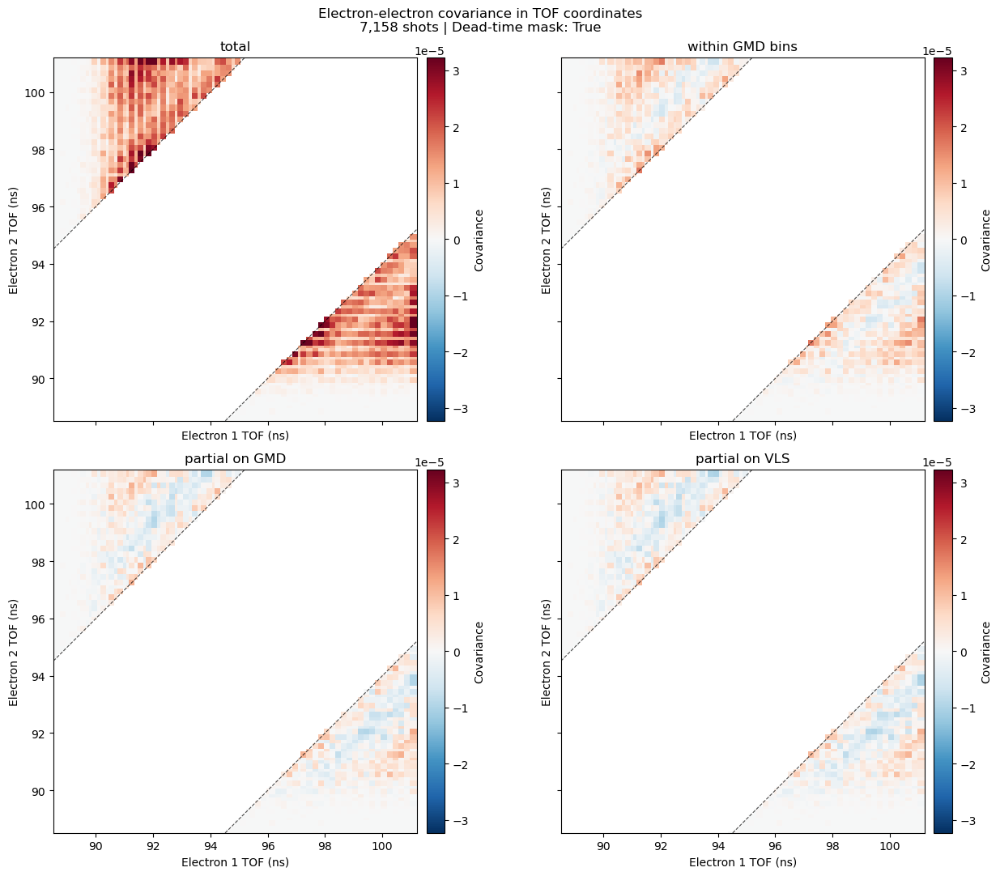

In [271]:
# ---- Electron-electron covariance in TOF coordinates ------------------

MASK_DEAD_TIME = True       # False: inspect the excluded region too
TOF_DENSITY = False         # True: covariance density per ns²

# Recover the original TOF bin edges, retaining the covariance rebinning.
cov_tof_edges = rebin_edges(
    axes['tof_edges'][::-1] / 10, REBIN_E
)[::-1]

cov_dtof = np.diff(cov_tof_edges)

cov_tof_lim = tuple(sorted(
    calibration.tof_of_ke(np.asarray(COV_KE_LIM))
))

assert len(cov_tof_edges) == ne + 1

inside = (
    (cov_ke >= COV_KE_LIM[0]) &
    (cov_ke <= COV_KE_LIM[1])
)[::-1]

methods = [
    'total',
    'within GMD bins',
    'partial on GMD',
    'partial on VLS'
]

maps_tof = {}

for name in methods:

    # Increasing TOF corresponds to decreasing kinetic energy.
    M = EST_AV[name]['DD'][::-1, ::-1].copy()

    if TOF_DENSITY:
        M /= np.outer(cov_dtof, cov_dtof)

    maps_tof[name] = M

band_tof = band[::-1, ::-1]

# Common colour scale, determined outside the dead-time region.
vmax = max(
    np.nanpercentile(
        np.abs(
            np.where(band_tof, np.nan, M)
            [np.ix_(inside, inside)]
        ),
        CLIP_PCT
    )
    for M in maps_tof.values()
)

fig, ax = plt.subplots(2, 2, figsize=(13, 11),
                       sharex=True, sharey=True)

for a, name in zip(ax.flat, methods):

    M = maps_tof[name]

    if MASK_DEAD_TIME:
        M = np.where(band_tof, np.nan, M)

    show_cov_map(
        a, M,
        cov_tof_edges, cov_tof_edges,
        vmax=vmax,
        label='Covariance / ns²' if TOF_DENSITY else 'Covariance'
    )

    # Lines of constant electron arrival-time separation.
    t = np.linspace(*cov_tof_lim, 300)

    for dt in [-DEAD_TIME_NS, DEAD_TIME_NS]:
        a.plot(t, t + dt, 'k--', lw=0.8, alpha=0.7)

    a.set(
        title=name,
        xlabel='Electron 1 TOF (ns)',
        ylabel='Electron 2 TOF (ns)',
        xlim=cov_tof_lim,
        ylim=cov_tof_lim
    )

    a.set_aspect('equal')

fig.suptitle(
    f'Electron-electron covariance in TOF coordinates\n'
    f'{N:,.0f} shots | Dead-time mask: {MASK_DEAD_TIME}'
)

fig.tight_layout()
plt.show()

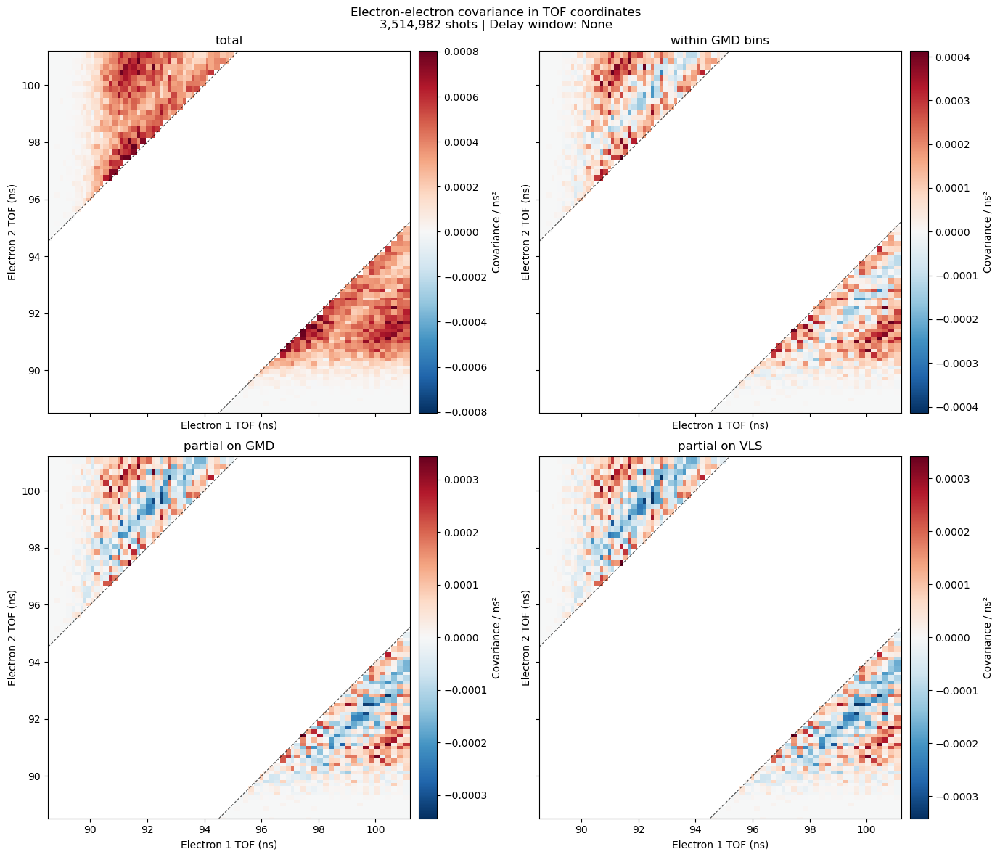

In [285]:
# ---- Electron-electron covariance in TOF coordinates ------------------


cov_tof_edges = rebin_edges(
    axes['tof_edges'][::-1] / 10, REBIN_E
)[::-1]




TOF_LIM =  cov_tof_lim         # None: full recorded TOF range; or (lo, hi) in ns
TOF_DELAY_WINDOW = None    # None: all delays; or (lo, hi) in fs

MASK_DEAD_TIME = True
TOF_DENSITY = True        # True: covariance per ns²
COMMON_SCALE = False       # True: same colour scale for all four maps

# Original TOF edges, retaining the covariance rebinning.
cov_tof_edges = rebin_edges(
    axes['tof_edges'][::-1] / 10, REBIN_E
)[::-1]

cov_dtof = np.diff(cov_tof_edges)
tof_centres = (cov_tof_edges[:-1] + cov_tof_edges[1:]) / 2

assert len(cov_tof_edges) == ne + 1
assert np.all(cov_dtof > 0)

tof_lim = (
    (cov_tof_edges[0], cov_tof_edges[-1])
    if TOF_LIM is None else TOF_LIM
)

inside = (
    (tof_centres >= tof_lim[0]) &
    (tof_centres <= tof_lim[1])
)

# Select delays independently of COV_DELAY_WINDOW.
mask = n_cov > 0

if TOF_DELAY_WINDOW is not None:
    lo, hi = TOF_DELAY_WINDOW
    mask &= (delay >= lo) & (delay < hi)

N_tof = n_cov[mask].sum()

if N_tof == 0:
    raise ValueError('No shots in selected delay window')

w_tof = n_cov[mask] / N_tof

methods = [
    'total',
    'within GMD bins',
    'partial on GMD',
    'partial on VLS'
]

maps_tof = {}

for name in methods:

    # Shot-weighted covariance over selected delays.
    M = np.tensordot(w_tof, EST[name]['DD'][mask], axes=1)

    # Reverse both axes: increasing KE -> increasing TOF.
    M = M[::-1, ::-1].copy()

    if TOF_DENSITY:
        M /= np.outer(cov_dtof, cov_dtof)

    maps_tof[name] = M

# Dead-time exclusion using actual TOF bin centres.
delta_tof = np.abs(
    tof_centres[:, None] - tof_centres[None, :]
)

band_tof = delta_tof <= DEAD_TIME_NS

# Determine colour scales outside the dead-time region.
vmax = {}

for name, M in maps_tof.items():

    region = np.where(band_tof, np.nan, M)
    region = region[np.ix_(inside, inside)]
    finite = np.abs(region[np.isfinite(region)])

    v = np.percentile(finite, CLIP_PCT) if finite.size else 1.0
    vmax[name] = v if v > 0 else 1.0

if COMMON_SCALE:
    vmax = dict.fromkeys(methods, max(vmax.values()))

fig, ax = plt.subplots(2, 2, figsize=(14, 12),
                       sharex=True, sharey=True)

for a, name in zip(ax.flat, methods):

    M = maps_tof[name]

    if MASK_DEAD_TIME:
        M = np.where(band_tof, np.nan, M)

    show_cov_map(
        a, M,
        cov_tof_edges, cov_tof_edges,
        vmax=vmax[name],
        label='Covariance / ns²' if TOF_DENSITY else 'Covariance'
    )

    # Constant TOF separation lines.
    t = np.linspace(*tof_lim, 300)

    for dt in [-DEAD_TIME_NS, DEAD_TIME_NS]:
        a.plot(t, t + dt, 'k--', lw=0.8, alpha=0.7)

    a.set(
        title=name,
        xlabel='Electron 1 TOF (ns)',
        ylabel='Electron 2 TOF (ns)',
        xlim=tof_lim,
        ylim=tof_lim
    )

    a.set_aspect('equal')

fig.suptitle(
    f'Electron-electron covariance in TOF coordinates\n'
    f'{N_tof:,.0f} shots | Delay window: {TOF_DELAY_WINDOW}'
)

fig.tight_layout()
plt.show()

### 9.4 Delay-integrated electron–ion covariance

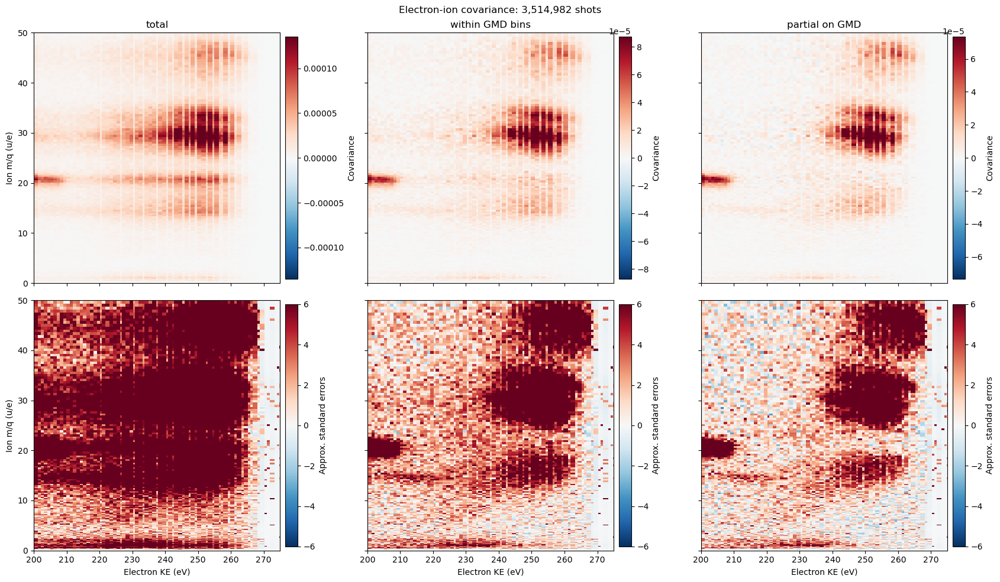

In [263]:
# ---- Delay-integrated electron-ion covariance -------------------------------

fig, ax = plt.subplots(2, 3, figsize=(17, 10),
                       sharex=True, sharey=True)

inside_e = ((cov_ke >= COV_KE_LIM[0]) &
            (cov_ke <= COV_KE_LIM[1]))

inside_i = ((cov_mq >= COV_MQ_LIM[0]) &
            (cov_mq <= COV_MQ_LIM[1]))

for k, (name, E) in enumerate(EST_AV.items()):

    M = E['DC']

    vmax = np.nanpercentile(
        np.abs(M[np.ix_(inside_e, inside_i)]), CLIP_PCT)

    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    show_cov_map(ax[0, k], M.T,
                 cov_ke_edges, cov_mq_edges,
                 vmax=vmax, label='Covariance')

    show_cov_map(ax[1, k], (M / E['se_DC']).T,
                 cov_ke_edges, cov_mq_edges,
                 vmax=Z_MAX, label='Approx. standard errors')

    ax[0, k].set_title(name)
    ax[1, k].set_xlabel('Electron KE (eV)')

for a in ax[:, 0]:
    a.set_ylabel('Ion m/q (u/e)')

for a in ax.flat:
    a.set(xlim=COV_KE_LIM, ylim=COV_MQ_LIM)

fig.suptitle(f'Electron-ion covariance: {N:,.0f} shots')
fig.tight_layout()
plt.show()

AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5: 1,169,112 shots used
AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5: 1,171,918 shots used
AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5: 1,173,952 shots used

Total shots used: 3,514,982


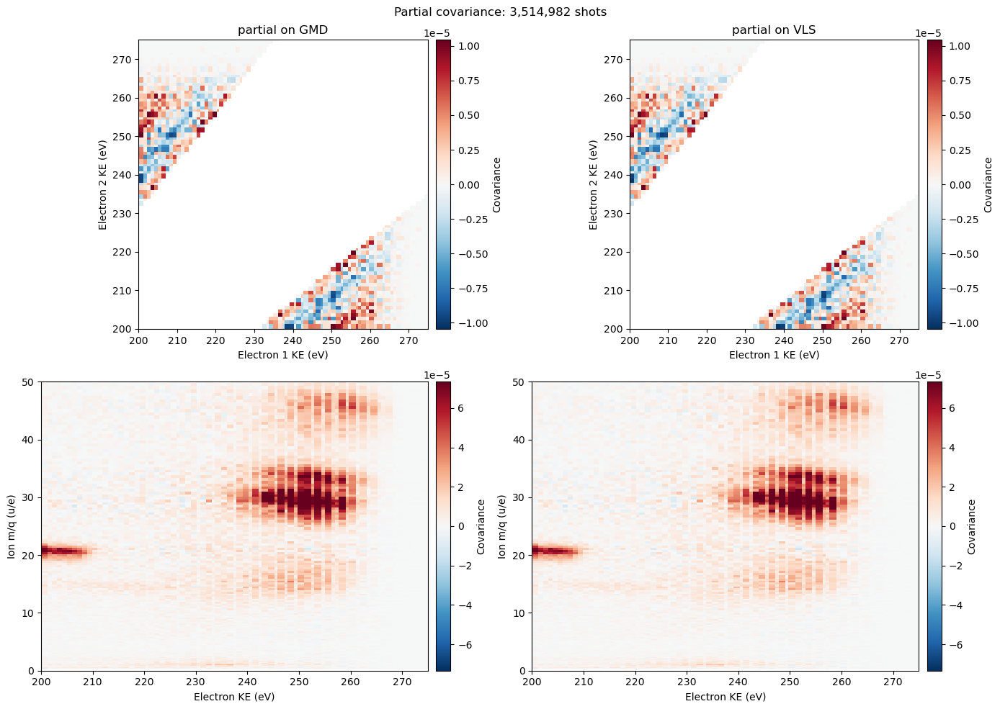

In [264]:

# ---- Partial covariance on integrated VLS intensity --------------------

EST_VLS = {
    key: M.copy()
    for key, M in EST['within GMD bins'].items()
}

vls_correction = {
    key: np.zeros_like(M)
    for key, M in EST_VLS.items()
}

n_vls_cov = np.zeros_like(n_cov)

for path in COV_FILES:

    with h5py.File(path, 'r') as f:

        for key in ['A', 'AtA', 'AtD', 'AtC']:
            if key not in f:
                raise KeyError(f'{path.name}: missing {key}')

        n = f['n_per_bin'][:]

        bins = (range(n.shape[0]) if COV_GMD_BINS is None
                else COV_GMD_BINS)

        n_used = 0

        for j in bins:
            for k in range(nz):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                # Retain exactly the same selection as section 9.1.
                G = f['G'][j, k]
                GG = f['GtG'][j, k]
                vG = GG - G**2

                if not np.isfinite(vG) or vG <= 0:
                    continue

                iz = k if DELAY_SIGN == 1 else nz - 1 - k

                # Recorded electron and ion first moments.
                D = rebin_vector(f['D'][j, k][::-1], idx_e)
                C = rebin_vector(f['C'][j, k], idx_i)

                # Integrated VLS intensity and its second moment.
                M = f['A'][j, k].sum()
                MM = f['AtA'][j, k].sum()

                vM = MM - M**2

                if not np.isfinite(vM) or vM <= 0:
                    raise ValueError(
                        f'{path.name}: invalid VLS variance '
                        f'in cell ({j}, {k})'
                    )

                # Electron-VLS and ion-VLS second moments.
                DM = rebin_vector(
                    f['AtD'][j, k].sum(axis=0)[::-1],
                    idx_e
                )

                CM = rebin_vector(
                    f['AtC'][j, k].sum(axis=0),
                    idx_i
                )

                cDM = DM - D * M
                cCM = CM - C * M

                # Linear contribution from VLS intensity fluctuations.
                vls_correction['DD'][iz] += (
                    N * np.outer(cDM, cDM) / vM
                )

                vls_correction['CC'][iz] += (
                    N * np.outer(cCM, cCM) / vM
                )

                vls_correction['DC'][iz] += (
                    N * np.outer(cDM, cCM) / vM
                )

                n_vls_cov[iz] += N
                n_used += N

    print(f'{path.name}: {n_used:,.0f} shots used')


# Verify that the GMD and VLS estimators use identical statistics.
np.testing.assert_array_equal(n_vls_cov, n_cov)

# Subtract the shot-weighted VLS contribution.
for key in ['DD', 'CC', 'DC']:

    EST_VLS[key] -= divide(
        vls_correction[key],
        n_cov[:, None, None]
    )

    EST_VLS[key][n_cov == 0] = np.nan

EST['partial on VLS'] = EST_VLS


# ---- Delay-integrated covariance --------------------------------------

if COV_DELAY_WINDOW is None:
    mask = n_cov > 0
else:
    lo, hi = COV_DELAY_WINDOW
    mask = (delay >= lo) & (delay < hi) & (n_cov > 0)

N_vls = n_cov[mask].sum()

if N_vls == 0:
    raise ValueError('No shots in selected delay window')

w_vls = n_cov[mask] / N_vls

EST_AV['partial on VLS'] = {
    key: np.tensordot(w_vls, M[mask], axes=1)
    for key, M in EST_VLS.items()
}

print(f'\nTotal shots used: {N_vls:,.0f}')


# ---- Compare partial covariance on GMD and VLS ------------------------

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

inside_e = (
    (cov_ke >= COV_KE_LIM[0]) &
    (cov_ke <= COV_KE_LIM[1])
)

inside_i = (
    (cov_mq >= COV_MQ_LIM[0]) &
    (cov_mq <= COV_MQ_LIM[1])
)

methods = ['partial on GMD', 'partial on VLS']

# Common colour scales for a fair comparison.
vmax_ee = max(
    np.nanpercentile(
        np.abs(
            np.where(band, np.nan, EST_AV[name]['DD'])
            [np.ix_(inside_e, inside_e)]
        ),
        CLIP_PCT
    )
    for name in methods
)

vmax_ei = max(
    np.nanpercentile(
        np.abs(EST_AV[name]['DC'][np.ix_(inside_e, inside_i)]),
        CLIP_PCT
    )
    for name in methods
)

for j, name in enumerate(methods):

    E = EST_AV[name]

    # Electron-electron covariance.
    show_cov_map(
        ax[0, j],
        np.where(band, np.nan, E['DD']),
        cov_ke_edges, cov_ke_edges,
        vmax=vmax_ee,
        label='Covariance'
    )

    ax[0, j].set(
        title=name,
        xlabel='Electron 1 KE (eV)',
        ylabel='Electron 2 KE (eV)',
        xlim=COV_KE_LIM,
        ylim=COV_KE_LIM
    )

    ax[0, j].set_aspect('equal')

    # Electron-ion covariance.
    show_cov_map(
        ax[1, j],
        E['DC'].T,
        cov_ke_edges, cov_mq_edges,
        vmax=vmax_ei,
        label='Covariance'
    )

    ax[1, j].set(
        xlabel='Electron KE (eV)',
        ylabel='Ion m/q (u/e)',
        xlim=COV_KE_LIM,
        ylim=COV_MQ_LIM
    )

fig.suptitle(f'Partial covariance: {N_vls:,.0f} shots')
fig.tight_layout()
plt.show()

### 9.5 Covariance-gated spectra

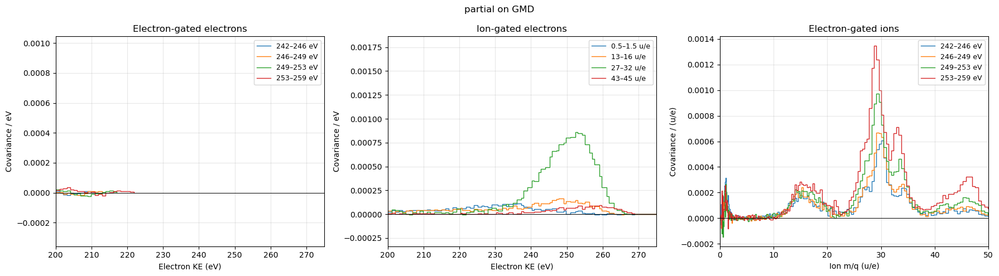

In [265]:
# ---- Covariance-filtered spectra --------------------------------------------





def in_win(centres, lo, hi):
    return (centres >= lo) & (centres < hi)


def ee_gated(M, gate):

    # Sum covariance over electron 1, excluding the diagonal band.
    valid = gate[:, None] & ~band

    spectrum = np.sum(np.where(valid, M, 0), axis=-2)
    spectrum[..., ~valid.any(axis=0)] = np.nan

    return spectrum


E = EST_AV[WINDOW_EST]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Electron spectra covarying with selected electrons.
for lo, hi in COV_E_WINDOWS:

    gate = in_win(cov_ke, lo, hi)
    if not gate.any():
        continue

    spectrum = ee_gated(E['DD'], gate)

    if COV_DENSITY:
        spectrum = spectrum / cov_dke

    ax[0].stairs(spectrum, cov_ke_edges, label=f'{lo}–{hi} eV')


# Electron spectra covarying with selected ions.
for lo, hi in COV_ION_WINDOWS:

    gate = in_win(cov_mq, lo, hi)
    if not gate.any():
        continue

    spectrum = E['DC'][:, gate].sum(axis=1)

    if COV_DENSITY:
        spectrum = spectrum / cov_dke

    ax[1].stairs(spectrum, cov_ke_edges, label=f'{lo}–{hi} u/e')


# Ion spectra covarying with selected electrons.
for lo, hi in COV_E_WINDOWS:

    gate = in_win(cov_ke, lo, hi)
    if not gate.any():
        continue

    spectrum = E['DC'][gate, :].sum(axis=0)

    if COV_DENSITY:
        spectrum = spectrum / cov_dmq

    ax[2].stairs(spectrum, cov_mq_edges, label=f'{lo}–{hi} eV')


ax[0].set(title='Electron-gated electrons',
          xlabel='Electron KE (eV)', xlim=COV_KE_LIM)

ax[1].set(title='Ion-gated electrons',
          xlabel='Electron KE (eV)', xlim=COV_KE_LIM)

ax[2].set(title='Electron-gated ions',
          xlabel='Ion m/q (u/e)', xlim=COV_MQ_LIM)

for k, a in enumerate(ax):
    ylabel = 'Covariance'
    if COV_DENSITY:
        ylabel += ' / eV' if k < 2 else ' / (u/e)'

    a.set_ylabel(ylabel)
    a.axhline(0, color='k', lw=0.7)
    a.legend(fontsize=9)
    a.grid(alpha=0.3)

fig.suptitle(WINDOW_EST)
fig.tight_layout()
plt.show()

### 9.6 Time-dependent covariance-gated spectra

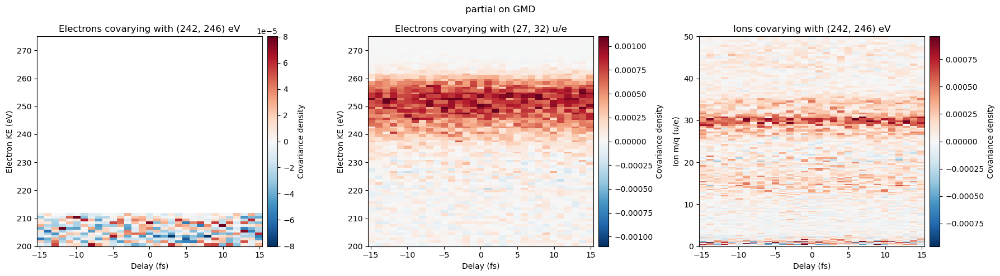

In [266]:
# ---- Time-dependent covariance-gated spectra -------------------------------


E = EST[WINDOW_EST]

gate_e = in_win(cov_ke, *E_GATE)
gate_i = in_win(cov_mq, *I_GATE)

if not gate_e.any() or not gate_i.any():
    raise ValueError('No bins in the selected gate')


# Delay x electron KE
Y_ee_cov = ee_gated(E['DD'], gate_e)

# Delay x electron KE
Y_ie_cov = E['DC'][:, :, gate_i].sum(axis=2)

# Delay x ion m/q
Y_ei_cov = E['DC'][:, gate_e, :].sum(axis=1)


fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for a, Y, edges, widths, centres, ylim, title, ylabel in zip(
    ax,
    [Y_ee_cov, Y_ie_cov, Y_ei_cov],
    [cov_ke_edges, cov_ke_edges, cov_mq_edges],
    [cov_dke, cov_dke, cov_dmq],
    [cov_ke, cov_ke, cov_mq],
    [COV_KE_LIM, COV_KE_LIM, COV_MQ_LIM],
    [
        f'Electrons covarying with {E_GATE} eV',
        f'Electrons covarying with {I_GATE} u/e',
        f'Ions covarying with {E_GATE} eV'
    ],
    ['Electron KE (eV)', 'Electron KE (eV)', 'Ion m/q (u/e)']
):

    M = Y / widths if COV_DENSITY else Y

    inside = (centres >= ylim[0]) & (centres <= ylim[1])

    vmax = np.nanpercentile(np.abs(M[:, inside]), CLIP_PCT)

    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0

    show_cov_map(a, M.T, delay_edges, edges,
                 vmax=vmax, label='Covariance density'
                 if COV_DENSITY else 'Covariance')

    a.set(xlabel='Delay (fs)', ylabel=ylabel,
          ylim=ylim, title=title)

fig.suptitle(WINDOW_EST)
fig.tight_layout()
plt.show()

### 9.7 Temporal traces of selected covariance regions

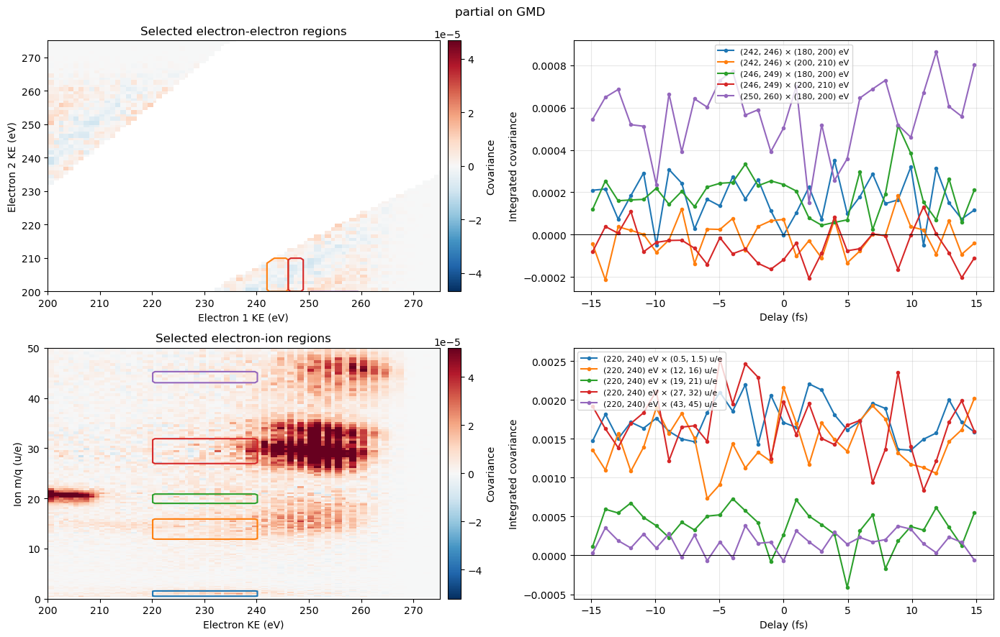

In [267]:
E = EST[WINDOW_EST]

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

cov_traces = {}


# Electron-electron covariance regions.
M = np.where(band, np.nan, EST_AV[WINDOW_EST]['DD'])

show_cov_map(ax[0, 0], M, cov_ke_edges, cov_ke_edges,
             label='Covariance')

X, Y = np.meshgrid(cov_ke, cov_ke, indexing='ij')

for j, (win1, win2) in enumerate(EE_ROIS):

    gate1 = in_win(cov_ke, *win1)
    gate2 = in_win(cov_ke, *win2)

    roi = (gate1[:, None] & gate2[None, :]) & ~band

    if not roi.any():
        print('Empty covariance ROI; skipped')
        continue

    if np.any(gate1 & gate2):
        raise ValueError('Use non-overlapping electron windows')

    signal = E['DD'][:, roi].sum(axis=1)

    if COV_NORMALISE_GMD:
        signal = divide(signal, mean_G_cov)

    label = f'{win1} × {win2} eV'
    cov_traces['EE', win1, win2] = signal

    ax[0, 0].contour(X, Y, roi.astype(float),
                     levels=[0.5], colors=[f'C{j}'])

    ax[0, 1].plot(delay, signal, '.-',
                  color=f'C{j}', label=label)


# Electron-ion covariance regions.
show_cov_map(ax[1, 0], EST_AV[WINDOW_EST]['DC'].T,
             cov_ke_edges, cov_mq_edges,
             label='Covariance')

X, Y = np.meshgrid(cov_ke, cov_mq, indexing='ij')

for j, (win_e, win_i) in enumerate(EI_ROIS):

    gate_e = in_win(cov_ke, *win_e)
    gate_i = in_win(cov_mq, *win_i)

    roi = gate_e[:, None] & gate_i[None, :]

    if not roi.any():
        print('Empty covariance ROI; skipped')
        continue

    signal = E['DC'][:, roi].sum(axis=1)

    if COV_NORMALISE_GMD:
        signal = divide(signal, mean_G_cov)

    label = f'{win_e} eV × {win_i} u/e'
    cov_traces['EI', win_e, win_i] = signal

    ax[1, 0].contour(X, Y, roi.astype(float),
                     levels=[0.5], colors=[f'C{j}'])

    ax[1, 1].plot(delay, signal, '.-',
                  color=f'C{j}', label=label)


ax[0, 0].set(xlabel='Electron 1 KE (eV)',
             ylabel='Electron 2 KE (eV)',
             xlim=COV_KE_LIM, ylim=COV_KE_LIM,
             title='Selected electron-electron regions')

ax[1, 0].set(xlabel='Electron KE (eV)',
             ylabel='Ion m/q (u/e)',
             xlim=COV_KE_LIM, ylim=COV_MQ_LIM,
             title='Selected electron-ion regions')

for a in ax[:, 1]:

    a.set(xlabel='Delay (fs)',
          ylabel='Integrated covariance / GMD'
          if COV_NORMALISE_GMD else 'Integrated covariance')

    a.axhline(0, color='k', lw=0.7)
    a.legend(fontsize=8)
    a.grid(alpha=0.3)

fig.suptitle(WINDOW_EST)
fig.tight_layout()
plt.show()

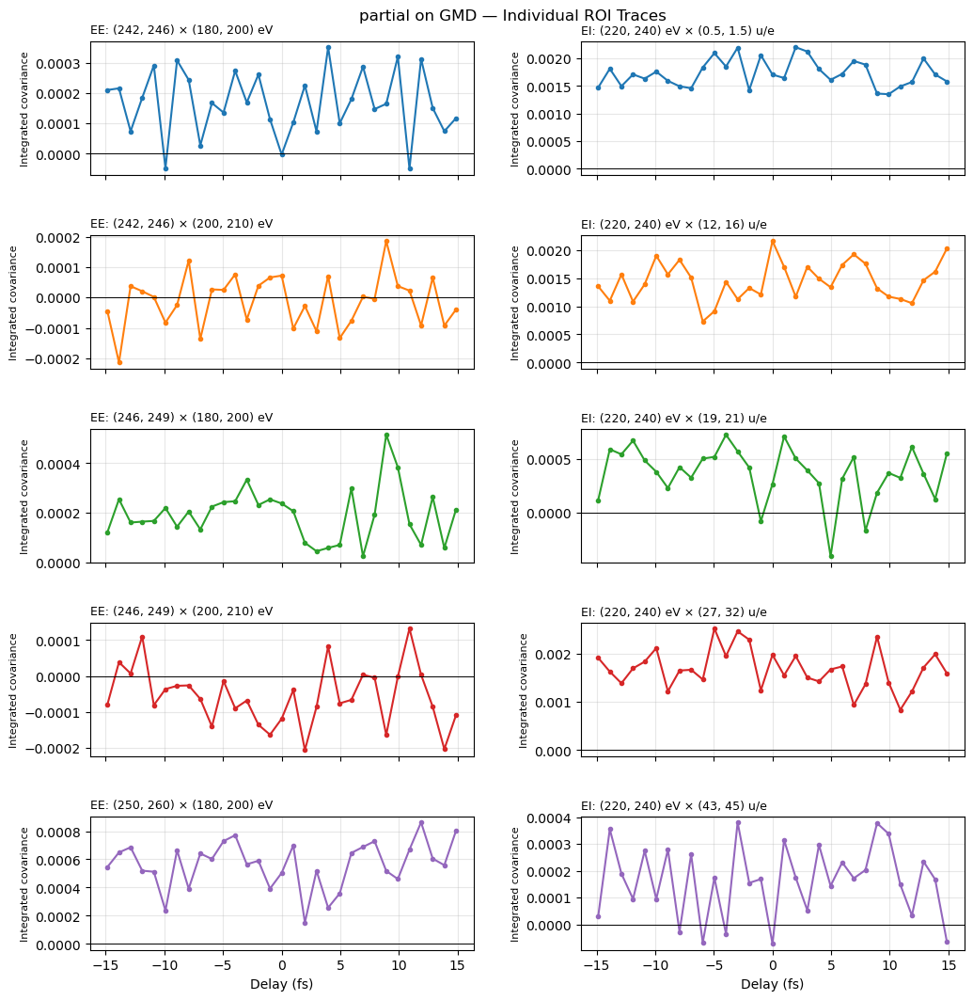

In [270]:
import matplotlib.gridspec as gridspec

# ---- Stacked temporal traces: Column 0 = EE ROIs, Column 1 = EI ROIs ------

ee_items = [
    (('EE', win1, win2), f'{win1} × {win2} eV', j)
    for j, (win1, win2) in enumerate(EE_ROIS)
    if ('EE', win1, win2) in cov_traces
]

ei_items = [
    (('EI', win_e, win_i), f'{win_e} eV × {win_i} u/e', j)
    for j, (win_e, win_i) in enumerate(EI_ROIS)
    if ('EI', win_e, win_i) in cov_traces
]

n_ee = len(ee_items)
n_ei = len(ei_items)
n_rows = max(n_ee, n_ei, 1)

ylabel_trace = (
    'Covariance / GMD' if COV_NORMALISE_GMD else 'Integrated covariance'
)

fig = plt.figure(figsize=(12, 2.3 * n_rows))
gs = gridspec.GridSpec(n_rows, 2, figure=fig, hspace=0.45, wspace=0.28)

for r, (key, label, color_idx) in enumerate(ee_items):
  ax_t = fig.add_subplot(gs[r, 0])
  ax_t.plot(delay, cov_traces[key], '.-', color=f'C{color_idx}')
  ax_t.set_title(f'EE: {label}', fontsize=9, loc='left')
  ax_t.set_ylabel(ylabel_trace, fontsize=8)
  ax_t.axhline(0, color='k', lw=0.7)
  ax_t.grid(alpha=0.3)
  if r < n_ee - 1:
    ax_t.set_xticklabels([])
  else:
    ax_t.set_xlabel('Delay (fs)')

for r, (key, label, color_idx) in enumerate(ei_items):
  ax_t = fig.add_subplot(gs[r, 1])
  ax_t.plot(delay, cov_traces[key], '.-', color=f'C{color_idx}')
  ax_t.set_title(f'EI: {label}', fontsize=9, loc='left')
  ax_t.set_ylabel(ylabel_trace, fontsize=8)
  ax_t.axhline(0, color='k', lw=0.7)
  ax_t.grid(alpha=0.3)
  if r < n_ei - 1:
    ax_t.set_xticklabels([])
  else:
    ax_t.set_xlabel('Delay (fs)')

fig.suptitle(f'{WINDOW_EST} — Individual ROI Traces')
fig.subplots_adjust(top=0.95)
plt.show()

### 9.8 Run-by-run electron–electron covariance and pair statistics

A selected pair of electron windows is checked separately in each scan. This cell reads only the relevant blocks of the second moments. It retains the original, more conservative dead-time mask: the minimum separation between the two original TOF bins must exceed `DEAD_TIME_NS`. It therefore need not give exactly the same result as the centre-based mask in the maps above (or if the maps are rebinned). The pair count is the detected same-shot pair moment, before accidental-background subtraction.

Photoelectron ROI: (242, 246) eV
Second electron ROI: (180, 200) eV
Dead-time mask: 6.0 ns
ROI pixels retained: 100.0%
Files selected: 1

AcH_short_delay_scan_268.7eV_2809924372_aggregates_tr.h5
  Shots: 1,129,259
  Detected pairs: 2,856


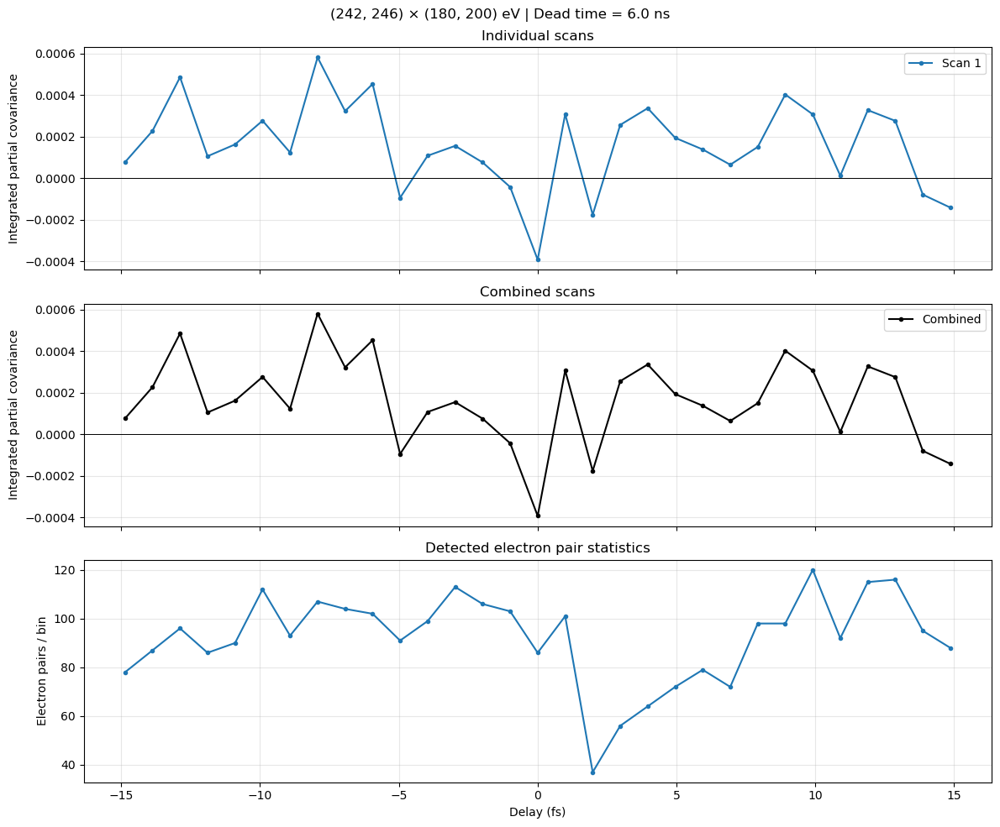


Total shots: 1,129,259
Total detected pairs: 2,856


In [52]:
# ---- Parameters --------------------------------------------------------

files = COV_FILES

# ---- Calibrated axes ---------------------------------------------------

with h5py.File(files[0], 'r') as f:
    pair_tof_edges = f['tof_edges'][:] / 10
    pair_z_edges = f['z_edges'][:]

pair_ke_edges = calibration.ke_of_tof(pair_tof_edges)
pair_ke = (pair_ke_edges[:-1] + pair_ke_edges[1:]) / 2

pair_delay_edges = DELAY_SIGN * (pair_z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
pair_delay = (pair_delay_edges[:-1] + pair_delay_edges[1:]) / 2

# Select the electron gates in the original TOF axis order.
gate1 = (pair_ke >= PHOTOELECTRON_ROI[0]) & (pair_ke < PHOTOELECTRON_ROI[1])
gate2 = (pair_ke >= PAIR_SECOND_ROI[0]) & (pair_ke < PAIR_SECOND_ROI[1])

idx1 = np.flatnonzero(gate1)
idx2 = np.flatnonzero(gate2)

if not idx1.size or not idx2.size:
    raise ValueError('Empty electron gate')

sl1 = slice(idx1[0], idx1[-1] + 1)
sl2 = slice(idx2[0], idx2[-1] + 1)

# ---- Dead-time mask ----------------------------------------------------

tof_lo = np.minimum(pair_tof_edges[:-1], pair_tof_edges[1:])
tof_hi = np.maximum(pair_tof_edges[:-1], pair_tof_edges[1:])

min_dt = np.maximum(
    tof_lo[sl1, None] - tof_hi[None, sl2],
    tof_lo[None, sl2] - tof_hi[sl1, None])

min_dt = np.maximum(min_dt, 0)

roi = min_dt > DEAD_TIME_NS

if not roi.any():
    raise ValueError('Entire ROI excluded by dead-time mask')

print(f'Photoelectron ROI: {PHOTOELECTRON_ROI} eV')
print(f'Second electron ROI: {PAIR_SECOND_ROI} eV')
print(f'Dead-time mask: {DEAD_TIME_NS} ns')
print(f'ROI pixels retained: {100 * roi.mean():.1f}%')
print(f'Files selected: {len(files)}\n')

# ---- Calculate covariance independently for each scan -------------------

results = {}

for path in files:

    cov_sum = np.zeros(len(pair_delay))
    shot_sum = np.zeros(len(pair_delay))
    pair_sum = np.zeros(len(pair_delay))

    with h5py.File(path, 'r') as f:

        if (not np.array_equal(f['z_edges'][:], pair_z_edges)
            or not np.array_equal(f['tof_edges'][:] / 10, pair_tof_edges)):
            raise ValueError(f'{path.name}: incompatible bin edges')

        n = f['n_per_bin'][:]

        bins = range(n.shape[0]) if COV_GMD_BINS is None else COV_GMD_BINS

        for j in bins:
            for k in range(len(pair_delay)):

                N = n[j, k]

                if N < MIN_COV_SHOTS:
                    continue

                # First moments.
                D1 = f['D'][j, k, sl1].astype(float)
                D2 = f['D'][j, k, sl2].astype(float)
                G = float(f['G'][j, k])

                # Second moments: load only the selected ROI.
                DD = f['DtD'][j, k, sl1, sl2].astype(float)
                D1G = f['DtG'][j, k, sl1].astype(float)
                D2G = f['DtG'][j, k, sl2].astype(float)
                GG = float(f['GtG'][j, k])

                var_G = GG - G**2

                if not np.isfinite(var_G) or var_G <= 0:
                    continue

                # Ordinary covariance.
                cov_DD = DD - np.outer(D1, D2)

                # Covariance with GMD.
                cov_D1G = D1G - D1 * G
                cov_D2G = D2G - D2 * G

                # Partial covariance on GMD.
                pcov = cov_DD - np.outer(cov_D1G, cov_D2G) / var_G

                # Integrate the unmasked ROI and weight by shots.
                cov_sum[k] += N * pcov[roi].sum()
                pair_sum[k] += N * DD[roi].sum()
                shot_sum[k] += N

    trace = np.divide(
        cov_sum, shot_sum,
        out=np.full(len(pair_delay), np.nan),
        where=shot_sum > 0)

    results[path.name] = dict(
        trace=trace,
        cov_sum=cov_sum,
        shots=shot_sum,
        pairs=pair_sum)

    print(path.name)
    print(f'  Shots: {shot_sum.sum():,.0f}')
    print(f'  Detected pairs: {pair_sum.sum():,.0f}')

# ---- Combine scans -----------------------------------------------------

total_cov = np.sum([r['cov_sum'] for r in results.values()], axis=0)
total_shots = np.sum([r['shots'] for r in results.values()], axis=0)
total_pairs = np.sum([r['pairs'] for r in results.values()], axis=0)

combined_trace = np.divide(
    total_cov, total_shots,
    out=np.full(len(pair_delay), np.nan),
    where=total_shots > 0)

order = np.argsort(pair_delay)

# ---- Plot temporal traces ----------------------------------------------

fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for j, (name, r) in enumerate(results.items()):

    ax[0].plot(pair_delay[order], r['trace'][order], '.-',
               label=f'Scan {j+1}')

ax[1].plot(pair_delay[order], combined_trace[order], 'k.-',
           label='Combined')

ax[2].plot(pair_delay[order], total_pairs[order], '.-',
           color='C0')

ax[0].set_title('Individual scans')
ax[1].set_title('Combined scans')
ax[2].set_title('Detected electron pair statistics')

ax[0].set_ylabel('Integrated partial covariance')
ax[1].set_ylabel('Integrated partial covariance')
ax[2].set_ylabel('Electron pairs / bin')
ax[2].set_xlabel('Delay (fs)')

for a in ax[:2]:
    a.axhline(0, color='k', lw=0.7)
    a.legend()

for a in ax:
    a.grid(alpha=0.3)

fig.suptitle(
    f'{PHOTOELECTRON_ROI} × {PAIR_SECOND_ROI} eV | '
    f'Dead time = {DEAD_TIME_NS} ns')

fig.tight_layout()
plt.show()

print(f'\nTotal shots: {total_shots.sum():,.0f}')
print(f'Total detected pairs: {total_pairs.sum():,.0f}')

ee_roi_results = dict(delay=pair_delay[order],
                      scans={name: {key: value[order] for key, value in r.items()}
                             for name, r in results.items()},
                      combined=combined_trace[order],
                      shots=total_shots[order],
                      pairs=total_pairs[order])